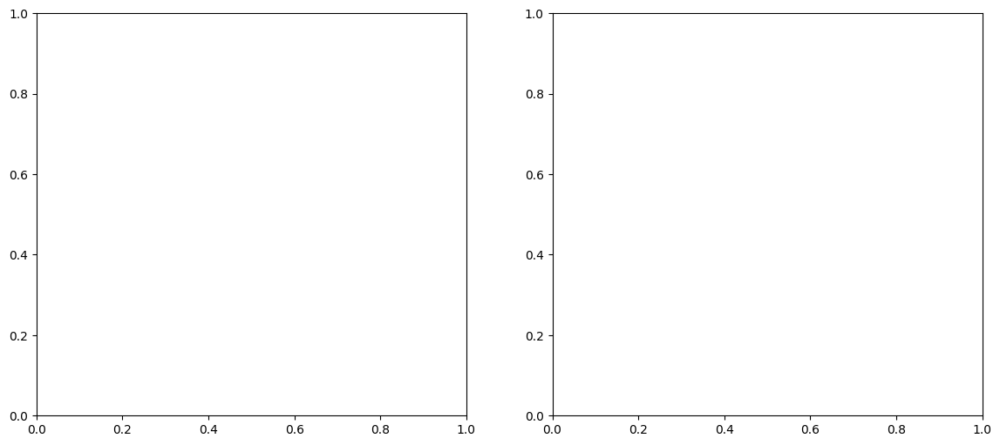

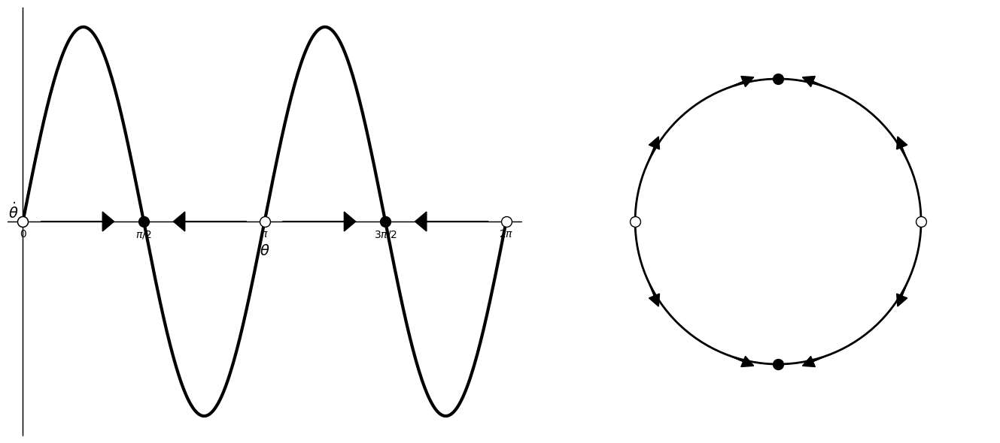

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definición de la función del campo vectorial
def f(theta):
    """Campo vectorial para la ecuación de Strogatz 4.1.3: d(theta)/dt = sin(2*theta)"""
    return np.sin(2 * theta)

# 2. Parámetros
theta_vals = np.linspace(0, 2 * np.pi, 300) # Más puntos para suavizar la curva
velocidad = f(theta_vals)

# Puntos fijos (en radianes) y su clasificación
puntos_fijos = [0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi] # Incluimos 2pi para cerrar el ciclo visualmente
# Clasificación: Inestable (fuente) -> círculo blanco, Estable (sumidero) -> círculo negro
# Corresponde a f'(theta*) > 0 para inestable y f'(theta*) < 0 para estable
tipos_punto = ['white', 'black', 'white', 'black', 'white'] # Colores de los marcadores para la línea de fase

# 3. Creación de la figura con dos subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6)) # Dos subplots: uno para la línea, otro para el círculo

# --- Subplot 1: Línea de Fase 1D ---
ax1 = axes[0]

import numpy as np
import matplotlib.pyplot as plt

# 1. Definición de la función del campo vectorial
def f(theta):
    """Campo vectorial para la ecuación de Strogatz 4.1.3: d(theta)/dt = sin(2*theta)"""
    return np.sin(2 * theta)

# 2. Parámetros
theta_vals = np.linspace(0, 2 * np.pi, 300) # Más puntos para suavizar la curva
velocidad = f(theta_vals)

# Puntos fijos (en radianes) y su clasificación
puntos_fijos = [0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi] # Incluimos 2pi para cerrar el ciclo visualmente
# Clasificación: Inestable (fuente) -> círculo blanco, Estable (sumidero) -> círculo negro
# Corresponde a f'(theta*) > 0 para inestable y f'(theta*) < 0 para estable
tipos_punto = ['white', 'black', 'white', 'black', 'white'] # Colores de los marcadores para la línea de fase

# 3. Creación de la figura con dos subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6)) # Dos subplots: uno para la línea, otro para el círculo

# --- Subplot 1: Línea de Fase 1D ---
ax1 = axes[0]

# Graficar la función f(theta)
ax1.plot(theta_vals, velocidad, color='black', linewidth=3)
ax1.axhline(0, color='black', linewidth=1) # Eje horizontal para el equilibrio
ax1.axvline(0, color='black', linewidth=1) # Eje vertical (opcional, para imitar el estilo)

# Marcar y clasificar los puntos fijos
for i, pf in enumerate(puntos_fijos):
    edgecolor = 'black'
    facecolor = tipos_punto[i]
    if pf == 2*np.pi: # Aseguramos que 2pi se vea como 0
        ax1.plot(0, 0, marker='o', markersize=10, linestyle='None',
                 markeredgecolor=edgecolor, markerfacecolor=facecolor, zorder=5)
    ax1.plot(pf, 0, marker='o', markersize=10, linestyle='None',
             markeredgecolor=edgecolor, markerfacecolor=facecolor, zorder=5)

# Añadir flechas para indicar la dirección del flujo
intervalos = np.array(puntos_fijos)
for i in range(len(intervalos) - 1):
    mid_point = (intervalos[i] + intervalos[i+1]) / 2
    direction = np.sign(f(mid_point))

    # Ajuste para que las flechas estén un poco más adentro de los intervalos
    segment_length = (intervalos[i+1] - intervalos[i])
    arrow_span = segment_length * 0.7 # La flecha ocupará el 70% del intervalo
    arrow_head_length = 0.15 # Longitud de la cabeza de la flecha

    if direction > 0: # Flecha hacia la derecha
        start_x = intervalos[i] + (segment_length - arrow_span) / 2
        ax1.arrow(start_x, 0, arrow_span - arrow_head_length, 0,
                  head_width=0.1, head_length=arrow_head_length, fc='black', ec='black', length_includes_head=True)
    else: # Flecha hacia la izquierda
        start_x = intervalos[i+1] - (segment_length - arrow_span) / 2
        ax1.arrow(start_x, 0, -(arrow_span - arrow_head_length), 0,
                  head_width=0.1, head_length=arrow_head_length, fc='black', ec='black', length_includes_head=True)


ax1.set_xlabel(r'$\theta$', fontsize=14)
ax1.set_ylabel(r'$\dot{\theta}$', fontsize=14, rotation=0, ha='right')
ax1.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
ax1.set_xticklabels([r'$0$', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])
ax1.set_xlim(-0.2, 2 * np.pi + 0.2)
ax1.set_ylim(-1.1, 1.1)
ax1.spines['left'].set_position(('data', 0))
ax1.spines['bottom'].set_position(('data', 0))
ax1.spines['right'].set_color('none')
ax1.spines['top'].set_color('none')
ax1.tick_params(axis='y', length=0) # Ocultar ticks del eje y
ax1.set_yticks([]) # Ocultar etiquetas del eje y


# --- Subplot 2: Círculo de Fase ---
ax2 = axes[1]
ax2.set_aspect('equal', adjustable='box')

# Dibujar el círculo base
circle = plt.Circle((0, 0), 1, color='black', fill=False, linewidth=2)
ax2.add_artist(circle)

# Marcar los puntos fijos en el círculo
for i, pf in enumerate(puntos_fijos[:-1]):
    x_pf = np.cos(pf)
    y_pf = np.sin(pf)
    edgecolor = 'black'
    facecolor = tipos_punto[i]
    ax2.plot(x_pf, y_pf, marker='o', markersize=10, linestyle='None',
             markeredgecolor=edgecolor, markerfacecolor=facecolor, zorder=5)

# Añadir flechas para indicar el flujo en el círculo
num_arrows = 8 # Menos flechas para evitar solapamiento
# Aseguramos que las flechas no estén justo encima de los puntos fijos
# y que haya espacio entre ellas
arrow_thetas_start = np.linspace(np.pi/8, 2*np.pi + np.pi/8, num_arrows, endpoint=False) # Desplazar el inicio

for arr_theta in arrow_thetas_start:
    # Ajustamos el punto donde se evalúa la dirección para que sea representativo del segmento
    mid_theta_eval = arr_theta + (2*np.pi/num_arrows)/2
    flow_direction = np.sign(f(mid_theta_eval))

    # Calcular la dirección de la tangente para la flecha
    tangent_x = -np.sin(arr_theta) * flow_direction
    tangent_y = np.cos(arr_theta) * flow_direction

    norm_tangent = np.sqrt(tangent_x**2 + tangent_y**2)
    tangent_x /= norm_tangent
    tangent_y /= norm_tangent

    # Ajustar tamaño de la flecha
    arrow_length = 0.15 # Más corta
    head_width = 0.08 # Más pequeña
    head_length = 0.08 # Más pequeña

    ax2.arrow(np.cos(arr_theta), np.sin(arr_theta), tangent_x * arrow_length, tangent_y * arrow_length,
              head_width=head_width, head_length=head_length, fc='black', ec='black', zorder=4)

ax2.set_xlim(-1.5, 1.5)
ax2.set_ylim(-1.5, 1.5)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['bottom'].set_visible(False)
ax2.spines['left'].set_visible(False)


plt.tight_layout()
plt.show()

# 5. Representación en el círculo (Opcional, requiere más complejidad)
# Este código simplificado muestra el retrato en la línea para entender el flujo.
# Una representación polar requiere más pasos para dibujar las flechas en el círculo.

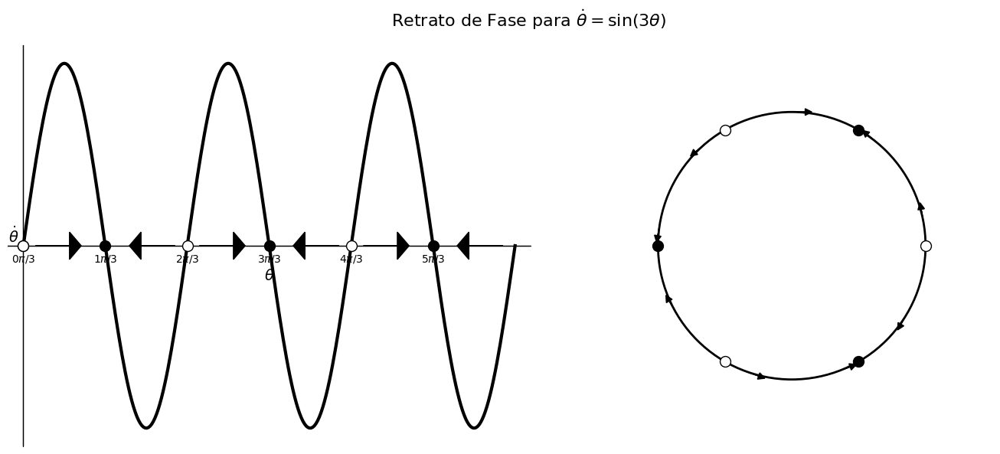

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Parámetro a Elegir ---
k = 3
# -------------------------

# 1. Definición de la función del campo vectorial
def f(theta, k_val):
    """Campo vectorial para la ecuación de Strogatz 4.1.7: d(theta)/dt = sin(k*theta)"""
    return np.sin(k_val * theta)

# 2. Puntos Fijos y Clasificación
theta_vals = np.linspace(0, 2 * np.pi, 300)
velocidad = f(theta_vals, k)

# Los puntos fijos son n*pi/k, para n=0, 1, ..., 2k
puntos_fijos_n = np.arange(0, 2 * k + 1)
puntos_fijos = puntos_fijos_n * np.pi / k

# Clasificación: 'white' (Inestable, n par), 'black' (Estable, n impar)
tipos_punto = ['black' if n % 2 != 0 else 'white' for n in puntos_fijos_n]


# 3. Creación de la figura con dos subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

fig.suptitle(rf'Retrato de Fase para $\dot{{\theta}} = \sin({k} \theta)$', fontsize=16)


# --- Subplot 1: Línea de Fase 1D ---
ax1 = axes[0]

# Graficar la función f(theta)
ax1.plot(theta_vals, velocidad, color='black', linewidth=3)
ax1.axhline(0, color='black', linewidth=1)
ax1.axvline(0, color='black', linewidth=1)

# Marcar y clasificar los puntos fijos
for i, pf in enumerate(puntos_fijos):
    if i < len(tipos_punto):
        edgecolor = 'black'
        facecolor = tipos_punto[i]

        plot_pf = 0 if np.isclose(pf, 2*np.pi) else pf
        ax1.plot(plot_pf, 0, marker='o', markersize=10, linestyle='None',
                 markeredgecolor=edgecolor, markerfacecolor=facecolor, zorder=5)

# Añadir flechas para indicar la dirección del flujo
intervalos = puntos_fijos[puntos_fijos <= 2*np.pi]
for i in range(len(intervalos) - 1):
    segment_length = intervalos[i+1] - intervalos[i]
    if segment_length < 1e-6: continue

    mid_point = (intervalos[i] + intervalos[i+1]) / 2
    direction = np.sign(f(mid_point, k))

    arrow_span = segment_length * 0.7
    arrow_head_length = 0.15 * (segment_length / (np.pi/k))

    if direction > 0: # Derecha
        start_x = intervalos[i] + (segment_length - arrow_span) / 2
        ax1.arrow(start_x, 0, arrow_span - arrow_head_length, 0,
                  head_width=0.15, head_length=arrow_head_length, fc='black', ec='black', length_includes_head=True)
    else: # Izquierda
        start_x = intervalos[i+1] - (segment_length - arrow_span) / 2
        ax1.arrow(start_x, 0, -(arrow_span - arrow_head_length), 0,
                  head_width=0.15, head_length=arrow_head_length, fc='black', ec='black', length_includes_head=True)

# Etiquetas y estilización
ax1.set_xlabel(r'$\theta$', fontsize=14)
ax1.set_ylabel(r'$\dot{\theta}$', fontsize=14, rotation=0, ha='right')
ax1.set_xticks(puntos_fijos[:-1])
ax1.set_xticklabels([f'${n}\\pi/{k}$' for n in puntos_fijos_n[:-1]])
ax1.set_xlim(-0.2, 2 * np.pi + 0.2)
ax1.set_ylim(-1.1, 1.1)
ax1.spines['left'].set_position(('data', 0))
ax1.spines['bottom'].set_position(('data', 0))
ax1.spines['right'].set_color('none')
ax1.spines['top'].set_color('none')
ax1.tick_params(axis='y', length=0)
ax1.set_yticks([])


# --- Subplot 2: Círculo de Fase ---
ax2 = axes[1]
ax2.set_aspect('equal', adjustable='box')

# Dibujar el círculo base
circle = plt.Circle((0, 0), 1, color='black', fill=False, linewidth=2)
ax2.add_artist(circle)

# Marcar los puntos fijos en el círculo
for i, pf in enumerate(puntos_fijos[:-1]):
    x_pf = np.cos(pf)
    y_pf = np.sin(pf)
    edgecolor = 'black'
    facecolor = tipos_punto[i]
    ax2.plot(x_pf, y_pf, marker='o', markersize=10, linestyle='None',
             markeredgecolor=edgecolor, markerfacecolor=facecolor, zorder=5)

# Añadir flechas para indicar el flujo en el círculo

# *** PARÁMETROS AJUSTADOS PARA EVITAR SOLAPAMIENTO ***
num_arrows = 3 * k # Reducido a 9 flechas para k=3
# El desplazamiento asegura que las flechas queden centradas en el arco
arrow_thetas_start = np.linspace(0, 2*np.pi, num_arrows, endpoint=False) + np.pi / (2 * num_arrows)

for arr_theta in arrow_thetas_start:
    flow_direction = np.sign(f(arr_theta, k))

    tangent_x = -np.sin(arr_theta) * flow_direction
    tangent_y = np.cos(arr_theta) * flow_direction

    norm_tangent = np.sqrt(tangent_x**2 + tangent_y**2)
    tangent_x /= norm_tangent
    tangent_y /= norm_tangent

    # Valores de tamaño más pequeños para una estética más limpia
    arrow_length = 0.10 # Más corto
    head_width = 0.05   # Más estrecho
    head_length = 0.05  # Más corto

    ax2.arrow(np.cos(arr_theta), np.sin(arr_theta), tangent_x * arrow_length, tangent_y * arrow_length,
              head_width=head_width, head_length=head_length, fc='black', ec='black', zorder=4)

ax2.set_xlim(-1.5, 1.5)
ax2.set_ylim(-1.5, 1.5)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['bottom'].set_visible(False)
ax2.spines['left'].set_visible(False)


plt.tight_layout()
plt.show()

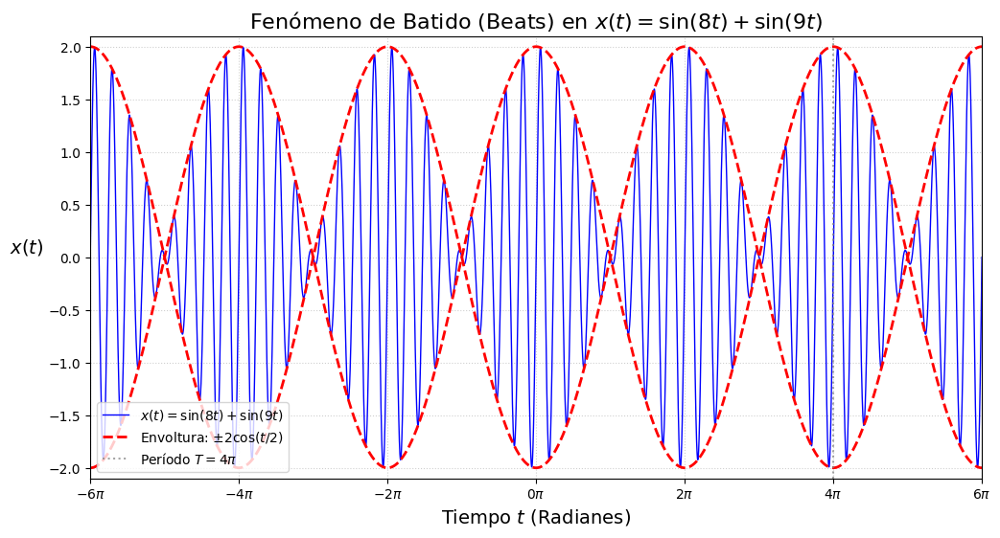

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definición de la función de oscilación
def x(t):
    """Función de superposición que produce batido: x(t) = sin(8t) + sin(9t)"""
    return np.sin(8 * t) + np.sin(9 * t)

# 2. Definición de la envoltura de modulación (Amplitud)
def a(t):
    """Envoltura de modulación: A(t) = 2 * cos(t/2)"""
    return 2 * np.cos(t / 2)

# 3. Parámetros de la gráfica
# El problema pide graficar de -20 < t < 20.
# Usamos un rango que sea un múltiplo de 2*pi (aprox. 6.28) para un mejor etiquetado.
t_inicio = -6 * np.pi  # -18.85
t_fin = 6 * np.pi      # 18.85
num_puntos = 10000     # Alta resolución para capturar la oscilación rápida

t = np.linspace(t_inicio, t_fin, num_puntos)
x_vals = x(t)
a_vals = a(t)

# 4. Configuración del eje x en múltiplos de pi
T_mod = 4 * np.pi  # Período de modulación
# Definimos los puntos de interés para las etiquetas del eje X: de -6pi a 6pi
pi_multiples = np.arange(-6, 7, 2) # Etiquetas cada 2*pi para claridad
x_ticks = pi_multiples * np.pi
x_labels = [f'${n}\\pi$' if n != 0 and n != 1 else ('$-\\pi$' if n == -1 else ('$\\pi$' if n == 1 else '$0$')) for n in pi_multiples]
x_labels = [f'${n}\\pi$' for n in pi_multiples] # Simplificando etiquetas a n*pi

# 5. Creación de la gráfica
plt.figure(figsize=(12, 6))

# Graficar la oscilación principal x(t)
plt.plot(t, x_vals, color='blue', linewidth=1, label=r'$x(t) = \sin(8t) + \sin(9t)$')

# Graficar la envoltura de amplitud (límites superior e inferior)
plt.plot(t, a_vals, color='red', linestyle='--', linewidth=2, label=r'Envoltura: $\pm 2 \cos(t/2)$')
plt.plot(t, -a_vals, color='red', linestyle='--', linewidth=2)

# Marcar el período de modulación (4pi)
plt.axvline(T_mod, color='gray', linestyle=':', alpha=0.7, label=r'Período $T=4\pi$')

# 6. Aplicar las etiquetas y ticks personalizados
plt.xticks(x_ticks, x_labels)

# 7. Etiquetas y título
plt.title(r'Fenómeno de Batido (Beats) en $x(t) = \sin(8t) + \sin(9t)$', fontsize=16)
plt.xlabel('Tiempo $t$ (Radianes)', fontsize=14)
plt.ylabel(r'$x(t)$', fontsize=14, rotation=0, ha='right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left')
plt.xlim(t_inicio, t_fin)
plt.ylim(-2.1, 2.1)

plt.show()

<>:71: SyntaxWarning: invalid escape sequence '\m'
<>:71: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipython-input-4141478127.py:71: SyntaxWarning: invalid escape sequence '\m'
  ax1.text(0.1, 0.9, f'$\mu = {mu}$', transform=ax1.transAxes)


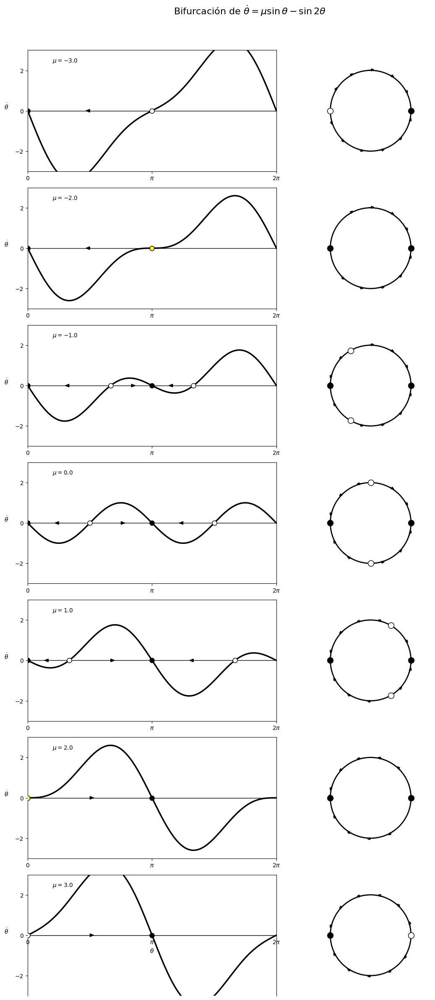

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definición de la función del campo vectorial
def f(theta, mu):
    """Campo vectorial: d(theta)/dt = mu*sin(theta) - sin(2*theta)"""
    return mu * np.sin(theta) - np.sin(2 * theta)

# Valores de mu a graficar, incluyendo los críticos mu=±2 y los de rotación.
mu_values = [-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0]

# Preparación de la figura
fig, axes = plt.subplots(len(mu_values), 2, figsize=(12, 3.5 * len(mu_values)))
fig.suptitle(r'Bifurcación de $\dot{\theta} = \mu \sin \theta - \sin 2\theta$', fontsize=16, y=1.0)

# Parámetros comunes
theta_vals = np.linspace(0, 2 * np.pi, 500)
line_color = 'black'
line_width = 2.5

# Derivada para la clasificación: f'(theta) = mu*cos(theta) - 2*cos(2*theta)
def f_prime(theta, mu):
    return mu * np.cos(theta) - 2 * np.cos(2 * theta)

# Bucle para graficar cada valor de mu
for i, mu in enumerate(mu_values):
    velocidad = f(theta_vals, mu)

    # --- Encontrar y Clasificar Puntos Fijos ---

    # Puntos críticos: theta* = 0, pi, arccos(mu/2), 2pi - arccos(mu/2)
    puntos_fijos_set = set()

    # 1. Soluciones de sin(theta) = 0: theta* = 0, pi
    for pf in [0.0, np.pi]:
        puntos_fijos_set.add(pf)

    # 2. Soluciones de cos(theta) = mu/2
    if abs(mu) < 2.0:
        theta_a = np.arccos(mu / 2)
        puntos_fijos_set.add(theta_a)
        puntos_fijos_set.add(2 * np.pi - theta_a)

    puntos_fijos = sorted(list(puntos_fijos_set))
    puntos_fijos = [pf for pf in puntos_fijos if pf < 2*np.pi or np.isclose(pf, 2*np.pi)]

    clasificacion = []

    for pf in puntos_fijos:
        derivada = f_prime(pf, mu)
        if abs(derivada) < 1e-5:
            # En la bifurcación (mu=±2), es un nodo silla degenerado (marginal)
            clasificacion.append('saddle_node')
        elif derivada > 0:
            clasificacion.append('white') # Inestable (Fuente)
        else:
            clasificacion.append('black') # Estable (Sumidero)

    # ----------------------------------------------------
    # --- Subplot 1: Campo Vectorial (theta vs d(theta)/dt) ---
    ax1 = axes[i, 0]
    ax1.plot(theta_vals, velocidad, color=line_color, linewidth=line_width)
    ax1.axhline(0, color='black', linewidth=1) # Eje horizontal grueso
    ax1.set_xlim(0, 2 * np.pi)
    ax1.set_ylim(-3, 3)
    ax1.set_xticks([0, np.pi, 2 * np.pi])
    ax1.set_xticklabels([r'$0$', r'$\pi$', r'$2\pi$'])
    ax1.set_yticks([-2, 0, 2])
    ax1.set_ylabel(r'$\dot{\theta}$', rotation=0, labelpad=15)

    ax1.text(0.1, 0.9, f'$\mu = {mu}$', transform=ax1.transAxes)

    # Marcar puntos fijos (sin flechas)
    for pf, color in zip(puntos_fijos, clasificacion):
        if color == 'white':
            ax1.plot(pf, 0, 'o', markersize=8, markeredgecolor='black', markerfacecolor='white', zorder=5)
        elif color == 'black':
            ax1.plot(pf, 0, 'o', markersize=8, markeredgecolor='black', markerfacecolor='black', zorder=5)
        elif color == 'saddle_node':
            # Los nodos silla se dibujan como un punto blanco o negro tocando el eje horizontal
             ax1.plot(pf, 0, 'o', markersize=8, markeredgecolor='black', markerfacecolor='yellow', zorder=5) # Usamos amarillo para distinguirlos

    # Agregar flechas de flujo en el eje theta (simplificado)
    intervalos = sorted(list(puntos_fijos))
    if len(intervalos) > 1:
        for k in range(len(intervalos) - 1):
            mid_point = (intervalos[k] + intervalos[k+1]) / 2
            direction = np.sign(f(mid_point, mu))
            arrow_pos = (intervalos[k] + intervalos[k+1]) / 2

            # Dibujar flechas EN el eje horizontal para indicar la dirección
            if abs(f(mid_point, mu)) > 0.05: # Solo si hay flujo
                if direction > 0:
                    ax1.arrow(arrow_pos, 0, 0.001, 0, head_width=0.15, head_length=0.1, fc='black', ec='black', width=0.001)
                else:
                    ax1.arrow(arrow_pos, 0, -0.001, 0, head_width=0.15, head_length=0.1, fc='black', ec='black', width=0.001)


    if i == len(mu_values) - 1:
        ax1.set_xlabel(r'$\theta$')
        ax1.spines['bottom'].set_position('zero') # Mover eje x a y=0

    # ----------------------------------------------------
    # --- Subplot 2: Círculo de Fase ---
    ax2 = axes[i, 1]
    ax2.set_aspect('equal', adjustable='box')

    circle_plot = plt.Circle((0, 0), 1, color='black', fill=False, linewidth=2)
    ax2.add_artist(circle_plot)

    # Marcar puntos fijos en el círculo
    for pf, color in zip(puntos_fijos, clasificacion):
        x_pf = np.cos(pf)
        y_pf = np.sin(pf)
        facecolor = 'white' if color == 'white' else 'black'

        ax2.plot(x_pf, y_pf, marker='o', markersize=10, linestyle='None',
                 markeredgecolor='black', markerfacecolor=facecolor, zorder=5)

    # Añadir flechas de flujo en el círculo
    num_arrows = 12
    arrow_thetas = np.linspace(0, 2*np.pi, num_arrows, endpoint=False) + np.pi / (2 * num_arrows)

    for arr_theta in arrow_thetas:
        flow = f(arr_theta, mu)
        flow_direction = np.sign(flow)

        if abs(flow) < 0.1: continue

        tangent_x = -np.sin(arr_theta) * flow_direction
        tangent_y = np.cos(arr_theta) * flow_direction

        norm_tangent = np.sqrt(tangent_x**2 + tangent_y**2)
        tangent_x /= norm_tangent
        tangent_y /= norm_tangent

        arrow_length = 0.15
        head_width = 0.06
        head_length = 0.06

        ax2.arrow(np.cos(arr_theta), np.sin(arr_theta), tangent_x * arrow_length, tangent_y * arrow_length,
                  head_width=head_width, head_length=head_length, fc='black', ec='black', zorder=4)

    ax2.set_xlim(-1.5, 1.5)
    ax2.set_ylim(-1.5, 1.5)
    ax2.set_xticks([])
    ax2.set_yticks([])
    ax2.axis('off') # Quitar todos los ejes

plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()

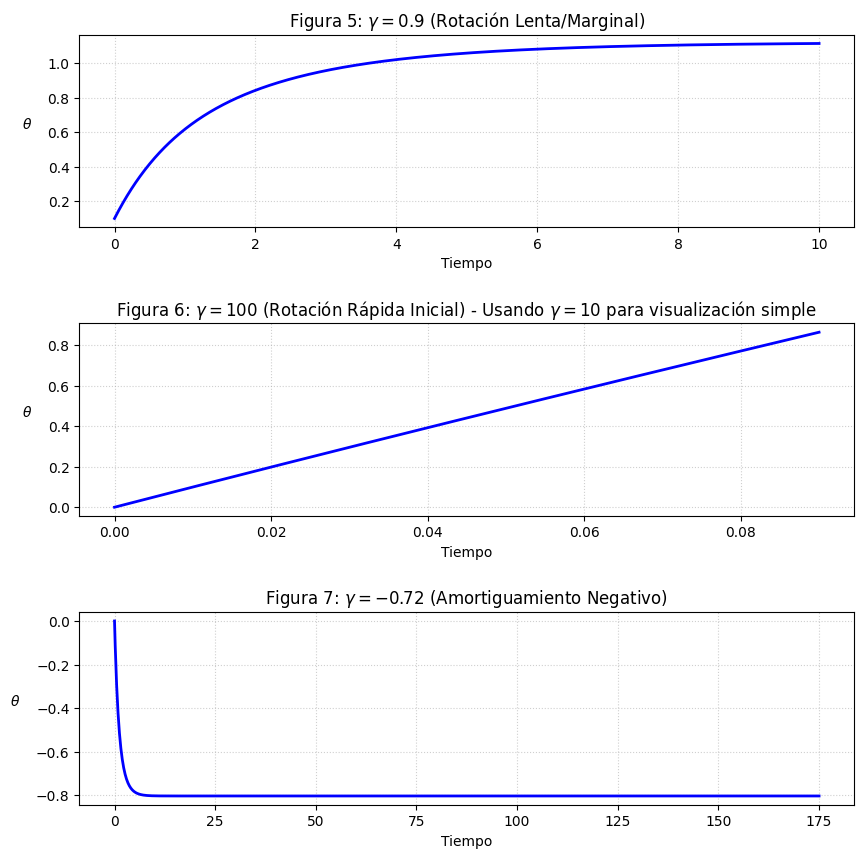

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# 1. Definición del sistema dinámico
def pendulum_ode(t, theta, gamma):
    """Ecuación del péndulo sobreamortiguado impulsado: d(theta)/dt = gamma - sin(theta)"""
    return gamma - np.sin(theta)

# 2. Definición de los casos a graficar
# Nota: Ajustamos los rangos de tiempo y condiciones iniciales para replicar las figuras 5, 6 y 7.
gamma_cases = [
    {
        'gamma': 0.9,
        't_span': [0, 10],
        'theta0': [0.1],
        'title': r'Figura 5: $\gamma = 0.9$ (Rotación Lenta/Marginal)',
        'color': 'blue'
    },
    {
        'gamma': 10.0,
        't_span': [0, 0.09], # Rango de tiempo muy corto para ver la rotación inicial
        'theta0': [0.0],
        'title': r'Figura 6: $\gamma = 100$ (Rotación Rápida Inicial) - Usando $\gamma=10$ para visualización simple', # Nota: Usar 100 causa una subida aún más rápida.
        'color': 'blue'
    },
    {
        'gamma': -0.72,
        't_span': [0, 175],
        'theta0': [0.0],
        'title': r'Figura 7: $\gamma = -0.72$ (Amortiguamiento Negativo)',
        'color': 'blue'
    }
]

# 3. Función para graficar la evolución de Theta
def plot_theta_evolution(gamma, t_span, theta0, title, ax, color):
    # Resolver la EDO
    sol = solve_ivp(
        pendulum_ode,
        t_span,
        theta0,
        args=(gamma,),
        dense_output=True,
        method='RK45',
        rtol=1e-8 # Alta precisión
    )

    # Evaluar la solución en puntos de tiempo densos
    t = np.linspace(t_span[0], t_span[1], 1000)
    theta = sol.sol(t)[0]

    # Graficar theta(t) vs. t
    ax.plot(t, theta, linewidth=2, color=color)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Tiempo')
    ax.set_ylabel(r'$\theta$', rotation=0, labelpad=15)
    ax.grid(True, linestyle=':', alpha=0.6)


# 4. Generar el multi-gráfico
fig, axs = plt.subplots(len(gamma_cases), 1, figsize=(10, 10))
plt.subplots_adjust(hspace=0.5)

for i, case in enumerate(gamma_cases):
    plot_theta_evolution(case['gamma'], case['t_span'], case['theta0'], case['title'], axs[i], case['color'])

plt.show()

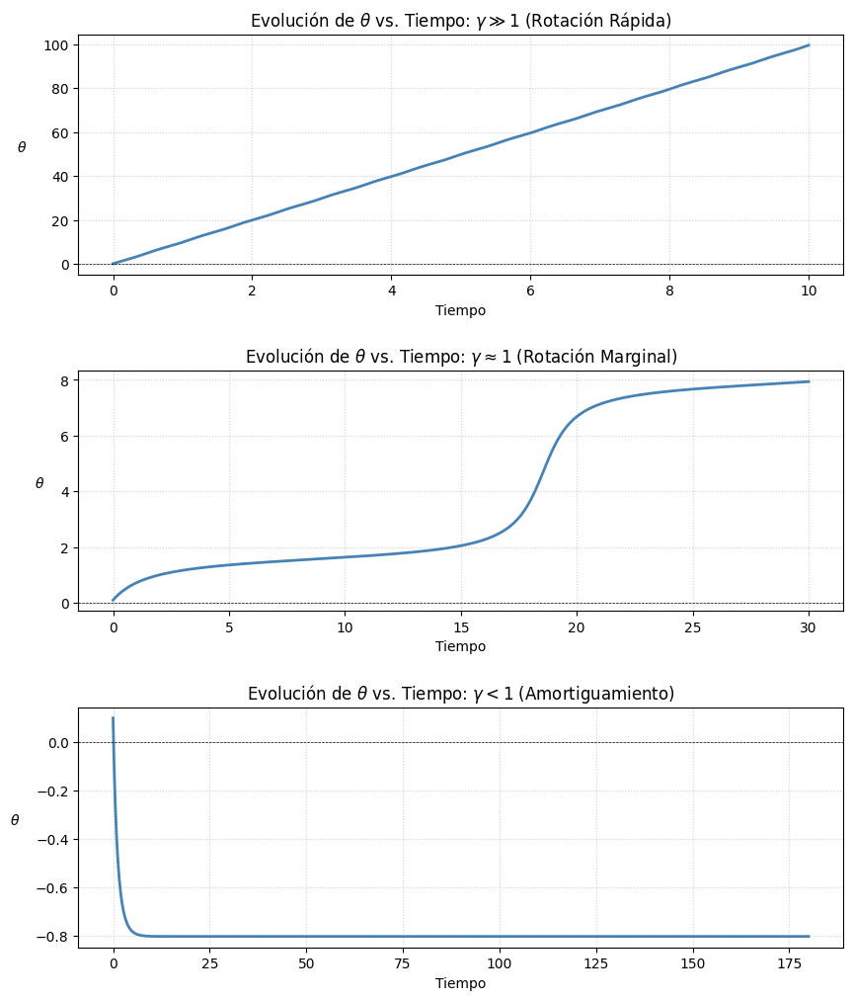

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# 1. Definición del sistema dinámico
def pendulum_ode(t, theta, gamma):
    """Ecuación del péndulo sobreamortiguado impulsado: d(theta)/dt = gamma - sin(theta)"""
    return gamma - np.sin(theta)

# 2. Parámetros de la simulación
theta0 = [0.1]       # Condición inicial (cercana al origen)

# Casos de gamma a graficar:
gamma_cases = [
    # Caso 1: Rotación Rápida (gamma >> 1) - Similar a tu Figura 6, pero extendido
    {'gamma': 10.0, 't_span': [0, 10], 'title': r'$\gamma \gg 1$ (Rotación Rápida)'},
    # Caso 2: Rotación Lenta/Marginal (gamma ≈ 1) - Similar a tu Figura 5
    {'gamma': 1.05, 't_span': [0, 30], 'title': r'$\gamma \approx 1$ (Rotación Marginal)'},
    # Caso 3: Amortiguamiento (gamma < 1) - Similar a tu Figura 7
    {'gamma': -0.72, 't_span': [0, 180], 'title': r'$\gamma < 1$ (Amortiguamiento)'}
]

# 3. Función para graficar los resultados
def plot_theta(gamma, t_span, title, ax):
    # Resolver la EDO usando RK4 (integración estándar)
    sol = solve_ivp(
        pendulum_ode,
        t_span,
        theta0,
        args=(gamma,),
        dense_output=True,
        method='RK45',
        rtol=1e-8 # Aumentar precisión para estabilidad
    )

    # Evaluar la solución en puntos de tiempo densos
    t = np.linspace(t_span[0], t_span[1], 1000)
    theta = sol.sol(t)[0]

    # Graficar theta(t) vs. t
    ax.plot(t, theta, linewidth=2, color='steelblue')
    ax.set_title(rf'Evolución de $\theta$ vs. Tiempo: {title}', fontsize=12)
    ax.set_xlabel('Tiempo')
    ax.set_ylabel(r'$\theta$', rotation=0, labelpad=15)
    ax.grid(True, linestyle=':', alpha=0.6)

    # Asegurar que el eje y=0 se vea si está en el rango
    if ax.get_ylim()[0] < 0 and ax.get_ylim()[1] > 0:
        ax.axhline(0, color='black', linestyle='--', linewidth=0.5)


# 4. Generar el multi-gráfico
fig, axs = plt.subplots(len(gamma_cases), 1, figsize=(10, 12))
plt.subplots_adjust(hspace=0.4)

for i, case in enumerate(gamma_cases):
    plot_theta(case['gamma'], case['t_span'], case['title'], axs[i])

plt.show()

<>:56: SyntaxWarning: invalid escape sequence '\s'
<>:56: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-72527422.py:56: SyntaxWarning: invalid escape sequence '\s'
  ax.axhline(gamma, color='black', linestyle='--', label=f'$\sin(\\theta) = \gamma = {gamma}$')


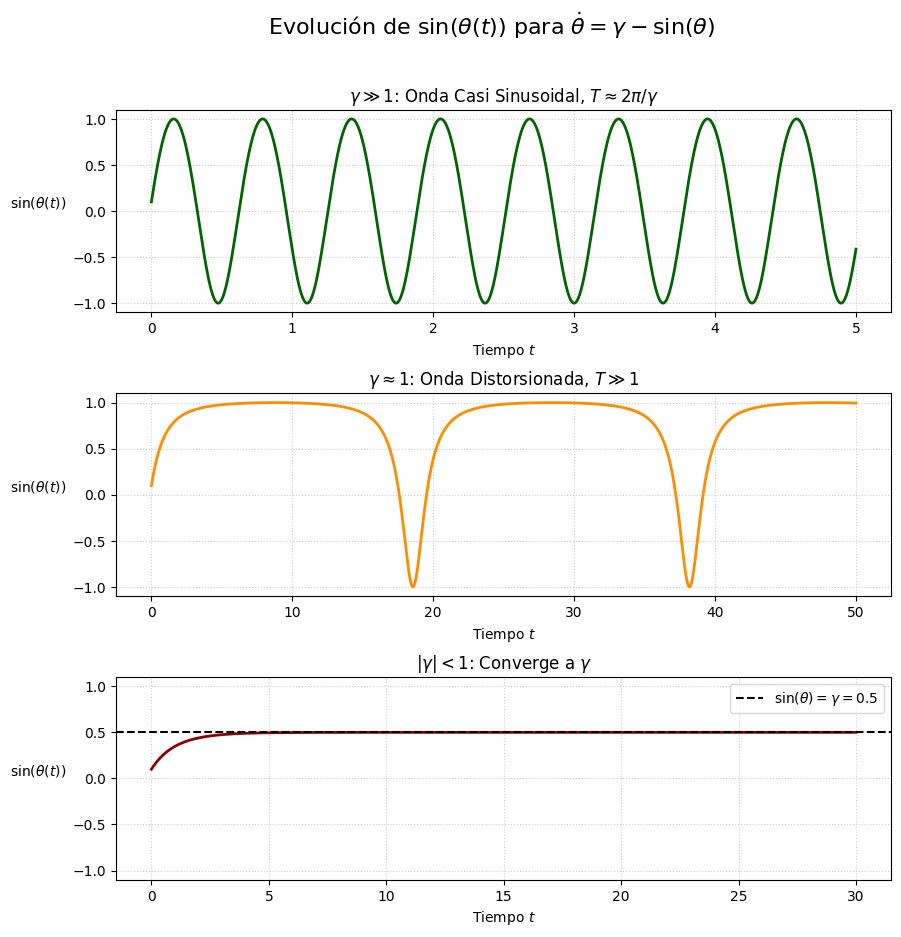

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# 1. Definición del sistema dinámico
def pendulum_ode(t, theta, gamma):
    """Ecuación del péndulo sobreamortiguado impulsado: d(theta)/dt = gamma - sin(theta)"""
    return gamma - np.sin(theta)

# 2. Parámetros y Regímenes de Gamma
theta0 = [0.1] # Condición inicial

gamma_cases = [
    # Caso 1: Rotación Rápida (gamma >> 1)
    {'gamma': 10.0, 't_span': [0, 5], 'title': r'$\gamma \gg 1$: Onda Casi Sinusoidal, $T \approx 2\pi/\gamma$', 'color': 'darkgreen'},
    # Caso 2: Rotación Marginal (gamma ≈ 1)
    {'gamma': 1.05, 't_span': [0, 50], 'title': r'$\gamma \approx 1$: Onda Distorsionada, $T \gg 1$', 'color': 'darkorange'},
    # Caso 3: Amortiguamiento (gamma < 1)
    {'gamma': 0.5, 't_span': [0, 30], 'title': r'$|\gamma| < 1$: Converge a $\gamma$', 'color': 'darkred'}
]

# 3. Generar el multi-gráfico
fig, axs = plt.subplots(len(gamma_cases), 1, figsize=(10, 10), sharex=False)
plt.subplots_adjust(hspace=0.4)
fig.suptitle(r'Evolución de $\sin(\theta(t))$ para $\dot{\theta} = \gamma - \sin(\theta)$', fontsize=16)

for i, case in enumerate(gamma_cases):
    gamma = case['gamma']
    t_span = case['t_span']

    # Resolver la EDO
    sol = solve_ivp(
        pendulum_ode,
        t_span,
        theta0,
        args=(gamma,),
        dense_output=True,
        method='RK45',
        rtol=1e-8
    )

    t = np.linspace(t_span[0], t_span[1], 1000)
    theta = sol.sol(t)[0]
    sin_theta = np.sin(theta)

    ax = axs[i]
    ax.plot(t, sin_theta, linewidth=2, color=case['color'])
    ax.set_title(case['title'], fontsize=12)
    ax.set_xlabel('Tiempo $t$')
    ax.set_ylabel(r'$\sin(\theta(t))$', rotation=0, labelpad=25)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.set_ylim(-1.1, 1.1)

    # Añadir la línea de convergencia para el caso amortiguado
    if abs(gamma) < 1:
        ax.axhline(gamma, color='black', linestyle='--', label=f'$\sin(\\theta) = \gamma = {gamma}$')
        ax.legend(loc='upper right')

plt.show()

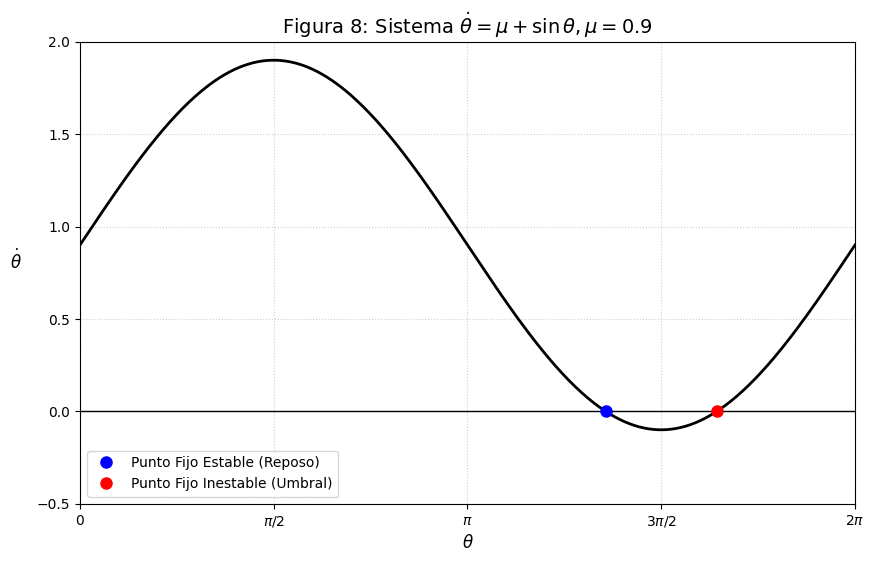

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parámetros
mu = 0.9

# 2. Definición del campo vectorial
def f_dot(theta, mu):
    """Campo vectorial: d(theta)/dt = mu + sin(theta)"""
    return mu + np.sin(theta)

# 3. Cálculo y Clasificación de Puntos Fijos
theta_fixed_stable = np.pi + np.arcsin(mu)  # Estable (Sumidero, f' < 0)
theta_fixed_unstable = 2 * np.pi - np.arcsin(mu) # Inestable (Fuente, f' > 0)

# 4. Preparación de la gráfica (Figura 8)
theta_vals = np.linspace(0, 2 * np.pi, 500)
dot_theta_vals = f_dot(theta_vals, mu)

plt.figure(figsize=(10, 6))
plt.plot(theta_vals, dot_theta_vals, color='black', linewidth=2)
plt.axhline(0, color='black', linewidth=1) # Eje del cero

# Marcar los puntos fijos
# Estable (Reposo)
plt.plot(theta_fixed_stable, 0, 'o', markersize=8, color='blue', label='Punto Fijo Estable (Reposo)', zorder=5)
# Inestable (Umbral)
plt.plot(theta_fixed_unstable, 0, 'o', markersize=8, color='red', label='Punto Fijo Inestable (Umbral)', zorder=5)

# Etiquetas y Título
plt.title(r'Figura 8: Sistema $\dot{\theta} = \mu + \sin \theta, \mu = 0.9$', fontsize=14)
plt.xlabel(r'$\theta$', fontsize=12)
plt.ylabel(r'$\dot{\theta}$', rotation=0, labelpad=15, fontsize=12)
plt.xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi],
           [r'$0$', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])
plt.xlim(0, 2 * np.pi)
plt.grid(True, linestyle=':', alpha=0.6)
plt.ylim(-0.5, 2.0)
plt.legend(loc='lower left', fontsize=10)
plt.show()

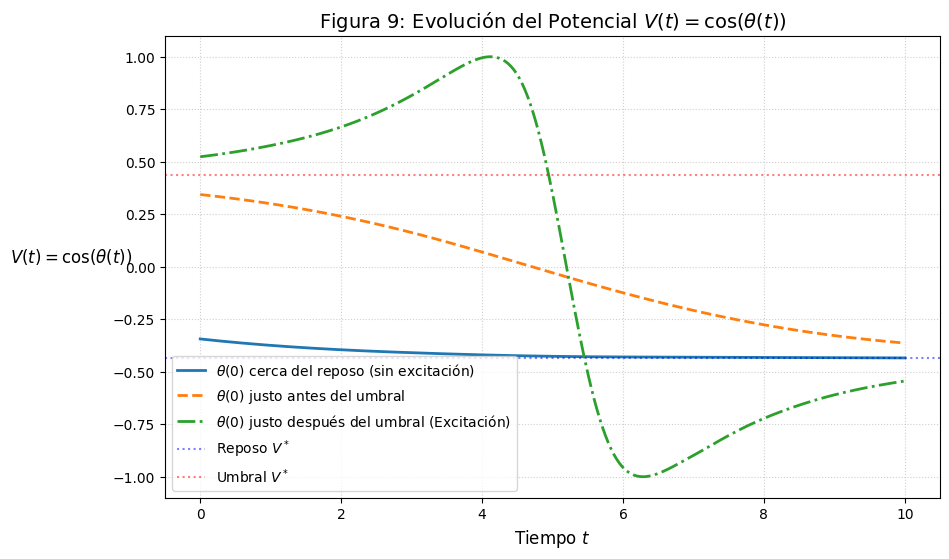

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# 1. Parámetros del sistema excitable
mu = 0.9
T_span = [0, 10]
t_eval = np.linspace(T_span[0], T_span[1], 500)

# Puntos fijos (para referencia de umbral)
theta_fixed_unstable = 2 * np.pi - np.arcsin(mu) # Umbral (rojo)
theta_fixed_stable = np.pi + np.arcsin(mu)     # Reposo (azul)

# 2. Definición del ODE
def f_dot(t, theta, mu):
    return mu + np.sin(theta)

# 3. Condiciones iniciales para demostrar la excitación
# El umbral está en theta_fixed_unstable ≈ 5.25 rad.
# Longitud del arco: 2*pi ≈ 6.28
initial_conditions = [
    # Cerca del reposo (sin excitación)
    {'theta0': [theta_fixed_stable + 0.1], 'label': r'$\theta(0)$ cerca del reposo (sin excitación)', 'linestyle': '-'},
    # Justo antes del umbral (relajación rápida)
    {'theta0': [theta_fixed_unstable - 0.1], 'label': r'$\theta(0)$ justo antes del umbral', 'linestyle': '--'},
    # Justo después del umbral (excitación/larga excursión)
    {'theta0': [theta_fixed_unstable + 0.1], 'label': r'$\theta(0)$ justo después del umbral (Excitación)', 'linestyle': '-.'}
]

# 4. Generación de la gráfica (Figura 9)
plt.figure(figsize=(10, 6))
plt.title(r'Figura 9: Evolución del Potencial $V(t) = \cos(\theta(t))$', fontsize=14)

for ic in initial_conditions:
    # Resolver la EDO
    sol = solve_ivp(f_dot, T_span, ic['theta0'], args=(mu,), t_eval=t_eval)

    # Calcular el potencial V(t)
    V_t = np.cos(sol.y[0])

    # Graficar
    plt.plot(sol.t, V_t, linewidth=2, label=ic['label'], linestyle=ic['linestyle'])

# Etiquetas y Ejes
plt.xlabel('Tiempo $t$', fontsize=12)
plt.ylabel(r'$V(t) = \cos(\theta(t))$', rotation=0, labelpad=30, fontsize=12)
plt.axhline(np.cos(theta_fixed_stable), color='blue', linestyle=':', alpha=0.5, label='Reposo $V^*$')
plt.axhline(np.cos(theta_fixed_unstable), color='red', linestyle=':', alpha=0.5, label='Umbral $V^*$')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left', fontsize=10)
plt.ylim(-1.1, 1.1)
plt.show()

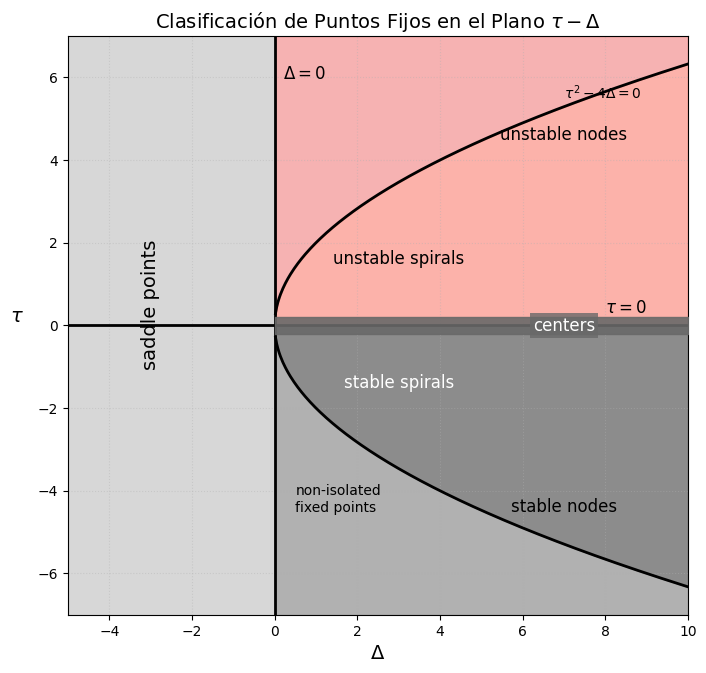

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definición del rango del diagrama
delta_min = -5
delta_max = 10
tau_min = -7 # Extender un poco para mejor visualización
tau_max = 7

# Crear un rango de Delta (eje x)
Delta = np.linspace(delta_min, delta_max, 500)

# Definición de la parábola crítica (tau^2 - 4*Delta = 0)
tau_parabola_upper = np.sqrt(4 * Delta[Delta >= 0])
tau_parabola_lower = -np.sqrt(4 * Delta[Delta >= 0])

# 2. Creación de la figura
plt.figure(figsize=(8, 8))
ax = plt.gca() # Obtener ejes actuales

# --- 3. Dibujar las Regiones y la Parábola ---

# A) Parábola: tau^2 - 4*Delta = 0
plt.plot(Delta[Delta >= 0], tau_parabola_upper, color='black', linewidth=2, zorder=3)
plt.plot(Delta[Delta >= 0], tau_parabola_lower, color='black', linewidth=2, zorder=3)
plt.text(7, np.sqrt(4*7) + 0.2, r'$\tau^2 - 4\Delta = 0$', fontsize=10)

# B) Línea Crítica de Estabilidad: tau = 0
plt.axhline(0, color='black', linewidth=2, zorder=3) # Eje Delta

# C) Línea Crítica de Puntos Fijos No Aislados: Delta = 0
plt.axvline(0, color='black', linewidth=2, zorder=3) # Eje Tau

# --- 4. Colorear y Etiquetar las Regiones ---

# 4.1. Región: Saddle Points (Silla) - Delta < 0
plt.fill_betweenx([tau_min, tau_max], delta_min, 0, color='lightgray', alpha=0.9, zorder=1)
plt.text(-3, 0.5, 'saddle points', fontsize=14, rotation=90, va='center', ha='center', zorder=2)

# 4.2. Región: Nodes & Spirals (Delta > 0)
Delta_positive = Delta[Delta >= 0]
tau_upper = np.sqrt(4 * Delta_positive)

# Stable Nodes (tau < 0, fuera de la parábola)
plt.fill_between(Delta_positive, tau_parabola_lower, tau_min, color='darkgray', alpha=0.9, zorder=1)
plt.text(7, -4.5, 'stable nodes', fontsize=12, ha='center')

# Unstable Nodes (tau > 0, fuera de la parábola)
plt.fill_between(Delta_positive, tau_parabola_upper, tau_max, color='lightcoral', alpha=0.6, zorder=1)
plt.text(7, 4.5, 'unstable nodes', fontsize=12, ha='center')

# Stable Spirals (tau < 0, dentro de la parábola)
plt.fill_between(Delta_positive, tau_parabola_lower, 0, where=(Delta_positive > 0), color='gray', alpha=0.9, zorder=1)
plt.text(3, -1.5, 'stable spirals', fontsize=12, ha='center', color='white')

# Unstable Spirals (tau > 0, dentro de la parábola)
plt.fill_between(Delta_positive, 0, tau_parabola_upper, where=(Delta_positive > 0), color='salmon', alpha=0.6, zorder=1)
plt.text(3, 1.5, 'unstable spirals', fontsize=12, ha='center')

# Centers (tau = 0, Delta > 0)
plt.fill_between(Delta_positive, -0.2, 0.2, where=(Delta_positive > 0), color='dimgray', alpha=0.9, zorder=4)
plt.text(7, 0, 'centers', fontsize=12, va='center', ha='center', color='white',
         bbox=dict(facecolor='dimgray', alpha=0.8, edgecolor='none', boxstyle="square,pad=0.2"), zorder=5)

# 4.3. Etiquetas de los Ejes Críticos
plt.text(delta_max * 0.9, 0.2, r'$\tau=0$', fontsize=12, va='bottom', ha='right')
plt.text(0.2, tau_max * 0.9, r'$\Delta=0$', fontsize=12, va='top', ha='left')
plt.text(0.5, -4.5, 'non-isolated\nfixed points', fontsize=10, ha='left') # Etiqueta para Delta=0

# 5. Configuración de Ejes y Título
plt.xlabel(r'$\Delta$', fontsize=14)
plt.ylabel(r'$\tau$', rotation=0, fontsize=14, labelpad=15)
plt.title(r'Clasificación de Puntos Fijos en el Plano $\tau-\Delta$', fontsize=14)
plt.xlim(delta_min, delta_max)
plt.ylim(tau_min, tau_max)
plt.grid(True, linestyle=':', alpha=0.4, zorder=0)
ax.set_aspect('equal', adjustable='box') # Usar aspect ratio

plt.show()

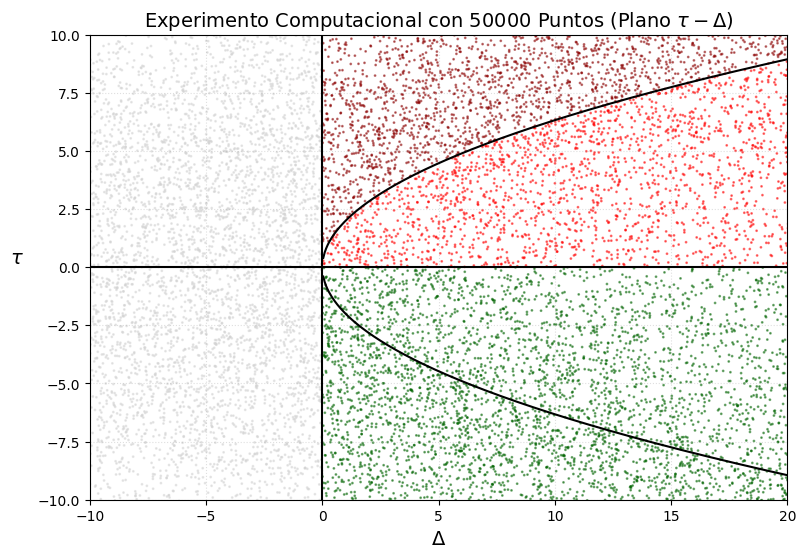

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parámetros del experimento
N = 50000  # Aumentamos a 50,000 matrices para mayor densidad
# Rango para las entradas de la matriz A
entry_range = 10

# Inicializar arrays para resultados
tau_results = np.zeros(N)
delta_results = np.zeros(N)
classification_colors = []

# 2. Bucle principal del experimento
for i in range(N):
    # Generar matriz A con entradas aleatorias
    A = np.random.uniform(-entry_range, entry_range, size=(2, 2))

    # Calcular Tau y Delta
    tau = np.trace(A)
    Delta = np.linalg.det(A)

    tau_results[i] = tau
    delta_results[i] = Delta

    # Calcular valores propios (lambda)
    discriminant = tau**2 - 4 * Delta

    color = 'gray' # Color predeterminado (no aislado/estrella)

    # Usamos una tolerancia pequeña para comparaciones con cero
    tol = 1e-3

    if Delta < -tol:
        # Puntos Silla (Delta < 0)
        color = 'lightgray'
    elif discriminant < -tol:
        # Espirales y Centros (Discriminante < 0)
        real_part = tau / 2
        if np.isclose(tau, 0, atol=tol):
            color = 'blue' # Centro (tau = 0)
        elif real_part < 0:
            color = 'darkgreen' # Espiral Estable (tau < 0)
        else:
            color = 'red' # Espiral Inestable (tau > 0)
    elif discriminant >= -tol:
        # Nodos y Estrellas (Discriminante >= 0)

        # Clasificación de Nodos/Estrellas
        if Delta < tol: # Cerca de Delta = 0 (Nodos Degenerados/Estrella)
             color = 'purple'
        else:
             # Clasificación de Nodos
             if tau < 0:
                 color = 'darkgreen' # Nodo Estable (tau < 0)
             else:
                 color = 'darkred' # Nodo Inestable (tau > 0)

    classification_colors.append(color)

# 3. Graficar los resultados del experimento
plt.figure(figsize=(9, 9))

# Graficar los puntos del experimento
plt.scatter(delta_results, tau_results, c=classification_colors, s=1, alpha=0.5)

# Dibujar las fronteras teóricas para referencia (Negro)
Delta_plot = np.linspace(-10, 20, 500)
tau_parabola = np.sqrt(4 * Delta_plot[Delta_plot >= 0])
plt.plot(Delta_plot[Delta_plot >= 0], tau_parabola, color='black', linewidth=1.5)
plt.plot(Delta_plot[Delta_plot >= 0], -tau_parabola, color='black', linewidth=1.5)
plt.axhline(0, color='black', linewidth=1.5)
plt.axvline(0, color='black', linewidth=1.5)

# Configuración del gráfico
plt.xlabel(r'$\Delta$', fontsize=14)
plt.ylabel(r'$\tau$', rotation=0, fontsize=14, labelpad=15)
plt.title(f'Experimento Computacional con {N} Puntos (Plano $\\tau-\\Delta$)', fontsize=14)
plt.xlim(-10, 20)
plt.ylim(-10, 10)
plt.grid(True, linestyle=':', alpha=0.4)
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

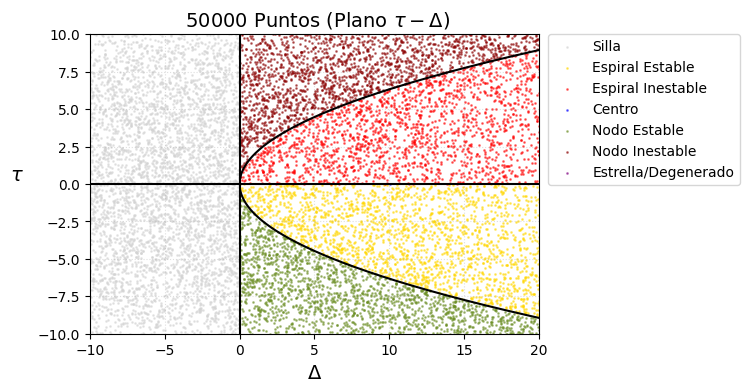

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parámetros del experimento
N = 50000  # Número de matrices
entry_range = 10

# Inicializar listas para almacenar resultados
tau_results = []
delta_results = []
classification_labels = []
classification_colors = []

# Diccionario para mapear etiquetas a colores para la leyenda
color_map_legend = {
    'Silla': 'lightgray',
    'Espiral Estable': 'gold',             # CAMBIO: Amarillo para Espiral Estable
    'Espiral Inestable': 'red',
    'Centro': 'blue',
    'Nodo Estable': 'olivedrab',          # CAMBIO: Verde-Amarillento para Nodo Estable
    'Nodo Inestable': 'darkred',
    'Estrella/Degenerado': 'purple',
    'No Clasificado': 'gray'
}

# 2. Bucle principal del experimento
for i in range(N):
    # Generar matriz A con entradas aleatorias
    A = np.random.uniform(-entry_range, entry_range, size=(2, 2))

    # Calcular Tau y Delta
    tau = np.trace(A)
    Delta = np.linalg.det(A)

    tau_results.append(tau)
    delta_results.append(Delta)

    # Calcular valores propios (lambda)
    discriminant = tau**2 - 4 * Delta

    label = 'No Clasificado'
    color = color_map_legend[label]

    tol = 1e-3

    if Delta < -tol:
        label = 'Silla'
        color = color_map_legend[label]
    elif discriminant < -tol: # Espirales y Centros
        real_part = tau / 2
        if np.isclose(tau, 0, atol=tol):
            label = 'Centro'
            color = color_map_legend[label]
        elif real_part < 0:
            label = 'Espiral Estable'
            color = color_map_legend[label]
        else:
            label = 'Espiral Inestable'
            color = color_map_legend[label]
    elif discriminant >= -tol: # Nodos y Estrellas
        if np.isclose(Delta, 0, atol=tol):
             label = 'Estrella/Degenerado'
             color = color_map_legend[label]
        else: # Nodos
             if tau < 0:
                 label = 'Nodo Estable'
                 color = color_map_legend[label]
             else:
                 label = 'Nodo Inestable'
                 color = color_map_legend[label]

    classification_labels.append(label)
    classification_colors.append(color)

# 3. Graficar los resultados del experimento
plt.figure(figsize=(9, 9))
ax = plt.gca()

# Graficar los puntos del experimento, agrupados por su etiqueta para la leyenda
for label, c in color_map_legend.items():
    if label == 'No Clasificado':
        continue

    # Obtener los índices de los puntos que corresponden a esta etiqueta
    indices = [idx for idx, l in enumerate(classification_labels) if l == label]

    if indices:
        plt.scatter(np.array(delta_results)[indices], np.array(tau_results)[indices],
                    c=c, s=1, alpha=0.5, label=label)

# Dibujar las fronteras teóricas para referencia (Negro)
Delta_plot = np.linspace(-10, 20, 500)
tau_parabola_upper = np.sqrt(4 * Delta_plot[Delta_plot >= 0])
tau_parabola_lower = -np.sqrt(4 * Delta_plot[Delta_plot >= 0])
plt.plot(Delta_plot[Delta_plot >= 0], tau_parabola_upper, color='black', linewidth=1.5, zorder=3)
plt.plot(Delta_plot[Delta_plot >= 0], tau_parabola_lower, color='black', linewidth=1.5, zorder=3)
plt.axhline(0, color='black', linewidth=1.5, zorder=3)
plt.axvline(0, color='black', linewidth=1.5, zorder=3)

# Configuración del gráfico
plt.xlabel(r'$\Delta$', fontsize=14)
plt.ylabel(r'$\tau$', rotation=0, fontsize=14, labelpad=15)
plt.title(f' {N} Puntos (Plano $\\tau-\\Delta$)', fontsize=14)
plt.xlim(-10, 20)
plt.ylim(-10, 10)
plt.grid(True, linestyle=':', alpha=0.4)
ax.set_aspect('equal', adjustable='box')

# Mostrar la leyenda
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0.)
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

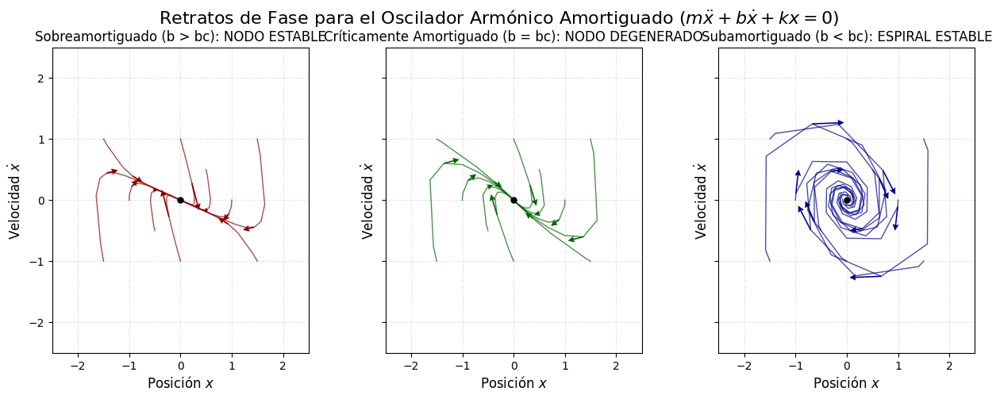

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# 1. Definición del sistema lineal
def damped_oscillator_ode(t, X, m, b, k):
    """Sistema Lineal 2D: X = [x, y], donde y = x_dot"""
    x, y = X
    x_dot = y
    y_dot = (-k/m) * x - (b/m) * y
    return [x_dot, y_dot]

# 2. Definición de las condiciones de amortiguamiento
# Fijamos m=1 y k=1 para simplificar. La condición crítica es b_c = sqrt(4mk) = 2.
m = 1.0
k = 1.0
b_c = 2.0

# Definición de las simulaciones a graficar
simulations = [
    # Caso 1: Sobreamortiguado (b > 2) -> Nodo Estable
    {'b': 3.0, 'title': 'Sobreamortiguado (b > bc): NODO ESTABLE', 'color': 'darkred'},
    # Caso 2: Críticamente Amortiguado (b = 2) -> Nodo Degenerado Estable
    {'b': 2.0, 'title': 'Críticamente Amortiguado (b = bc): NODO DEGENERADO', 'color': 'darkgreen'},
    # Caso 3: Subamortiguado (b < 2) -> Espiral Estable
    {'b': 0.5, 'title': 'Subamortiguado (b < bc): ESPIRAL ESTABLE', 'color': 'darkblue'},
]

# 3. Definición de las condiciones iniciales para las trayectorias
# Se eligen varias condiciones iniciales alrededor del origen
initial_conditions = [
    [1.0, 0.0], [0.0, 1.0], [-1.0, 0.0], [0.0, -1.0],
    [1.5, 1.0], [-1.5, 1.0], [1.5, -1.0], [-1.5, -1.0],
    [0.5, 0.5], [-0.5, -0.5]
]

# 4. Generación de la figura
fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.3)
fig.suptitle(r'Retratos de Fase para el Oscilador Armónico Amortiguado ($m\ddot{x} + b\dot{x} + kx = 0$)', fontsize=16)

t_span = [0, 10]

for i, sim in enumerate(simulations):
    b = sim['b']
    ax = axs[i]

    # Resolver y graficar trayectorias
    for X0 in initial_conditions:
        sol = solve_ivp(
            damped_oscillator_ode,
            t_span,
            X0,
            args=(m, b, k),
            dense_output=True
        )

        # Graficar la trayectoria
        ax.plot(sol.y[0], sol.y[1], color=sim['color'], linewidth=1, alpha=0.7)

        # Añadir flechas para indicar la dirección
        # Tomar un punto intermedio en la trayectoria para la flecha
        arrow_idx = len(sol.y[0]) // 4
        x_start, y_start = sol.y[0][arrow_idx], sol.y[1][arrow_idx]

        # Calcular la velocidad en ese punto para la dirección
        v = damped_oscillator_ode(0, [x_start, y_start], m, b, k)

        # Dibujar la flecha (quiver)
        ax.quiver(x_start, y_start, v[0], v[1], color=sim['color'],
                  scale=10, width=0.005, headwidth=5)

    # Marcar el punto fijo
    ax.plot(0, 0, 'o', color='black', markersize=5, zorder=5)

    # Títulos y Etiquetas
    ax.set_title(sim['title'], fontsize=12)
    ax.set_xlabel(r'Posición $x$', fontsize=12)
    ax.set_ylabel(r'Velocidad $\dot{x}$', fontsize=12)
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.show()

/tmp/ipython-input-2998147902.py:84: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.0, 0.05, 0.88, 0.95]) # Ajustar para el título y la barra de color


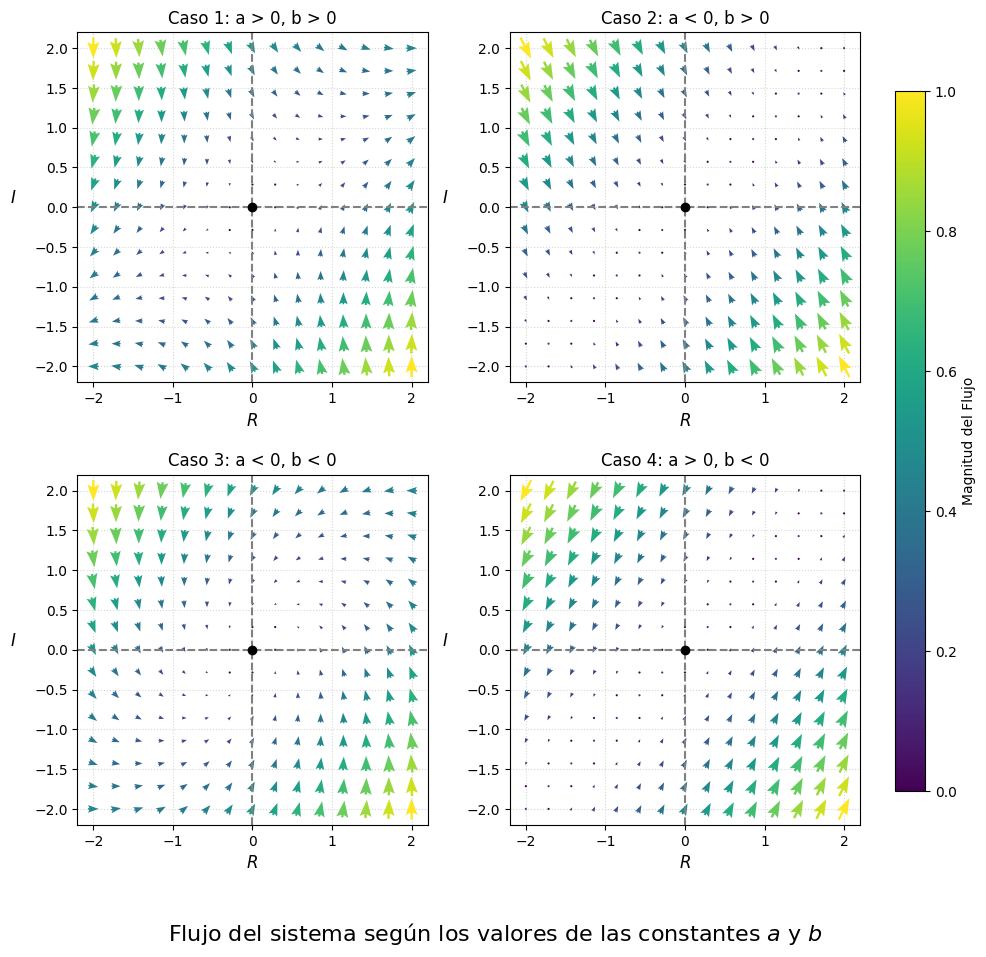

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definición del sistema de EDOs (Foco en R_dot = aR + bI)
def love_affair_system(R, I, a, b, c, d):
    """
    Sistema lineal general de dos variables (Romeo, Julieta):
    R_dot = aR + bI
    I_dot = cR + dI
    """
    R_dot = a * R + b * I
    I_dot = c * R + d * I
    return R_dot, I_dot

# 2. Definición de los Cuatro Estilos (Signos de a y b)
# Se asume I_dot = cR + dI con c y d fijos.
# Esto define la dinámica de Julieta, la mantenemos fija para aislar el efecto de a y b en Romeo.
c_fixed = 1.0
d_fixed = -1.0 # Por ejemplo, una Julieta que se excita si Romeo la quiere, pero se calma si el suyo propio es alto.

love_styles = [
    # 1. a > 0, b > 0
    {'a': 0.5, 'b': 0.5, 'case_label': 'Caso 1: a > 0, b > 0'},
    # 2. a < 0, b > 0
    {'a': -0.5, 'b': 0.5, 'case_label': 'Caso 2: a < 0, b > 0'},
    # 3. a < 0, b < 0
    {'a': -0.5, 'b': -0.5, 'case_label': 'Caso 3: a < 0, b < 0'},
    # 4. a > 0, b < 0
    {'a': 0.5, 'b': -0.5, 'case_label': 'Caso 4: a > 0, b < 0'}
]

# 3. Preparación de la Gráfica
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.flatten()

# Rango del plano fase (ajustado para que coincida con tu imagen)
R_range = np.linspace(-2, 2, 15) # Menos puntos para flechas más claras
I_range = np.linspace(-2, 2, 15)
R_grid, I_grid = np.meshgrid(R_range, I_range)

# 4. Bucle para graficar los cuatro estilos
for idx, style in enumerate(love_styles):
    a, b = style['a'], style['b']

    # Calcular los vectores del campo
    R_dot_grid, I_dot_grid = love_affair_system(R_grid, I_grid, a, b, c_fixed, d_fixed)

    # Calcular la magnitud de los vectores para el color
    M = np.hypot(R_dot_grid, I_dot_grid)
    M[M == 0] = 1.0 # Evitar división por cero

    ax = axes[idx]

    # Dibujar el campo vectorial (flujo)
    # Usamos cmap='viridis' o 'plasma' o 'magma' para el efecto de color.
    # El argumento 'color' de quiver, si se usa, debe ser un array con el mismo tamaño que M.
    # En este caso, al pasar M al argumento C (color), Matplotlib usará el cmap.
    ax.quiver(R_grid, I_grid, R_dot_grid, I_dot_grid,
              M, cmap='viridis', pivot='mid', units='xy', scale=15,
              width=0.03, headwidth=5, headlength=7, headaxislength=6, zorder=2)

    # Dibujar el punto fijo (Origen)
    ax.plot(0, 0, 'o', color='black', markersize=6, zorder=3)

    # Configuración de Ejes
    ax.set_title(style['case_label'], fontsize=12)
    ax.set_xlabel(r'$R$', fontsize=12)
    ax.set_ylabel(r'$I$', rotation=0, labelpad=15, fontsize=12)
    ax.axhline(0, color='gray', linestyle='--')
    ax.axvline(0, color='gray', linestyle='--')
    ax.set_xlim(-2.2, 2.2) # Ajustar límites para que se vea más parecido
    ax.set_ylim(-2.2, 2.2)
    ax.set_aspect('equal', 'box')
    ax.grid(True, linestyle=':', alpha=0.5)

# 5. Añadir una barra de color común (Colorbar)
fig.subplots_adjust(right=0.85) # Ajustar espacio para la barra de color
cbar_ax = fig.add_axes([0.9, 0.15, 0.03, 0.7]) # Posición de la barra de color
sm = plt.cm.ScalarMappable(cmap='viridis') # Crear un ScalarMappable para la barra
sm.set_array([]) # Necesita un array aunque no se use directamente para los valores
fig.colorbar(sm, cax=cbar_ax, label='Magnitud del Flujo')


plt.tight_layout(rect=[0.0, 0.05, 0.88, 0.95]) # Ajustar para el título y la barra de color
plt.suptitle(r'Flujo del sistema según los valores de las constantes $a$ y $b$', fontsize=16, y=0.02) # Título general
plt.show()

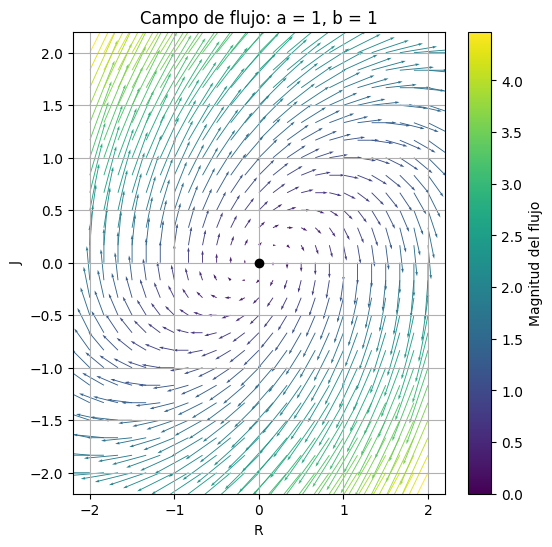

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Definimos el sistema: dR/dt = a*R + b*J, dJ/dt = -R + J (puedes ajustarlo)
def campo(R, J, a=1, b=1):
    dR = b * J
    dJ = -a * R + J
    return dR, dJ

# Rango de valores
R_vals = np.linspace(-2, 2, 25)
J_vals = np.linspace(-2, 2, 25)
R, J = np.meshgrid(R_vals, J_vals)

# Parámetros a y b (puedes cambiar para ver diferentes comportamientos)
a, b = 1, 1  # Caso 1: ambos positivos

# Calculamos el campo
dR, dJ = campo(R, J, a, b)

# Magnitud del flujo para el color
magnitud = np.sqrt(dR**2 + dJ**2)

# Creamos la figura
plt.figure(figsize=(6, 6))
plt.quiver(R, J, dR, dJ, magnitud, cmap='viridis', scale=20)
plt.xlabel('R')
plt.ylabel('J')
plt.title(f'Campo de flujo: a = {a}, b = {b}')
plt.colorbar(label='Magnitud del flujo')
plt.grid(True)
plt.plot(0, 0, 'ko')  # punto fijo en el origen
plt.show()


/tmp/ipython-input-314887880.py:32: RuntimeWarning: invalid value encountered in divide
  dR_n = dR / magnitud
/tmp/ipython-input-314887880.py:33: RuntimeWarning: invalid value encountered in divide
  dJ_n = dJ / magnitud


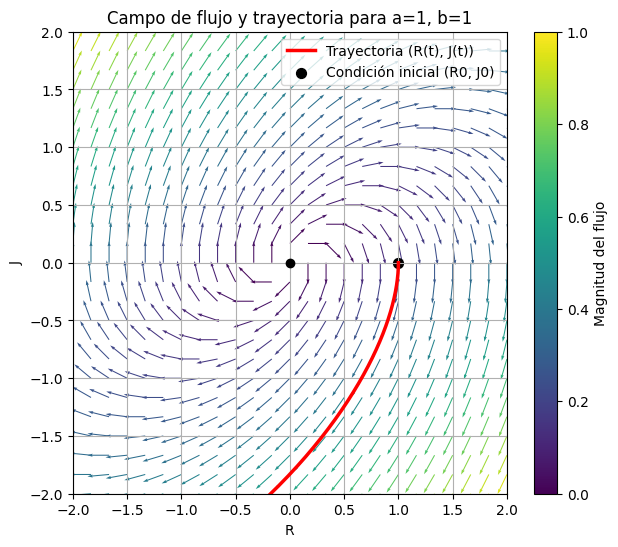

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# === Parámetros ===
a, b = 1, 1  # puedes cambiar estos valores para otros casos

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# === Definimos el sistema ===
def campo(R, J, a=1, b=1):
    dR = b * J
    dJ = -a * R + J
    return dR, dJ

# === Parámetros ===
a, b = 1, 1  # puedes cambiar a los otros casos
R0, J0 = 1, 0  # condiciones iniciales

# === Rango de valores del campo ===
R_vals = np.linspace(-2, 2, 25)
J_vals = np.linspace(-2, 2, 25)
R, J = np.meshgrid(R_vals, J_vals)

# === Campo de flujo ===
dR, dJ = campo(R, J, a, b)
magnitud = np.sqrt(dR**2 + dJ**2)

# Normalizamos el campo para que no se vea saturado
dR_n = dR / magnitud
dJ_n = dJ / magnitud

# === Trayectoria con condiciones iniciales ===
def sistema(t, y):
    R, J = y
    dRdt = b * J
    dJdt = -a * R + J
    return [dRdt, dJdt]

t_span = (0, 6)  # tiempo más corto para no explotar
t_eval = np.linspace(*t_span, 400)
sol = solve_ivp(sistema, t_span, [R0, J0], t_eval=t_eval)
R_sol, J_sol = sol.y

# === Gráfico del campo y la trayectoria ===
plt.figure(figsize=(7, 6))
plt.quiver(R, J, dR_n, dJ_n, magnitud, cmap='viridis', scale=20)
plt.plot(R_sol, J_sol, color='red', linewidth=2.5, label='Trayectoria (R(t), J(t))')
plt.scatter(R0, J0, color='black', s=50, label='Condición inicial (R0, J0)')
plt.plot(0, 0, 'ko')
plt.xlabel('R')
plt.ylabel('J')
plt.title(f'Campo de flujo y trayectoria para a={a}, b={b}')
plt.xlim(-2, 2)
plt.ylim(-2, 2)
plt.colorbar(label='Magnitud del flujo')
plt.legend()
plt.grid(True)
plt.show()



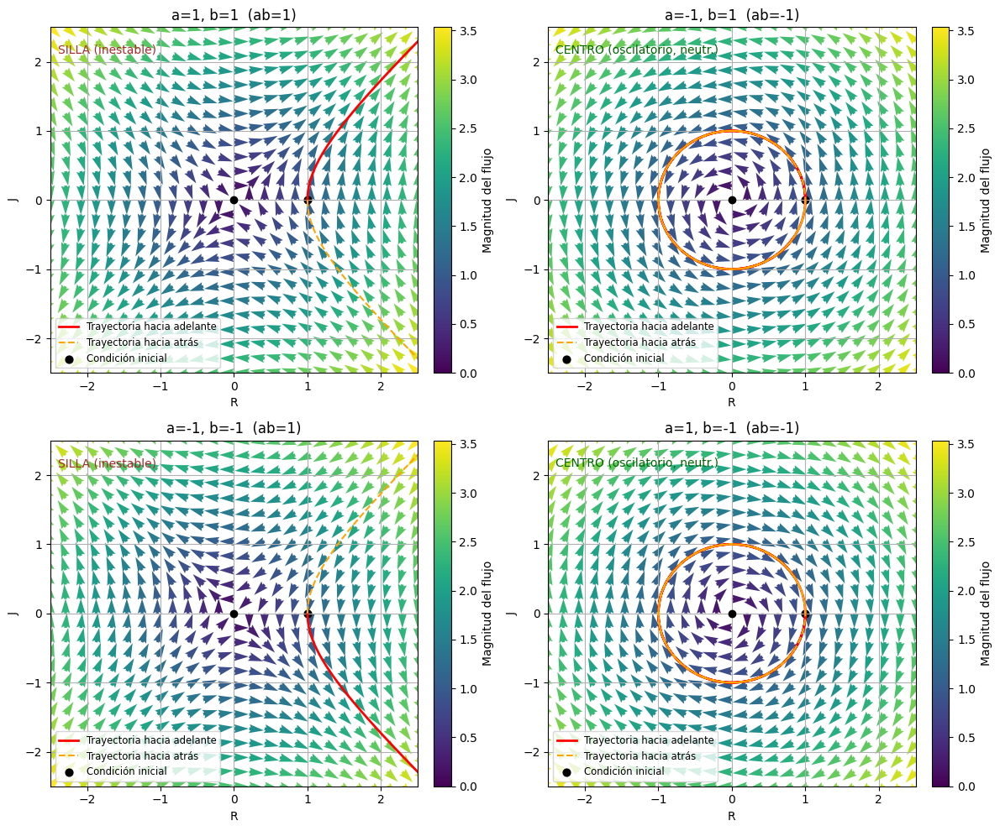

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Sistema: dR/dt = a*J, dJ/dt = b*R
def campo_mesh(R, J, a=1.0, b=1.0):
    dR = a * J
    dJ = b * R
    return dR, dJ

def sistema(t, y, a=1.0, b=1.0):
    R, J = y
    return [a * J, b * R]

# Parámetros y condiciones iniciales (cámbialos si quieres)
casos = [(1, 1), (-1, 1), (-1, -1), (1, -1)]
R0, J0 = 1.0, 0.0
t_span = (0, 12)
t_eval = np.linspace(*t_span, 1000)

# Malla para el campo
R_vals = np.linspace(-2.5, 2.5, 25)
J_vals = np.linspace(-2.5, 2.5, 25)
Rg, Jg = np.meshgrid(R_vals, J_vals)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (a, b) in zip(axes, casos):
    dR, dJ = campo_mesh(Rg, Jg, a=a, b=b)
    mag = np.sqrt(dR**2 + dJ**2)

    # evitar división por cero
    mag_safe = mag.copy()
    mag_safe[mag_safe == 0] = 1.0

    # Normalizamos para que las flechas tengan tamaño manejable
    dR_n = dR / mag_safe
    dJ_n = dJ / mag_safe

    # Colormap según magnitud (no normalizada)
    q = ax.quiver(Rg, Jg, dR_n, dJ_n, mag, cmap='viridis', scale=25, width=0.012)
    fig.colorbar(q, ax=ax, label='Magnitud del flujo', fraction=0.046, pad=0.04)

    # Trayectoria desde la condición inicial
    sol = solve_ivp(lambda t, y: sistema(t, y, a=a, b=b), t_span, [R0, J0], t_eval=t_eval, rtol=1e-9, atol=1e-12)
    Rsol, Jsol = sol.y

    # También trazamos la trayectoria hacia atrás en el tiempo para ver órbitas cerradas cuando existan
    sol_b = solve_ivp(lambda t, y: sistema(t, y, a=a, b=b), (0, -12), [R0, J0], t_eval=np.linspace(0, -12, 1000), rtol=1e-9, atol=1e-12)
    Rsol_b, Jsol_b = sol_b.y

    ax.plot(Rsol, Jsol, color='red', lw=2, label='Trayectoria hacia adelante')
    ax.plot(Rsol_b, Jsol_b, color='orange', lw=1.5, ls='--', label='Trayectoria hacia atrás')
    ax.scatter(R0, J0, color='k', s=40, label='Condición inicial')
    ax.plot(0, 0, 'ko')

    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)
    ax.set_xlabel('R')
    ax.set_ylabel('J')
    ax.set_title(f'a={a}, b={b}  (ab={a*b})')

    # texto con clasificación rápida
    if a * b > 0:
        ax.text(0.02, 0.95, 'SILLA (inestable)', transform=ax.transAxes, va='top', color='brown')
    elif a * b < 0:
        ax.text(0.02, 0.95, 'CENTRO (oscilatorio, neutr.)', transform=ax.transAxes, va='top', color='darkgreen')
    else:
        ax.text(0.02, 0.95, 'DEGENERADO', transform=ax.transAxes, va='top', color='purple')

    ax.grid(True)
    ax.legend(loc='lower left', fontsize='small')

plt.tight_layout()
plt.show()


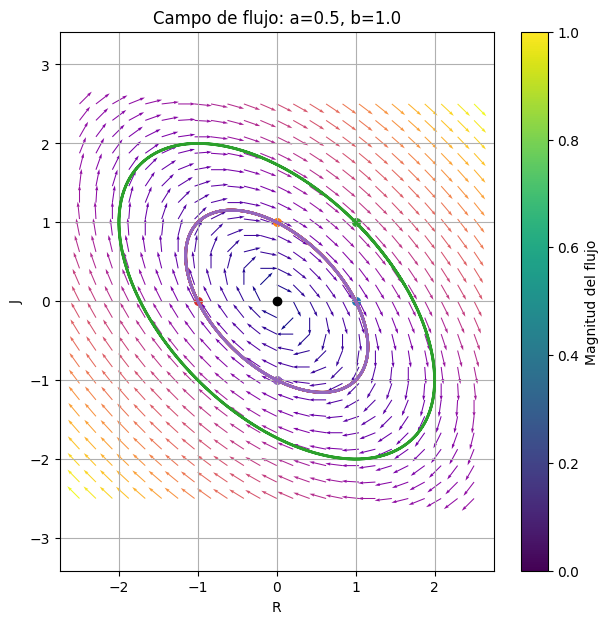

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Sistema: dR/dt = aR + bJ, dJ/dt = -bR - aJ
def campo_mesh(R, J, a=0.5, b=1.0):
    dR = a*R + b*J
    dJ = -b*R - a*J
    return dR, dJ

def sistema(t, y, a=0.5, b=1.0):
    R, J = y
    return [a*R + b*J, -b*R - a*J]

# Parámetros
a, b = 0.5, 1.0  # puedes probar (a=0.5,b=1) o (a=-0.5,b=1)
R_vals = np.linspace(-2.5, 2.5, 25)
J_vals = np.linspace(-2.5, 2.5, 25)
Rg, Jg = np.meshgrid(R_vals, J_vals)

# Campo
dR, dJ = campo_mesh(Rg, Jg, a=a, b=b)
mag = np.sqrt(dR**2 + dJ**2)
mag[mag == 0] = 1
dR_n, dJ_n = dR/mag, dJ/mag

# Figura
plt.figure(figsize=(7,7))
plt.quiver(Rg, Jg, dR_n, dJ_n, mag, cmap='plasma', scale=25)
plt.xlabel('R')
plt.ylabel('J')
plt.title(f'Campo de flujo: a={a}, b={b}')
plt.plot(0, 0, 'ko')

# Varias condiciones iniciales
condiciones = [(1,0), (0,1), (1,1), (-1,0), (0,-1)]
t_eval = np.linspace(0, 15, 1000)

for R0, J0 in condiciones:
    sol = solve_ivp(lambda t, y: sistema(t, y, a, b), [0, 15], [R0, J0], t_eval=t_eval)
    plt.plot(sol.y[0], sol.y[1], lw=2)
    plt.scatter(R0, J0, s=30)

plt.grid(True)
plt.axis('equal')
plt.colorbar(label='Magnitud del flujo')
plt.show()


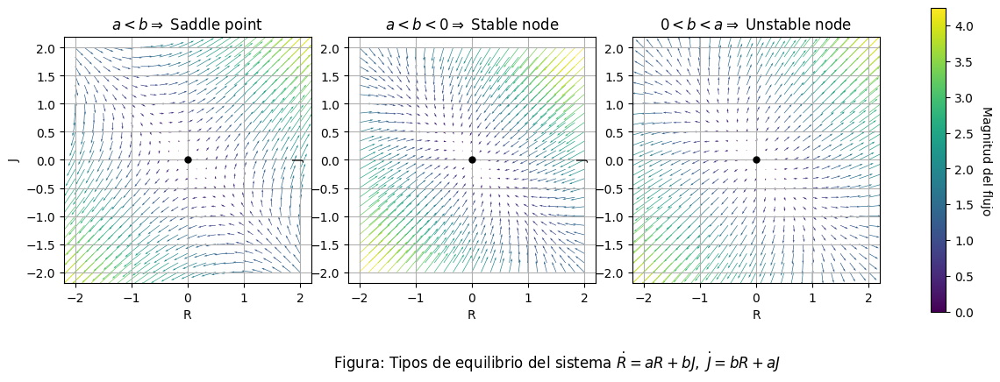

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ===== Sistema =====
def campo(R, J, a, b):
    dR = a*R + b*J
    dJ = b*R + a*J
    return dR, dJ

# ===== Casos según las condiciones =====
casos = [
    {"a": 0.5, "b": 1.0, "titulo": r"$a < b \Rightarrow$ Saddle point"},
    {"a": -1.0, "b": -0.5, "titulo": r"$a < b < 0 \Rightarrow$ Stable node"},
    {"a": 1.0, "b": 0.5, "titulo": r"$0 < b < a \Rightarrow$ Unstable node"}
]

# ===== Malla =====
R_vals = np.linspace(-2, 2, 25)
J_vals = np.linspace(-2, 2, 25)
R, J = np.meshgrid(R_vals, J_vals)

# ===== Figura =====
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
plt.subplots_adjust(wspace=0.15)

for ax, caso in zip(axes, casos):
    a, b = caso["a"], caso["b"]
    dR, dJ = campo(R, J, a, b)
    mag = np.sqrt(dR**2 + dJ**2)

    q = ax.quiver(
        R, J, dR, dJ, mag,
        cmap='viridis', scale=30, headwidth=3
    )

    ax.set_title(caso["titulo"], fontsize=12)
    ax.set_xlabel("R")
    ax.set_ylabel("J")
    ax.plot(0, 0, 'ko', markersize=5)
    ax.grid(True)
    ax.set_aspect('equal')

# ===== Barra de color =====
cbar = fig.colorbar(q, ax=axes.ravel().tolist(), shrink=0.9)
cbar.set_label("Magnitud del flujo", rotation=270, labelpad=15)

# ===== Título general =====
fig.text(0.5, 0.02,
         r"Figura: Tipos de equilibrio del sistema $\dot{R} = aR + bJ, \ \dot{J} = bR + aJ$",
         ha='center', fontsize=12)

plt.show()



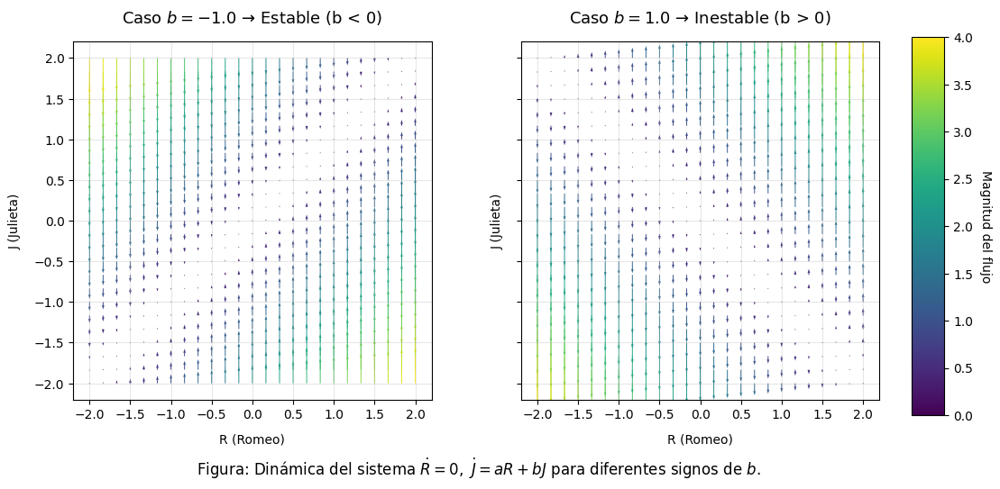

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==== Sistema ====
def campo(R, J, a, b):
    dR = np.zeros_like(R)   # Romeo no cambia
    dJ = a * R + b * J      # Julieta reacciona
    return dR, dJ

# ==== Parámetros ====
a = 1.0
b_values = [-1.0, 1.0]  # caso 1: estable, caso 2: inestable

# ==== Malla ====
R_vals = np.linspace(-2, 2, 25)
J_vals = np.linspace(-2, 2, 25)
R, J = np.meshgrid(R_vals, J_vals)

# ==== Figura ====
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)

for ax, b in zip(axes, b_values):
    dR, dJ = campo(R, J, a, b)
    mag = np.sqrt(dR**2 + dJ**2)

    # Campo vectorial
    q = ax.quiver(R, J, dR, dJ, mag, cmap='viridis', scale=40, headwidth=3)

    # Etiquetas
    tipo = "Estable (b < 0)" if b < 0 else "Inestable (b > 0)"
    ax.set_title(fr"Caso $b={b}$ → {tipo}", fontsize=13, pad=15)
    ax.set_xlabel("R (Romeo)", labelpad=10)
    ax.set_ylabel("J (Julieta)", labelpad=10)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal')

# ==== Ajuste del espacio antes de la barra ====
plt.subplots_adjust(right=0.87, bottom=0.12, top=0.9, wspace=0.25)

# ==== Barra de color ====
cbar_ax = fig.add_axes([0.9, 0.15, 0.03, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(q, cax=cbar_ax)
cbar.set_label("Magnitud del flujo", rotation=270, labelpad=15)

# ==== Texto descriptivo ====
fig.text(0.5, 0.04,
         r"Figura: Dinámica del sistema $\dot{R}=0,\ \dot{J}=aR+bJ$ para diferentes signos de $b$.",
         ha='center', fontsize=12)

plt.show()


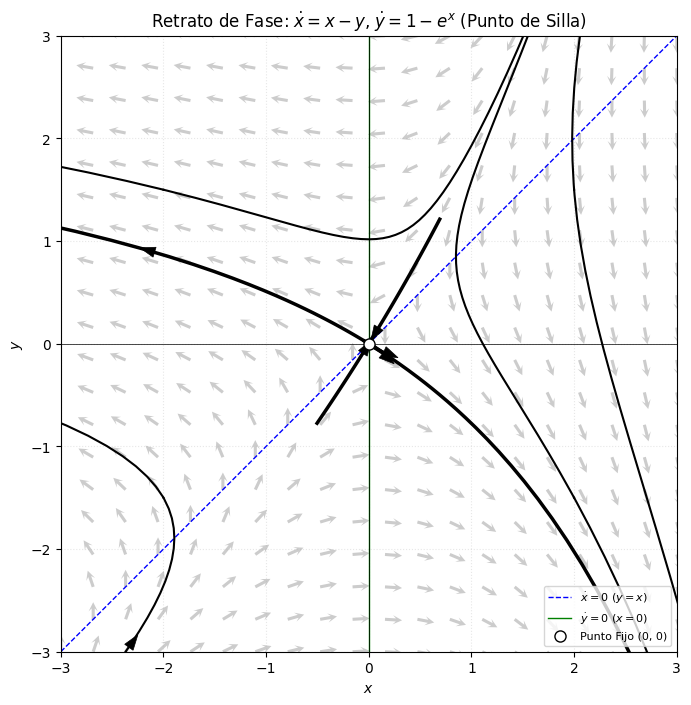

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs ---
def system_611(t, X):
    x, y = X
    x_dot = x - y
    y_dot = 1 - np.exp(x)
    return [x_dot, y_dot]

# --- 2. Cálculo de Variedades (Eigenvectores) ---
A = np.array([[1, -1], [-1, 0]])
eigenvalues, eigenvectors = np.linalg.eig(A)

# lambda1 ≈ 1.618 (Inestable)
lambda1_idx = np.argmax(eigenvalues)
v1 = eigenvectors[:, lambda1_idx] # Vector propio inestable
# lambda2 ≈ -0.618 (Estable)
lambda2_idx = np.argmin(eigenvalues)
v2 = eigenvectors[:, lambda2_idx] # Vector propio estable

# --- 3. Parámetros del Plano Fase ---
RANGO = 3.0
N_GRID = 20
T_SPAN = 5.0
X, Y = np.meshgrid(np.linspace(-RANGO, RANGO, N_GRID), np.linspace(-RANGO, RANGO, N_GRID))
U, V = system_611(0, [X, Y])
M = np.hypot(U, V)

# Puntos para iniciar las trayectorias
initial_conditions_far = [
    [2.0, 1.5], [-2.0, 1.5], [2.0, -1.5], [-2.0, -1.5]
]

# Puntos para iniciar las variedades (cerca del origen)
epsilon_var = 0.05
# Variedad Inestable (alejándose)
start_unstable = [epsilon_var * v1, -epsilon_var * v1]
# Variedad Estable (acercándose)
start_stable = [epsilon_var * v2, -epsilon_var * v2]

# --- 4. Función de Ploteo de Trayectoria ---
def plot_trajectory(ax, X0, t_start, t_end, color='black', linewidth=1.5, draw_arrow=False):
    sol = solve_ivp(system_611, [t_start, t_end], X0, dense_output=True, rtol=1e-8, atol=1e-8)

    if len(sol.t) > 2:
        ax.plot(sol.y[0], sol.y[1], color=color, linewidth=linewidth, zorder=4)

        if draw_arrow:
            # Colocar flecha cerca del final (o al inicio para variedad estable)
            idx = len(sol.t) // 2

            V_mid = system_611(sol.t[idx], [sol.y[0][idx], sol.y[1][idx]])
            V_mag = np.hypot(V_mid[0], V_mid[1])

            if V_mag > 1e-4:
                scale_factor = 0.15 * RANGO / 3 # Ajuste de tamaño
                ax.arrow(sol.y[0][idx], sol.y[1][idx],
                         V_mid[0] * scale_factor / V_mag, V_mid[1] * scale_factor / V_mag,
                         color='black', head_width=0.1, head_length=0.15, linewidth=0.5, zorder=5)

# --- 5. Graficación ---
plt.figure(figsize=(8, 8))
ax = plt.gca()

# A) Campo Vectorial
plt.quiver(X, Y, U / M, V / M, color='gray', alpha=0.4, headlength=3, headaxislength=2, width=0.005)

# B) Nulclinas y Ejes
plt.plot(np.linspace(-RANGO, RANGO), np.linspace(-RANGO, RANGO), 'b--', label=r'$\dot{x}=0$ ($y=x$)', linewidth=1)
plt.plot(np.zeros_like(np.linspace(-RANGO, RANGO)), np.linspace(-RANGO, RANGO), 'g-', label=r'$\dot{y}=0$ ($x=0$)', linewidth=1)

# C) Trayectorias (Generales)
for X0 in initial_conditions_far:
    plot_trajectory(ax, X0, 0, T_SPAN, draw_arrow=True) # Inestable (hacia adelante)
    plot_trajectory(ax, X0, 0, -T_SPAN, draw_arrow=True) # Estable (hacia atrás)

# D) Trayectorias de las Variedades (Separatrices - Usando Eigenvectores)
for v_init in start_unstable:
    plot_trajectory(ax, v_init, 0, T_SPAN, color='black', linewidth=2.5, draw_arrow=True) # Se aleja
    plot_trajectory(ax, v_init, 0, -T_SPAN, color='black', linewidth=2.5, draw_arrow=False) # Se acerca a la estable
for v_init in start_stable:
    plot_trajectory(ax, v_init, 0, T_SPAN, color='black', linewidth=2.5, draw_arrow=True) # Se aleja
    plot_trajectory(ax, v_init, 0, -T_SPAN, color='black', linewidth=2.5, draw_arrow=True) # Se acerca

# E) Punto Fijo
plt.plot(0, 0, 'ko', markerfacecolor='white', markersize=8, label='Punto Fijo (0, 0)', zorder=5)


# F) Configuración Final
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title(r'Retrato de Fase: $\dot{x}=x-y$, $\dot{y}=1-e^x$ (Punto de Silla)')
plt.xlim(-RANGO, RANGO)
plt.ylim(-RANGO, RANGO)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.legend(loc='lower right', fontsize=8)
plt.grid(True, linestyle=':', alpha=0.3)
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

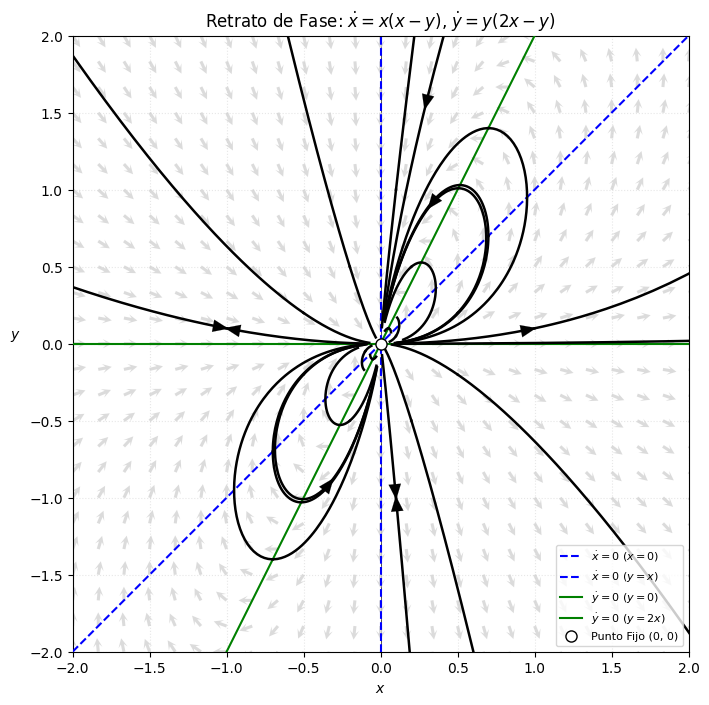

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs ---
def system_613(t, X):
    """Sistema: x_dot = x(x - y), y_dot = y(2x - y)"""
    x, y = X
    x_dot = x * (x - y)
    y_dot = y * (2 * x - y)
    return [x_dot, y_dot]

# --- 2. Parámetros y Malla ---
RANGO = 2.0
N_GRID = 25 # Densidad del campo vectorial

x_vals = np.linspace(-RANGO, RANGO, N_GRID)
y_vals = np.linspace(-RANGO, RANGO, N_GRID)
X, Y = np.meshgrid(x_vals, y_vals)

# Calcular el campo vectorial
U, V = system_613(0, [X, Y])
M = np.hypot(U, V) # Magnitud
M[M == 0] = 1e-6 # Evitar división por cero

# Normalizar los vectores
U_norm, V_norm = U / M, V / M

# --- 3. Definición de Nulclinas ---
n_points_null = 100
line_vals_null = np.linspace(-RANGO, RANGO, n_points_null)

# Nulclina x_dot = 0 (Azul punteada)
null_x_line1_x = np.zeros_like(line_vals_null) # x = 0 (Eje Y)
null_x_line1_y = line_vals_null
null_x_line2_x = line_vals_null             # y = x
null_x_line2_y = line_vals_null

# Nulclina y_dot = 0 (Verde sólida)
null_y_line1_x = line_vals_null             # y = 0 (Eje X)
null_y_line1_y = np.zeros_like(line_vals_null)
null_y_line2_x = line_vals_null             # y = 2x
null_y_line2_y = 2 * line_vals_null

# --- 4. Definición de Trayectorias y Flechas ---
# Seleccionamos cuidadosamente las condiciones iniciales para mostrar los "lóbulos".
# Incluiremos puntos en los cuatro cuadrantes y cerca de las nulclinas.
# Los tiempos de simulación deben ser suficientes para ver los patrones.
T_SPAN_FWD = 10.0 # Más tiempo para ver las curvas
T_SPAN_BWD = -10.0 # Más tiempo para ver las curvas

# Condiciones iniciales para mostrar los lóbulos y el comportamiento
initial_conditions = [
    [0.1, 0.05], [0.05, 0.1], # Cerca del origen en diferentes direcciones
    [-0.1, -0.05], [-0.05, -0.1],

    [0.5, 0.2], [0.2, 0.5],   # Cuadrante I
    [-0.5, 0.2], [-0.2, 0.5], # Cuadrante II
    [-0.5, -0.2], [-0.2, -0.5], # Cuadrante III
    [0.5, -0.2], [0.2, -0.5], # Cuadrante IV

    [1.0, 0.1], [-1.0, 0.1],  # Más lejos para ver el escape
    [0.1, 1.0], [0.1, -1.0],

    [0.7, 0.7], # A lo largo de y=x
    [0.7, 1.4], # A lo largo de y=2x
    [-0.7, -0.7],
    [-0.7, -1.4]
]


def plot_trajectory(ax, X0, t_span, color='black', linewidth=1.5, arrow_step=50):
    """
    Resuelve la EDO y grafica la trayectoria con flechas.
    arrow_step: Cada cuántos puntos se dibuja una flecha.
    """
    sol = solve_ivp(system_613, [0, t_span], X0, dense_output=True, rtol=1e-8, atol=1e-8,
                    max_step=0.05) # Asegurar más puntos para curvas complejas

    if len(sol.t) > 2:
        ax.plot(sol.y[0], sol.y[1], color=color, linewidth=linewidth, zorder=4)

        # Dibujar flechas a intervalos
        for i in range(0, len(sol.t) - 1, arrow_step):
            if i + 1 < len(sol.t):
                x_start, y_start = sol.y[0][i], sol.y[1][i]
                x_end, y_end = sol.y[0][i+1], sol.y[1][i+1] # Usar el siguiente punto para la dirección

                # Para evitar flechas muy pequeñas o en el origen
                if np.hypot(x_end - x_start, y_end - y_start) > 0.01:
                    ax.arrow(x_start, y_start, x_end - x_start, y_end - y_start,
                             color=color, head_width=0.08, head_length=0.1,
                             length_includes_head=True, linewidth=0.1, zorder=5)

# --- 5. Graficación ---
plt.figure(figsize=(8, 8))
ax = plt.gca()

# A) Campo Vectorial (gris claro, zorder=2)
plt.quiver(X, Y, U_norm, V_norm,
           color='lightgray',
           alpha=0.8,
           headlength=3,
           headaxislength=2,
           width=0.005,
           zorder=2)

# B) Nulclinas (azul y verde, con zorder=3 para que estén encima del campo)
plt.plot(null_x_line1_x, null_x_line1_y, 'b--', label=r'$\dot{x}=0$ ($x=0$)', linewidth=1.5, zorder=3)
plt.plot(null_x_line2_x, null_x_line2_y, 'b--', label=r'$\dot{x}=0$ ($y=x$)', linewidth=1.5, zorder=3)
plt.plot(null_y_line1_x, null_y_line1_y, 'g-', label=r'$\dot{y}=0$ ($y=0$)', linewidth=1.5, zorder=3)
plt.plot(null_y_line2_x, null_y_line2_y, 'g-', label=r'$\dot{y}=0$ ($y=2x$)', linewidth=1.5, zorder=3)

# C) Puntos Fijos (círculo blanco con borde negro, zorder=5)
plt.plot(0, 0, 'ko', markerfacecolor='white', markersize=8, label='Punto Fijo (0, 0)', zorder=5)

# D) Trayectorias Negras (zorder=4 para que estén entre nulclinas y campo)
for X0 in initial_conditions:
    plot_trajectory(ax, X0, T_SPAN_FWD, color='black', linewidth=1.8, arrow_step=70)
    plot_trajectory(ax, X0, T_SPAN_BWD, color='black', linewidth=1.8, arrow_step=70)

# E) Configuración Final
plt.xlabel('$x$')
plt.ylabel('$y$', rotation=0, labelpad=10)
plt.title(r'Retrato de Fase: $\dot{x}=x(x-y)$, $\dot{y}=y(2x-y)$')
plt.xlim(-RANGO, RANGO)
plt.ylim(-RANGO, RANGO)
plt.axhline(0, color='black', linewidth=0.5, zorder=1) # Ejes principales
plt.axvline(0, color='black', linewidth=0.5, zorder=1)
plt.legend(loc='lower right', fontsize=8)
plt.grid(True, linestyle=':', alpha=0.3, zorder=0) # Rejilla al fondo
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

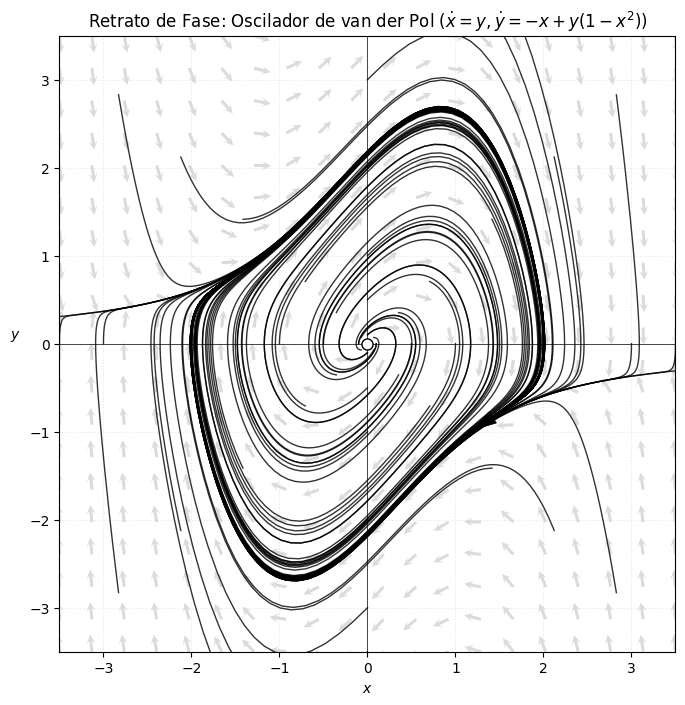

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs ---
def van_der_pol_system(t, X):
    """
    Oscilador de van der Pol:
    x_dot = y
    y_dot = -x + y(1 - x^2)
    """
    x, y = X
    x_dot = y
    y_dot = -x + y * (1 - x**2)
    return [x_dot, y_dot]

# --- 2. Parámetros del Plano Fase y Campo Vectorial ---
RANGO = 3.5
N_GRID = 20 # Densidad del campo vectorial
T_SPAN = 20.0 # Tiempo de simulación suficiente para alcanzar el ciclo límite

x_vals = np.linspace(-RANGO, RANGO, N_GRID)
y_vals = np.linspace(-RANGO, RANGO, N_GRID)
X, Y = np.meshgrid(x_vals, y_vals)

# Calcular el campo vectorial
U, V = van_der_pol_system(0, [X, Y])
M = np.hypot(U, V)
M[M == 0] = 1e-6
U_norm, V_norm = U / M, V / M # Normalizar para el quiver

# --- 3. Definición de Trayectorias (MÁS LÍNEAS NEGRAS) ---
# Puntos iniciales para ilustrar la convergencia
initial_conditions = []

# Trayectorias que se expanden (cerca del origen, 0.1 < r < 1.0)
for r in [0.1, 0.5, 1.0]:
    for angle in np.linspace(0, 2 * np.pi, 8, endpoint=False):
        initial_conditions.append([r * np.cos(angle), r * np.sin(angle)])

# Trayectorias que se contraen (lejos del origen, 2.0 < r < 5.0)
for r in [2.0, 3.0, 4.0]:
    for angle in np.linspace(0, 2 * np.pi, 8, endpoint=False):
        initial_conditions.append([r * np.cos(angle), r * np.sin(angle)])

# Puntos clave en los ejes
initial_conditions.extend([
    [0.1, 0.0], [-0.1, 0.0], [0.0, 0.1], [0.0, -0.1],
    [3.5, 0.0], [0.0, 3.5], [-3.5, 0.0], [0.0, -3.5]
])

# --- 4. Graficación ---
plt.figure(figsize=(8, 8))
ax = plt.gca()

# A) Campo Vectorial
plt.quiver(X, Y, U_norm, V_norm,
           color='lightgray',
           alpha=0.8,
           headlength=3,
           headaxislength=2,
           width=0.005,
           zorder=2)

# B) Trayectorias (Ciclo Límite)
for X0 in initial_conditions:
    # Simular hacia adelante (t > 0)
    sol_fwd = solve_ivp(van_der_pol_system, [0, T_SPAN], X0,
                        dense_output=True, rtol=1e-8, atol=1e-8, max_step=0.05)

    # Dibujar la trayectoria
    plt.plot(sol_fwd.y[0], sol_fwd.y[1], color='black', linewidth=1.0, alpha=0.8, zorder=3)

    # Añadir flecha (solo a un subconjunto de trayectorias para no saturar)
    if X0 in [[0.5, 0], [3.0, 3.0], [-3.0, 0.0]]: # Seleccionar unas pocas para la dirección
        x_end, y_end = sol_fwd.y[0][-1], sol_fwd.y[1][-1]
        x_prev, y_prev = sol_fwd.y[0][-5], sol_fwd.y[1][-5]

        # Dibujar flecha cerca del final
        plt.arrow(x_prev, y_prev, x_end - x_prev, y_end - y_prev,
                  color='black', head_width=0.15, head_length=0.25, linewidth=0.5, zorder=4)


# C) Punto Fijo
plt.plot(0, 0, 'ko', markerfacecolor='white', markersize=8, label='Espiral Inestable (0, 0)', zorder=5)

# D) Configuración Final
plt.xlabel('$x$')
plt.ylabel('$y$', rotation=0, labelpad=10)
plt.title(r'Retrato de Fase: Oscilador de van der Pol ($\dot{x}=y, \dot{y}=-x+y(1-x^2)$)')
plt.xlim(-RANGO, RANGO)
plt.ylim(-RANGO, RANGO)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle=':', alpha=0.3)
plt.gca().set_aspect('equal', adjustable='box')

plt.show()

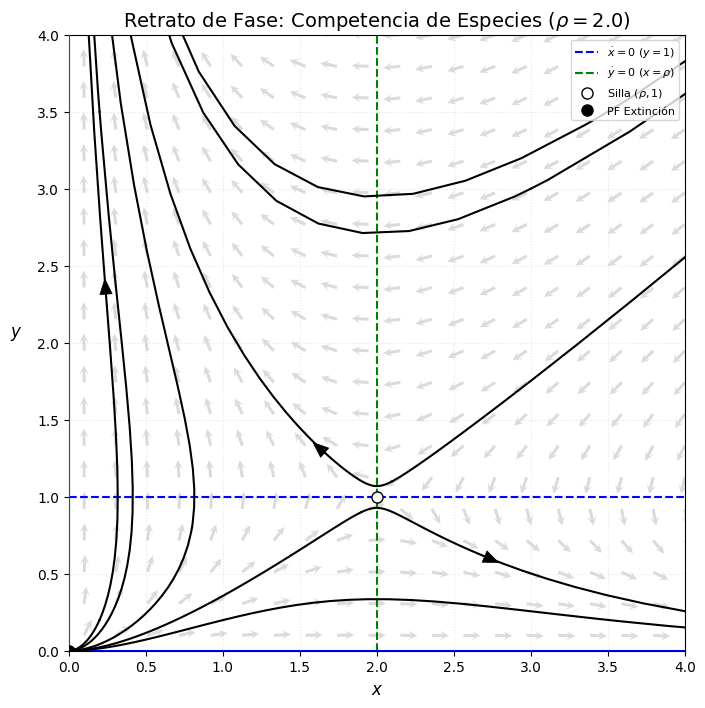

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Parámetros del Sistema ---
RHO = 2.0  # Parámetro adimensional rho = r2/r1. Usamos rho=2.0
RANGO = 4.0 # Rango del plano fase para x y y

# --- 2. Definición del Sistema de EDOs ---
def competition_system(t, X, rho):
    """
    Sistema de competencia simplificado (adimensionalizado):
    x_dot = x(1 - y)
    y_dot = y(rho - x)
    """
    x, y = X
    x_dot = x * (1 - y)
    y_dot = y * (rho - x)
    return [x_dot, y_dot]

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Parámetros del Sistema ---
RHO = 2.0
RANGO = 4.0

# --- 2. Definición del Sistema de EDOs (Sin cambios) ---
def competition_system(t, X, rho):
    x, y = X
    x_dot = x * (1 - y)
    y_dot = y * (rho - x)
    return [x_dot, y_dot]

# --- 3. EVENTO DE TERMINACIÓN: Evitar que las trayectorias salgan del cuadro ---
# El integrador se detendrá si x o y son demasiado grandes (p.ej., > 100)
def stop_simulation(t, X, rho):
    return 100 - np.linalg.norm(X)
stop_simulation.terminal = True # Indica que la integración debe detenerse
stop_simulation.direction = -1  # Se activa cuando la función (100 - norm(X)) se hace negativa

# --- 4. Trayectorias y Parámetros Optimización ---
T_SPAN_OPT = 10.0 # Reducimos el tiempo máximo de simulación
TOLERANCE = 1e-6 # Una tolerancia más ligera

# Condiciones iniciales (Usamos un conjunto similar pero más compacto)
initial_conditions = [
    [0.2, 0.2], [0.2, 3.5], [3.5, 0.2], [3.5, 3.5],
    [RHO + 0.1, 1.0 + 0.1], [RHO - 0.1, 1.0 - 0.1],
    [0.8, 0.8], [3.0, 3.0]
]

def plot_trajectory_optimized(ax, X0, t_span, color='black', linewidth=1.5):
    """
    Resuelve la EDO con límites de tiempo/espacio y grafica la trayectoria.
    """
    # Simulación hacia adelante
    sol_fwd = solve_ivp(competition_system, [0, t_span], X0,
                        args=(RHO,), rtol=TOLERANCE, atol=TOLERANCE,
                        max_step=0.1, events=stop_simulation)
    ax.plot(sol_fwd.y[0], sol_fwd.y[1], color=color, linewidth=linewidth, zorder=4)

    # Simulación hacia atrás (para variedades estables)
    sol_bwd = solve_ivp(competition_system, [0, -t_span], X0,
                        args=(RHO,), rtol=TOLERANCE, atol=TOLERANCE,
                        max_step=0.1, events=stop_simulation)
    ax.plot(sol_bwd.y[0], sol_bwd.y[1], color=color, linewidth=linewidth, zorder=4)

    # Añadir flecha (solo en la trayectoria hacia adelante para la dirección)
    if len(sol_fwd.t) > 5:
        idx = len(sol_fwd.t) // 3 # Flecha al inicio
        x_start, y_start = sol_fwd.y[0][idx], sol_fwd.y[1][idx]
        v_mid = competition_system(0, [x_start, y_start], RHO)

        ax.arrow(x_start, y_start, v_mid[0] * 0.1, v_mid[1] * 0.1,
                 color=color, head_width=0.08, head_length=0.1, linewidth=0.5, zorder=5)

# --- 5. Graficación Final ---
plt.figure(figsize=(8, 8))
ax = plt.gca()

# Nulclinas y Puntos Fijos... (El resto del código de graficación es el mismo)

# Campo Vectorial (Vector Field)
N_GRID = 20
x_vals_grid = np.linspace(0.1, RANGO, N_GRID)
y_vals_grid = np.linspace(0.1, RANGO, N_GRID)
X, Y = np.meshgrid(x_vals_grid, y_vals_grid)
U, V = competition_system(0, [X, Y], RHO)
M = np.hypot(U, V)
M[M == 0] = 1e-6
U_norm, V_norm = U / M, V / M

plt.quiver(X, Y, U_norm, V_norm, color='lightgray', alpha=0.8, headlength=3, headaxislength=2, width=0.005, zorder=2)

# Nulclinas (Se asume que ya están definidas en el entorno global)
plt.plot(np.linspace(0, RANGO), np.ones(50) * 1.0, 'b--', label=r'$\dot{x}=0$ ($y=1$)', linewidth=1.5, zorder=3)
plt.plot(np.ones(50) * RHO, np.linspace(0, RANGO), 'g--', label=r'$\dot{y}=0$ ($x=\rho$)', linewidth=1.5, zorder=3)
plt.plot([0, RANGO], [0, 0], 'b-', linewidth=1.5, zorder=3)
plt.plot([0, 0], [0, RANGO], 'g-', linewidth=1.5, zorder=3)

# Trayectorias Optimizadas
for X0 in initial_conditions:
    plot_trajectory_optimized(ax, X0, T_SPAN_OPT, color='black')

# Puntos Fijos (Coexistencia y Origen)
plt.plot(RHO, 1.0, 'ko', markerfacecolor='white', markersize=8, label=r'Silla $(\rho, 1)$', zorder=5)
plt.plot(0, 0, 'ko', markerfacecolor='black', markersize=8, label='PF Extinción', zorder=5)

# Configuración Final
plt.xlabel(r'$x$', fontsize=12)
plt.ylabel(r'$y$', rotation=0, labelpad=15, fontsize=12)
plt.title(r'Retrato de Fase: Competencia de Especies ($\rho=2.0$)', fontsize=14)
plt.xlim(0, RANGO)
plt.ylim(0, RANGO)
plt.legend(loc='upper right', fontsize=8)
plt.grid(True, linestyle=':', alpha=0.3)
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

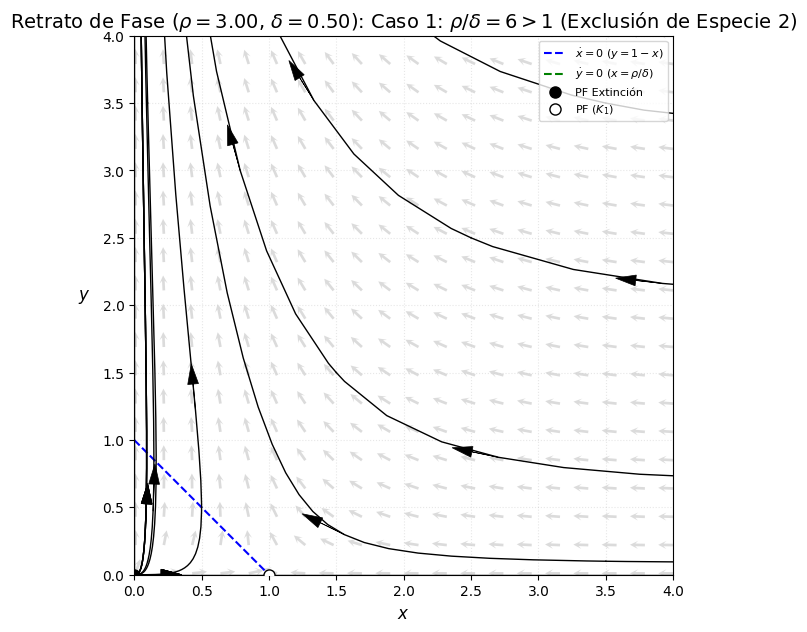

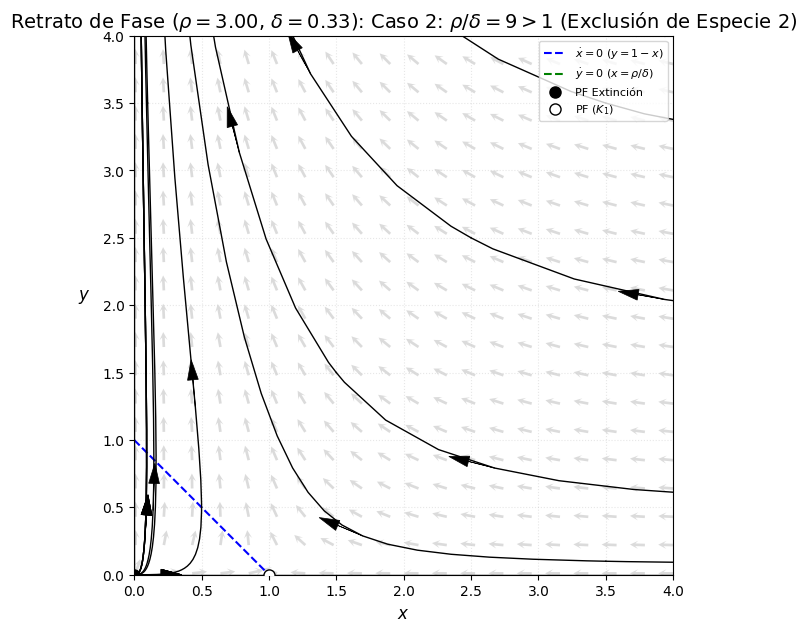

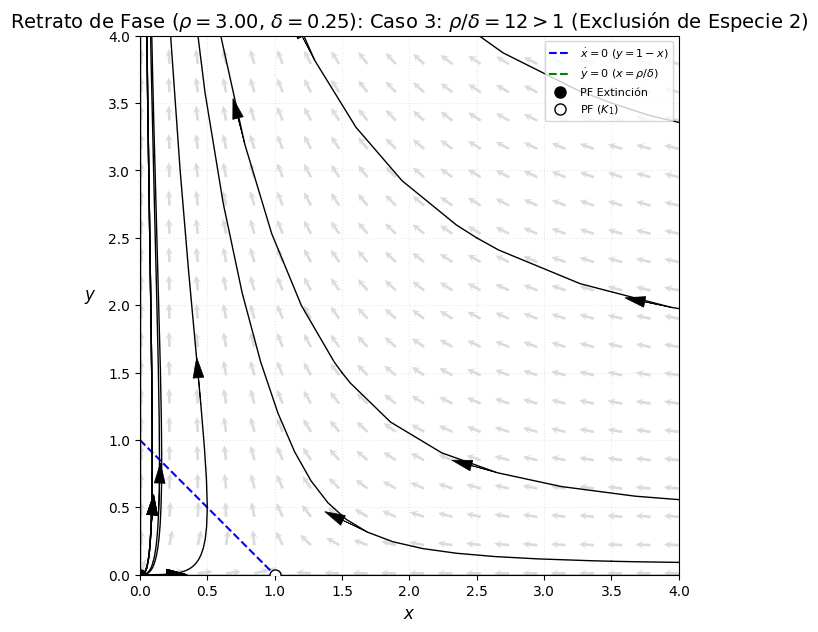

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs Adimensionalizado ---
def competition_system_645(t, X, rho, delta):
    x, y = X
    x_dot = x * (1 - x - y)
    y_dot = y * (rho - delta * x)
    return [x_dot, y_dot]

# --- 2. Parámetros Generales ---
RHO_COMMON = 3.0 # Valor común de rho para todas las imágenes
RANGO = 4.0
TOLERANCE = 1e-6
MAX_STEP = 0.1

# --- Función para evitar que las trayectorias salgan del cuadro ---
def stop_simulation(t, X, rho, delta):
    # Se detiene si el vector de estado es > 10
    return 10 - np.linalg.norm(X)
stop_simulation.terminal = True
stop_simulation.direction = -1

# --- Función para generar un retrato de fase específico ---
def generate_phase_portrait(rho, delta, image_title_suffix=""):

    # Calcular el punto de coexistencia
    pf_coexistencia_x = rho / delta
    pf_coexistencia_y = 1 - pf_coexistencia_x

    # Puntos Fijos (para mostrar en la leyenda y marcarlos)
    fixed_points_info = [
        (0, 0, 'o', 'PF (0,0)'),
        (1, 0, 'o', 'PF (1,0)'),
    ]
    if pf_coexistencia_y > 0 and pf_coexistencia_x > 0:
        fixed_points_info.append((pf_coexistencia_x, pf_coexistencia_y, 'o', f'PF ({pf_coexistencia_x:.2f},{pf_coexistencia_y:.2f})'))

    # Ajuste del rango
    current_rango_x = max(RANGO, pf_coexistencia_x + 0.5) if pf_coexistencia_y > 0 else RANGO
    current_rango_y = max(RANGO, pf_coexistencia_y + 0.5) if pf_coexistencia_y > 0 else RANGO

    # --- Malla para el Campo Vectorial ---
    N_GRID = 20
    x_vals_grid = np.linspace(0.01, current_rango_x, N_GRID)
    y_vals_grid = np.linspace(0.01, current_rango_y, N_GRID)
    X_grid, Y_grid = np.meshgrid(x_vals_grid, y_vals_grid)

    U, V = competition_system_645(0, [X_grid, Y_grid], rho, delta)
    M = np.hypot(U, V)
    M[M == 0] = 1e-6
    U_norm, V_norm = U / M, V / M

    # --- Nulclinas ---
    # ... (código de nulclinas omitido para brevedad, no es la fuente del error) ...
    null_x_line_x_values = np.linspace(0, 1, 100)
    null_x_line_y_values = 1 - null_x_line_x_values
    null_y_line_x_values = np.ones(100) * (rho / delta)
    null_y_line_y_values = np.linspace(0, current_rango_y, 100)

    # --- Trayectorias ---
    T_SPAN = 20.0
    initial_conditions = [
        [0.1, 0.1], [0.1, 3.5], [3.5, 0.1], [3.5, 3.5],
        [0.5, 0.5], [1.5, 1.5], [2.5, 2.5],
        [pf_coexistencia_x + 0.05, pf_coexistencia_y + 0.05] if pf_coexistencia_y > 0 else [0.05, 0.05],
        [pf_coexistencia_x - 0.05, pf_coexistencia_y - 0.05] if pf_coexistencia_y > 0 else [0.05, 0.05],
        [pf_coexistencia_x + 0.05, pf_coexistencia_y - 0.05] if pf_coexistencia_y > 0 else [0.05, 0.05],
        [pf_coexistencia_x - 0.05, pf_coexistencia_y + 0.05] if pf_coexistencia_y > 0 else [0.05, 0.05],
    ]
    initial_conditions = [ic for ic in initial_conditions if 0 < ic[0] < current_rango_x and 0 < ic[1] < current_rango_y]

    plt.figure(figsize=(9, 7))
    ax = plt.gca()

    # ... (código de quiver, nulclinas, etc. omitido para brevedad) ...

    # Campo Vectorial (Vector Field) - (simulación)
    plt.quiver(X_grid, Y_grid, U_norm, V_norm, color='lightgray', alpha=0.8, headlength=3, headaxislength=2, width=0.005, zorder=2)

    # Nulclinas
    plt.plot(null_x_line_x_values, null_x_line_y_values, 'b--', label=r'$\dot{x}=0$ ($y=1-x$)', linewidth=1.5, zorder=3)
    plt.plot(null_y_line_x_values, null_y_line_y_values, 'g--', label=r'$\dot{y}=0$ ($x=\rho/\delta$)', linewidth=1.5, zorder=3)
    plt.plot([0, current_rango_x], [0, 0], 'k-', linewidth=1.0, zorder=3)
    plt.plot([0, 0], [0, current_rango_y], 'k-', linewidth=1.0, zorder=3)

    # Trayectorias (Función de ploteo completa es necesaria aquí)
    for X0 in initial_conditions:
        def solve_and_plot(t_span):
            sol = solve_ivp(competition_system_645, [0, t_span], X0, args=(rho, delta), rtol=TOLERANCE, atol=TOLERANCE, max_step=MAX_STEP, events=stop_simulation)
            ax.plot(sol.y[0], sol.y[1], color='black', linewidth=1.0, zorder=4)
            if len(sol.t) > 5:
                # Añadir flechas
                idx = len(sol.t) // 3
                x_arr, y_arr = sol.y[0][idx], sol.y[1][idx]
                v_mid = competition_system_645(0, [x_arr, y_arr], rho, delta)
                mag_arr = np.hypot(v_mid[0], v_mid[1])
                if mag_arr > 1e-6:
                    ax.arrow(x_arr, y_arr, v_mid[0]/mag_arr * 0.2, v_mid[1]/mag_arr * 0.2,
                             color='black', head_width=0.08, head_length=0.15, linewidth=0.5, zorder=5)

        solve_and_plot(T_SPAN) # Simulación hacia adelante
        solve_and_plot(-T_SPAN) # Simulación hacia atrás

    # Puntos Fijos
    plt.plot(0, 0, 'ko', markerfacecolor='black', markersize=8, label='PF Extinción', zorder=5)

    if pf_coexistencia_y > 0 and pf_coexistencia_x > 0:
         plt.plot(pf_coexistencia_x, pf_coexistencia_y, 'ko', markerfacecolor='white', markeredgecolor='black', markersize=8, label=f'PF de Coexistencia', zorder=5)
    plt.plot(1, 0, 'ko', markerfacecolor='white', markeredgecolor='black', markersize=8, label=r'PF ($K_1$)', zorder=5)


    # --- LÍNEA CORREGIDA DEL TÍTULO ---
    # Usamos rf'' para manejar LaTeX y f-string simultáneamente
    plt.title(rf'Retrato de Fase ($\rho={rho:.2f}$, $\delta={delta:.2f}$): {image_title_suffix}', fontsize=14)


    plt.xlabel(r'$x$', fontsize=12)
    plt.ylabel(r' $y$', rotation=0, labelpad=15, fontsize=12)
    plt.xlim(0, current_rango_x)
    plt.ylim(0, current_rango_y)
    plt.legend(loc='upper right', fontsize=8)
    plt.grid(True, linestyle=':', alpha=0.3)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


# --- Generar las imágenes solicitadas ---
# El error original se produce aquí al llamar a la función.
# Caso 1: rho=3, delta=0.5. rho/delta = 6 (No hay coexistencia en el cuadrante I)
generate_phase_portrait(RHO_COMMON, 0.5, r"Caso 1: $\rho/\delta = 6 > 1$ (Exclusión de Especie 2)")
# Caso 2: rho=3, delta=1/3 ≈ 0.333
generate_phase_portrait(RHO_COMMON, 1/3, r"Caso 2: $\rho/\delta = 9 > 1$ (Exclusión de Especie 2)")
# Caso 3: rho=3, delta=0.25
generate_phase_portrait(RHO_COMMON, 0.25, r"Caso 3: $\rho/\delta = 12 > 1$ (Exclusión de Especie 2)")

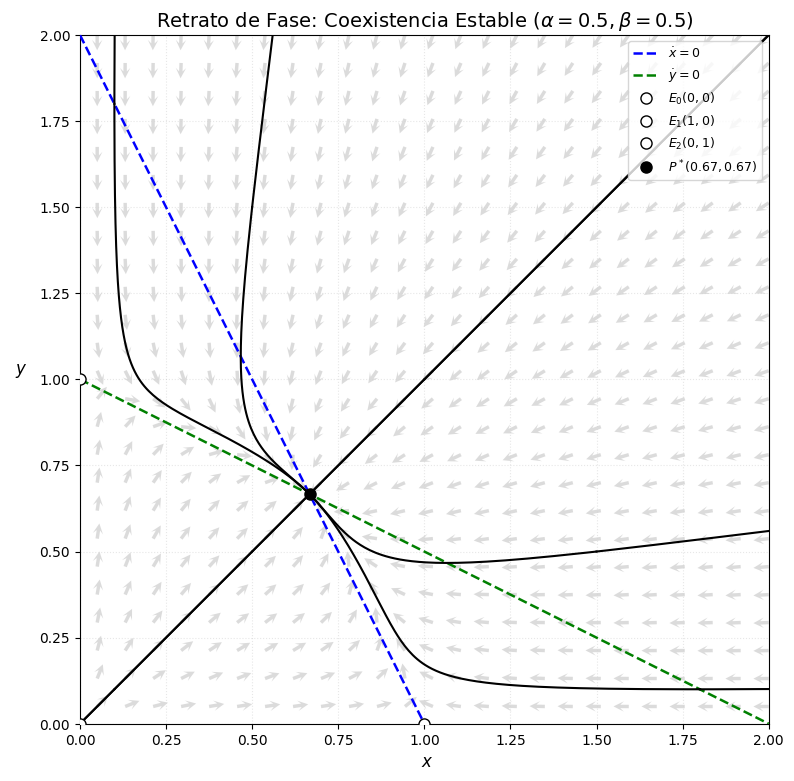

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# === 1. Definición del Sistema de EDOs ===
def competition_system_646(t, X, alpha, beta, rho):
    x, y = X
    x_dot = x * (1 - x - alpha * y)
    y_dot = y * (rho * (1 - y) - beta * x)
    return [x_dot, y_dot]

# === 2. Parámetros del Caso I (Coexistencia Estable) ===
RHO = 1.0
ALPHA = 0.5
BETA = 0.5
RANGO = 2.0
T_SPAN = 30.0

# --- Punto fijo de coexistencia (corregido) ---
x_star_correct = (RHO * (1 - ALPHA)) / (RHO - ALPHA * BETA)
y_star_correct = (1 - x_star_correct) / ALPHA
P_STAR_CORRECT = (x_star_correct, y_star_correct)

# === 3. Malla y Nulclinas ===
N_GRID = 25
x_vals_grid = np.linspace(0.05, RANGO, N_GRID)
y_vals_grid = np.linspace(0.05, RANGO, N_GRID)
X, Y = np.meshgrid(x_vals_grid, y_vals_grid)

U, V = competition_system_646(0, [X, Y], ALPHA, BETA, RHO)
M = np.hypot(U, V)
M[M == 0] = 1e-6
U_norm, V_norm = U / M, V / M

# Nulclinas
null_line = np.linspace(0, RANGO, 200)
x_null_y = (1 - null_line) / ALPHA           # y = (1 - x)/α
y_null_y = 1 - (BETA / RHO) * null_line      # y = 1 - (β/ρ)x

# === 4. Trayectorias ===
initial_conditions = [
    [0.1, 0.1], [0.1, 1.8], [1.8, 0.1], [1.8, 1.8],
    [0.5, 0.5], [1.0, 1.0], [1.5, 0.5], [0.5, 1.5],
]

def plot_trajectory_clean(ax, X0, alpha, beta, rho, t_span, color='black', linewidth=1.5):
    sol_fwd = solve_ivp(competition_system_646, [0, t_span], X0, args=(alpha, beta, rho),
                        rtol=1e-6, atol=1e-6, max_step=0.1)
    ax.plot(sol_fwd.y[0], sol_fwd.y[1], color=color, linewidth=linewidth, zorder=4)
    sol_bwd = solve_ivp(competition_system_646, [0, -t_span/2], X0, args=(alpha, beta, rho),
                        rtol=1e-6, atol=1e-6, max_step=0.1)
    ax.plot(sol_bwd.y[0], sol_bwd.y[1], color=color, linewidth=linewidth, zorder=4)

# === 5. Graficación Final ===
plt.figure(figsize=(8, 8))
ax = plt.gca()

# A) Campo Vectorial
plt.quiver(X, Y, U_norm, V_norm, color='lightgray', alpha=0.8, headlength=3,
           headaxislength=2, width=0.005, zorder=2)

# B) Nulclinas
plt.plot(null_line, x_null_y, 'b--', label=r'$\dot{x}=0$', linewidth=1.8, zorder=3)
plt.plot(null_line, y_null_y, 'g--', label=r'$\dot{y}=0$', linewidth=1.8, zorder=3)

# C) Trayectorias
for X0 in initial_conditions:
    plot_trajectory_clean(ax, X0, ALPHA, BETA, RHO, T_SPAN, color='black')

# D) Puntos Fijos
plt.plot(0, 0, 'ko', markerfacecolor='white', markersize=8, label=r'$E_0(0,0)$', zorder=5)
plt.plot(1, 0, 'ko', markerfacecolor='white', markersize=8, label=r'$E_1(1,0)$', zorder=5)
plt.plot(0, 1, 'ko', markerfacecolor='white', markersize=8, label=r'$E_2(0,1)$', zorder=5)
plt.plot(P_STAR_CORRECT[0], P_STAR_CORRECT[1], 'ko', markerfacecolor='black',
         markersize=8, label=fr'$P^*({P_STAR_CORRECT[0]:.2f}, {P_STAR_CORRECT[1]:.2f})$', zorder=5)

# E) Configuración Final
plt.xlabel(r' $x$', fontsize=12)
plt.ylabel(r' $y$', rotation=0, labelpad=15, fontsize=12)
plt.title(r'Retrato de Fase: Coexistencia Estable ($\alpha=0.5, \beta=0.5$)', fontsize=14)
plt.xlim(0, RANGO)
plt.ylim(0, RANGO)
plt.legend(loc='upper right', fontsize=9, frameon=True)
plt.grid(True, linestyle=':', alpha=0.3)
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()


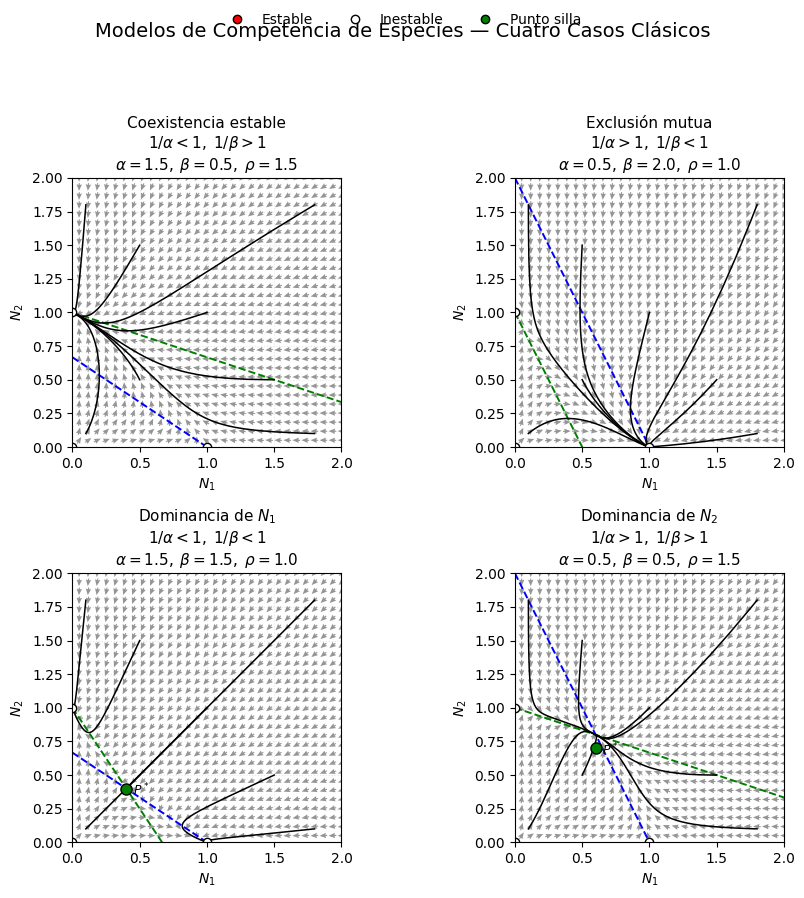

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# === Sistema ===
def competition_system(t, X, alpha, beta, rho):
    x, y = X
    x_dot = x * (1 - x - alpha * y)
    y_dot = y * (rho * (1 - y) - beta * x)
    return [x_dot, y_dot]

# === Punto de coexistencia ===
def coexistence_point(alpha, beta, rho):
    denom = rho - alpha * beta
    if np.isclose(denom, 0):
        return None
    x_star = (rho * (1 - alpha)) / denom
    y_star = 1 - beta * x_star
    return (x_star, y_star)

# === Casos Clásicos ===
casos = [
    ("Coexistencia estable", 1.5, 0.5, 1.5, r'$1/\alpha<1,\;1/\beta>1$'),
    ("Exclusión mutua", 0.5, 2.0, 1.0, r'$1/\alpha>1,\;1/\beta<1$'),
    ("Dominancia de $N_1$", 1.5, 1.5, 1.0, r'$1/\alpha<1,\;1/\beta<1$'),
    ("Dominancia de $N_2$", 0.5, 0.5, 1.5, r'$1/\alpha>1,\;1/\beta>1$')
]

# === Condiciones iniciales ===
initial_conditions = [
    [0.1, 0.1], [0.1, 1.8], [1.8, 0.1], [1.8, 1.8],
    [0.5, 0.5], [1.0, 1.0], [1.5, 0.5], [0.5, 1.5],
]

# === Función para graficar cada caso ===
def plot_case(ax, alpha, beta, rho, title):
    RANGO = 2.0
    N_GRID = 30
    x_vals = np.linspace(0.05, RANGO, N_GRID)
    y_vals = np.linspace(0.05, RANGO, N_GRID)
    X, Y = np.meshgrid(x_vals, y_vals)

    # === Campo de direcciones corregido ===
    U = X * (1 - X - alpha * Y)
    V = Y * (rho * (1 - Y) - beta * X)
    M = np.hypot(U, V)
    M[M == 0] = 1e-6
    U, V = U / M, V / M
    # ⚠️ Si ves el flujo invertido, descomenta esta línea:
    # U, V = -U, -V

    ax.quiver(
        X, Y, U, V,
        color='dimgray',
        alpha=0.7,
        scale=35,
        headwidth=5,
        headlength=6,
        headaxislength=5.5,
        minlength=0.1,
        width=0.004,
        pivot='mid'
    )

    # === Nulclinas ===
    null_line = np.linspace(0, RANGO, 200)
    x_null_y = (1 - null_line) / alpha
    y_null_y = 1 - (beta / rho) * null_line
    ax.plot(null_line, x_null_y, 'b--', linewidth=1.4, label=r'$\dot{N}_1=0$')
    ax.plot(null_line, y_null_y, 'g--', linewidth=1.4, label=r'$\dot{N}_2=0$')

    # === Trayectorias ===
    for X0 in initial_conditions:
        sol = solve_ivp(competition_system, [0, 30], X0, args=(alpha, beta, rho),
                        rtol=1e-6, atol=1e-6, max_step=0.1)
        ax.plot(sol.y[0], sol.y[1], 'k', lw=1.1)

    # === Puntos fijos ===
    ax.plot(0, 0, 'o', markerfacecolor='white', markeredgecolor='k', markersize=6)
    ax.plot(1, 0, 'o', markerfacecolor='white', markeredgecolor='k', markersize=6)
    ax.plot(0, 1, 'o', markerfacecolor='white', markeredgecolor='k', markersize=6)

    P = coexistence_point(alpha, beta, rho)
    if P and 0 <= P[0] <= RANGO and 0 <= P[1] <= RANGO:
        if (1/alpha < 1) and (1/beta > 1):
            color = 'red'    # estable
        elif (1/alpha > 1) and (1/beta < 1):
            color = 'white'  # inestable
        else:
            color = 'green'  # punto silla
        ax.plot(P[0], P[1], 'o', markerfacecolor=color, markeredgecolor='k', markersize=8)
        ax.text(P[0]+0.05, P[1]-0.05, r'$P^*$', fontsize=9)

    # === Ajustes del gráfico ===
    ax.set_xlim(0, RANGO)
    ax.set_ylim(0, RANGO)
    ax.set_aspect('equal')
    ax.set_title(title + "\n" + rf"$\alpha={alpha},\;\beta={beta},\;\rho={rho}$", fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.3)
    ax.set_xlabel(r'$N_1$')
    ax.set_ylabel(r'$N_2$')

# === Figura Final ===
fig, axes = plt.subplots(2, 2, figsize=(9, 9))
axes = axes.flatten()

for ax, (nombre, alpha, beta, rho, label_text) in zip(axes, casos):
    plot_case(ax, alpha, beta, rho, f"{nombre}\n{label_text}")

# === Leyenda ===
handles = [
    plt.Line2D([], [], color='none', marker='o', markerfacecolor='red', markeredgecolor='k', label='Estable'),
    plt.Line2D([], [], color='none', marker='o', markerfacecolor='white', markeredgecolor='k', label='Inestable'),
    plt.Line2D([], [], color='none', marker='o', markerfacecolor='green', markeredgecolor='k', label='Punto silla')
]
fig.legend(handles=handles, loc='upper center', ncol=3, frameon=False)

plt.suptitle("Modelos de Competencia de Especies — Cuatro Casos Clásicos", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()





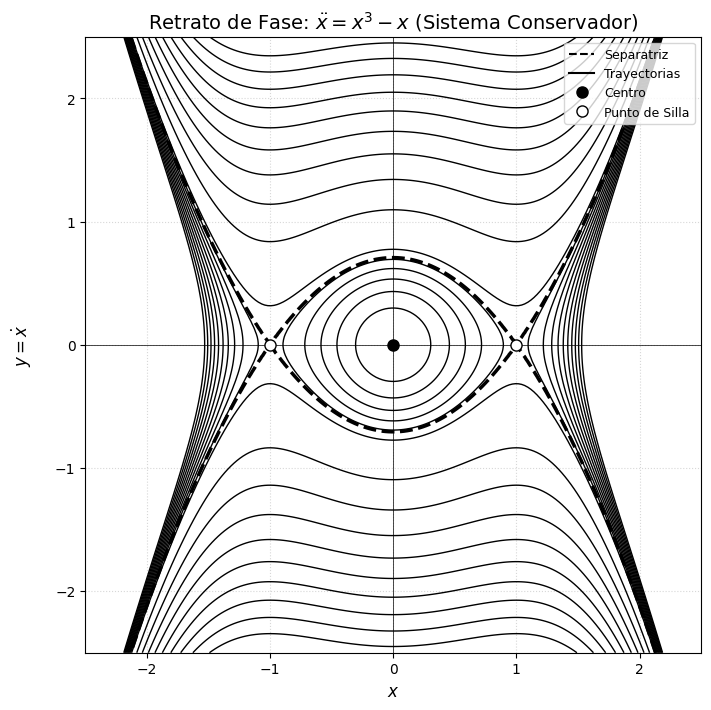

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Definición del Sistema y la Energía Conservada ---

def energy(x, y):
    """Cantidad Conservada (Energía E): E = 0.5*y^2 + 0.5*x^2 - 0.25*x^4"""
    return 0.5 * y**2 + 0.5 * x**2 - 0.25 * x**4

def system_651(X):
    """Campo Vectorial: x_dot = y, y_dot = x^3 - x"""
    x, y = X
    x_dot = y
    y_dot = x**3 - x
    return x_dot, y_dot

# --- 2. Parámetros y Malla ---
RANGO = 2.5
N_CONTOUR_GRID = 200 # <-- Aumentamos la densidad para los contornos (más suave)

x_vals = np.linspace(-RANGO, RANGO, N_CONTOUR_GRID)
y_vals = np.linspace(-RANGO, RANGO, N_CONTOUR_GRID)
X, Y = np.meshgrid(x_vals, y_vals)

# Puntos Fijos
fixed_points = [(0, 0), (1, 0), (-1, 0)]

# Valor de Energía en los Puntos de Silla (Separatriz)
E_SEPARATRIX = energy(1.0, 0.0) # E(±1, 0) = 0.25

# --- 3. Graficación del Retrato de Fase ---
plt.figure(figsize=(8, 8))
ax = plt.gca()

# A) Trayectorias (Líneas de Contorno de la Energía) - MÁS NIVELES Y ENFOQUE EN ELLOS
# Ajustamos los niveles para una distribución más suave y estética
energy_levels_inner = np.linspace(-0.2, E_SEPARATRIX - 0.01, 10) # Órbitas cerradas
energy_levels_outer = np.linspace(E_SEPARATRIX + 0.05, 3.0, 10)   # Órbitas no acotadas
energy_levels = np.concatenate([energy_levels_inner, [E_SEPARATRIX], energy_levels_outer])

# Dibujar las líneas de contorno
CS = plt.contour(X, Y, energy(X, Y),
                 levels=energy_levels,
                 colors='black',
                 linewidths=[2.5 if np.isclose(level, E_SEPARATRIX) else 1.0 for level in energy_levels],
                 linestyles=['--' if np.isclose(level, E_SEPARATRIX) else '-' for level in energy_levels],
                 zorder=3)

# C) Puntos Fijos y Clasificación
# Centros (0, 0)
plt.plot(0, 0, 'ko', markerfacecolor='black', markersize=8, label='Centro (0, 0)', zorder=5)
# Puntos de Silla (±1, 0)
plt.plot(1, 0, 'ko', markerfacecolor='white', markersize=8, label='Punto de Silla', zorder=5)
plt.plot(-1, 0, 'ko', markerfacecolor='white', markersize=8, zorder=5) # No repetimos la etiqueta

# D) Configuración Final
plt.xlabel('$x$ ', fontsize=12)
plt.ylabel(r'$y = \dot{x}$ ', rotation=90, labelpad=15, fontsize=12)
plt.title(r'Retrato de Fase: $\ddot{x} = x^3 - x$ (Sistema Conservador)', fontsize=14)
plt.xlim(-RANGO, RANGO)
plt.ylim(-RANGO, RANGO)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle=':', alpha=0.5) # Rejilla un poco más fuerte
plt.legend([plt.Line2D([0], [0], color='black', ls='--'),
            plt.Line2D([0], [0], color='black', ls='-'),
            plt.Line2D([0], [0], marker='o', color='k', markerfacecolor='black', markersize=8, linestyle='None'),
            plt.Line2D([0], [0], marker='o', color='k', markerfacecolor='white', markersize=8, linestyle='None')],
           ['Separatriz', 'Trayectorias', 'Centro', 'Punto de Silla'],
           loc='upper right', fontsize=9)
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

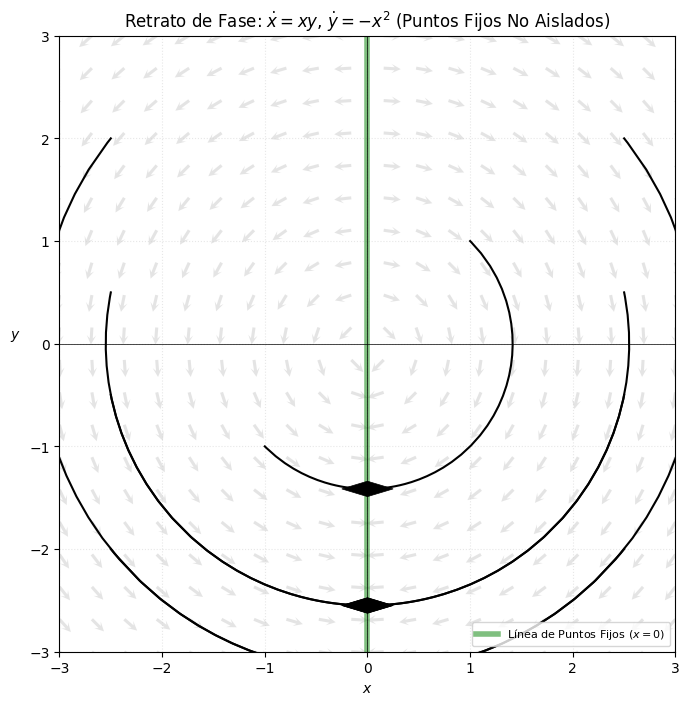

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs ---
def system_6512(t, X):
    """
    Sistema: x_dot = xy, y_dot = -x^2
    Puntos Fijos: Todo el eje y (x=0)
    """
    x, y = X
    x_dot = x * y
    y_dot = -x**2
    return [x_dot, y_dot]

# --- 2. Parámetros del Plano Fase y Malla ---
RANGO = 3.0
N_GRID = 20 # Densidad del campo vectorial
T_SPAN = 10.0 # Tiempo de simulación

x_vals = np.linspace(-RANGO, RANGO, N_GRID)
y_vals = np.linspace(-RANGO, RANGO, N_GRID)
X, Y = np.meshgrid(x_vals, y_vals)

# Calcular el campo vectorial
U, V = system_6512(0, [X, Y])
M = np.hypot(U, V)
M[M == 0] = 1e-6
U_norm, V_norm = U / M, V / M # Normalizar para el quiver

# --- 3. Definición de Trayectorias (Convergencia al Eje Y) ---
# Puntos iniciales para ilustrar la 'caída' hacia el eje Y y la asimetría
initial_conditions = [
    [2.5, 2.0], [2.5, 0.5], [2.5, -0.5], [2.5, -2.0], # Semi-plano Derecho
    [-2.5, 2.0], [-2.5, 0.5], [-2.5, -0.5], [-2.5, -2.0], # Semi-plano Izquierdo
    [1.0, 1.0], [-1.0, -1.0],
]

def plot_trajectory(ax, X0, t_span, color='black', linewidth=1.5):
    """Resuelve la EDO y grafica la trayectoria (solo hacia adelante)."""
    # La simulación hacia adelante (t > 0) muestra la convergencia.
    sol = solve_ivp(system_6512, [0, t_span], X0,
                    dense_output=True, rtol=1e-8, atol=1e-8)

    if len(sol.t) > 2:
        ax.plot(sol.y[0], sol.y[1], color=color, linewidth=linewidth, zorder=4)

        # Añadir flecha al final para indicar la dirección de convergencia
        x_end, y_end = sol.y[0][-1], sol.y[1][-1]
        x_prev, y_prev = sol.y[0][-2], sol.y[1][-2]

        ax.arrow(x_prev, y_prev, x_end - x_prev, y_end - y_prev,
                 color='black', head_width=0.15, head_length=0.25, linewidth=0.5, zorder=5)

# --- 4. Graficación ---
plt.figure(figsize=(8, 8))
ax = plt.gca()

# A) Campo Vectorial (Vector Field)
plt.quiver(X, Y, U_norm, V_norm,
           color='lightgray',
           alpha=0.6,
           headlength=3,
           headaxislength=2,
           width=0.005,
           zorder=2)

# B) Puntos Fijos (Eje Y completo)
plt.axvline(0, color='green', linewidth=4, alpha=0.5, label='Línea de Puntos Fijos ($x=0$)')

# C) Trayectorias (Retrato de Fase)
for X0 in initial_conditions:
    plot_trajectory(ax, X0, T_SPAN, color='black')

# D) Configuración Final
plt.xlabel('$x$')
plt.ylabel('$y$', rotation=0, labelpad=10)
plt.title(r'Retrato de Fase: $\dot{x}=xy$, $\dot{y}=-x^2$ (Puntos Fijos No Aislados)')
plt.xlim(-RANGO, RANGO)
plt.ylim(-RANGO, RANGO)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.legend(loc='lower right', fontsize=8)
plt.grid(True, linestyle=':', alpha=0.3)
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

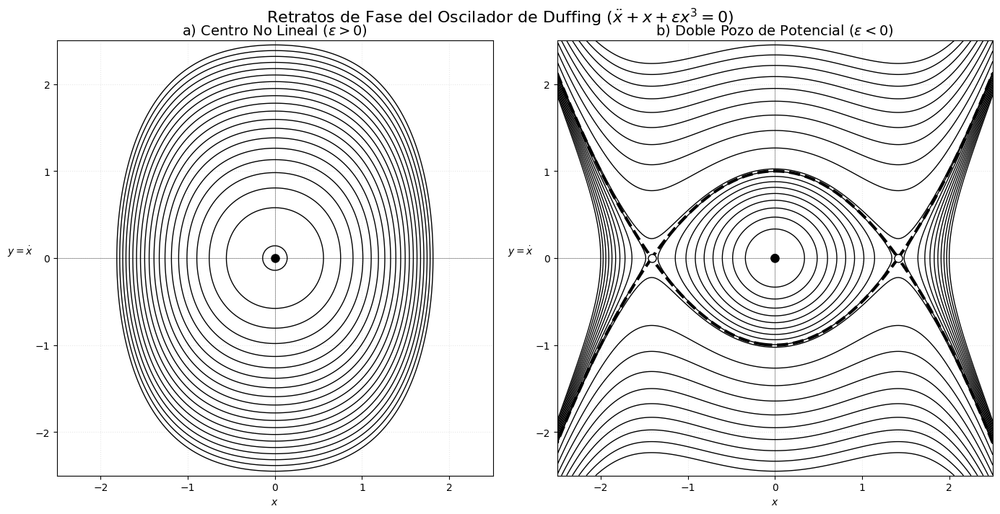

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Definición de la Energía Conservada ---
def energy(x, y, epsilon):
    """Hamiltoniano (Energía) para el Oscilador de Duffing"""
    return 0.5 * y**2 + 0.5 * x**2 + (epsilon / 4) * x**4

# --- 2. Parámetros Globales ---
RANGO = 2.5
N_CONTOUR_GRID = 200

# --- 3. Definición de los Casos ---
duffing_cases = [
    {
        'epsilon': 0.5,
        'title': r'a) Centro No Lineal ($\varepsilon > 0$)',
        'xmax': 2.5,
        'ymax': 2.5,
        'levels': np.linspace(0.01, 3.0, 20) # Órbitas cerradas
    },
    {
        'epsilon': -0.5,
        'title': r'b) Doble Pozo de Potencial ($\varepsilon < 0$)',
        'xmax': 2.5,
        'ymax': 2.5,
        'levels': None # Calcularemos niveles específicos
    }
]

# --- 4. Generación de la Figura ---
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
fig.suptitle(r'Retratos de Fase del Oscilador de Duffing ($\ddot{x} + x + \varepsilon x^3 = 0$)', fontsize=16)

for idx, case in enumerate(duffing_cases):
    eps = case['epsilon']
    ax = axes[idx]

    x_vals = np.linspace(-case['xmax'], case['xmax'], N_CONTOUR_GRID)
    y_vals = np.linspace(-case['ymax'], case['ymax'], N_CONTOUR_GRID)
    X, Y = np.meshgrid(x_vals, y_vals)

    H_vals = energy(X, Y, eps)

    # --- NIVELES ESPECÍFICOS PARA EL CASO EPS < 0 ---
    if eps < 0:
        # Puntos fijos de silla (x_silla = ±1/sqrt(|eps|))
        x_silla = 1 / np.sqrt(abs(eps))
        H_SEPARATRIX = energy(x_silla, 0, eps) # Valor de la energía en el punto de silla

        # 1. Órbitas internas (alrededor de x=0)
        levels_inner = np.linspace(0.001, H_SEPARATRIX * 0.99, 10)
        # 2. La separatriz (homoclinica)
        level_separatrix = [H_SEPARATRIX]
        # 3. Órbitas externas (no acotadas)
        levels_outer = np.linspace(H_SEPARATRIX * 1.05, 3.0, 10)

        levels = np.concatenate([levels_inner, level_separatrix, levels_outer])

        # Puntos Fijos Adicionales
        pf_sillas = [ (x_silla, 0), (-x_silla, 0) ]
        pf_centros = [ (0, 0) ]

    else: # Caso EPS > 0
        levels = case['levels']
        pf_centros = [ (0, 0) ]
        pf_sillas = [] # No hay sillas

    # --- Dibujar las líneas de contorno (Trayectorias) ---
    CS = ax.contour(X, Y, H_vals,
                    levels=levels,
                    colors='black',
                    linewidths=[3.0 if np.isclose(level, H_SEPARATRIX) else 1.0 for level in levels] if eps < 0 else 1.0,
                    linestyles=['--' if np.isclose(level, H_SEPARATRIX) else '-' for level in levels] if eps < 0 else '-',
                    zorder=3)

    # --- Marcar Puntos Fijos ---
    # Centros (Origen)
    for px, py in pf_centros:
        ax.plot(px, py, 'ko', markerfacecolor='black', markersize=8, label='Centro', zorder=5)

    # Sillas (Solo para eps < 0)
    for px, py in pf_sillas:
        ax.plot(px, py, 'ko', markerfacecolor='white', markersize=8, label='Punto de Silla', zorder=5)

    # --- Estilo Final ---
    ax.set_title(case['title'], fontsize=14)
    ax.set_xlabel('$x$')
    ax.set_ylabel(r'$y = \dot{x}$', rotation=0, labelpad=15)
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.axvline(0, color='gray', linewidth=0.5)
    ax.set_xlim(-case['xmax'], case['xmax'])
    ax.set_ylim(-case['ymax'], case['ymax'])
    ax.grid(True, linestyle=':', alpha=0.3)
    ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()

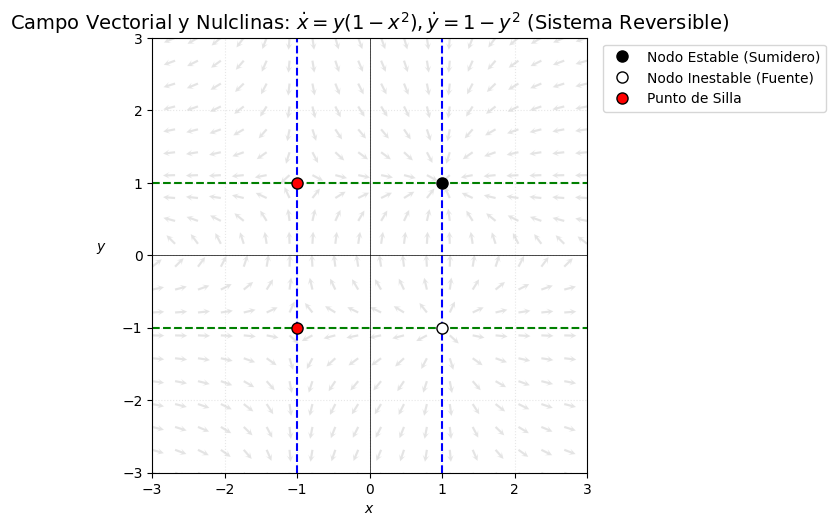

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs ---
def system_661(t, X):
    """Sistema Reversible: x_dot = y(1 - x^2), y_dot = 1 - y^2"""
    x, y = X
    x_dot = y * (1 - x**2)
    y_dot = 1 - y**2
    return [x_dot, y_dot]

# --- 2. Parámetros del Plano Fase y Malla ---
RANGO = 3.0
N_GRID = 20 # Densidad del campo vectorial

x_vals = np.linspace(-RANGO, RANGO, N_GRID)
y_vals = np.linspace(-RANGO, RANGO, N_GRID)
X, Y = np.meshgrid(x_vals, y_vals)

# Calcular el campo vectorial
U, V = system_661(0, [X, Y])
M = np.hypot(U, V)
M[M == 0] = 1e-6
U_norm, V_norm = U / M, V / M # Normalizar para el quiver

# --- 3. Nulclinas y Puntos Fijos ---
null_line = np.linspace(-RANGO, RANGO, 100)

# Nulclina x_dot = 0 (Vertical): x = ±1 o y = 0
x_null_x1 = np.ones_like(null_line) # x = 1
x_null_x_1 = -np.ones_like(null_line) # x = -1
# Nulclina y_dot = 0 (Horizontal): y = ±1
y_null_y1 = np.ones_like(null_line) # y = 1
y_null_y_1 = -np.ones_like(null_line) # y = -1

# Puntos Fijos (Clasificación para colores)
PF_DATA = [
    (1, 1, 'black', 'Nodo Estable (Sumidero)'),
    (1, -1, 'white', 'Nodo Inestable (Fuente)'),
    (-1, 1, 'red', 'Punto de Silla'),
    (-1, -1, 'red', 'Punto de Silla')
]

# --- 4. Graficación Final ---
plt.figure(figsize=(8, 8))
ax = plt.gca()

# A) Campo Vectorial (Fondo gris)
plt.quiver(X, Y, U_norm, V_norm, color='lightgray', alpha=0.6, headlength=3, headaxislength=2, width=0.005, zorder=2)

# B) Nulclinas
plt.plot(x_null_x1, null_line, 'b--', label=r'$\dot{x}=0$ ($x=\pm 1$)', linewidth=1.5)
plt.plot(x_null_x_1, null_line, 'b--', linewidth=1.5)
plt.plot(null_line, y_null_y1, 'g--', label=r'$\dot{y}=0$ ($y=\pm 1$)', linewidth=1.5)
plt.plot(null_line, y_null_y_1, 'g--', linewidth=1.5)

# C) Puntos Fijos (Clasificación Clara)
legend_handles = []
plotted_labels = set()

for px, py, color, label in PF_DATA:
    if label == 'Nodo Estable (Sumidero)':
        facecolor = 'black'
    elif label == 'Nodo Inestable (Fuente)':
        facecolor = 'white'
    elif label == 'Punto de Silla':
        facecolor = 'red'

    plt.plot(px, py, 'ko', markerfacecolor=facecolor, markersize=8, zorder=5)

    # Crear leyenda una sola vez por tipo
    if label not in plotted_labels:
        handle = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=facecolor, markeredgecolor='k', markersize=8, linestyle='')
        legend_handles.append(handle)
        plotted_labels.add(label)

# D) Configuración Final
plt.xlabel('$x$')
plt.ylabel('$y$', rotation=0, labelpad=15)
plt.title(r'Campo Vectorial y Nulclinas: $\dot{x}=y(1-x^2), \dot{y}=1-y^2$ (Sistema Reversible)', fontsize=14)
plt.xlim(-RANGO, RANGO)
plt.ylim(-RANGO, RANGO)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle=':', alpha=0.3)
plt.gca().set_aspect('equal', adjustable='box')

plt.legend(legend_handles, list(plotted_labels), loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout(rect=[0, 0, 0.95, 1])
plt.show()

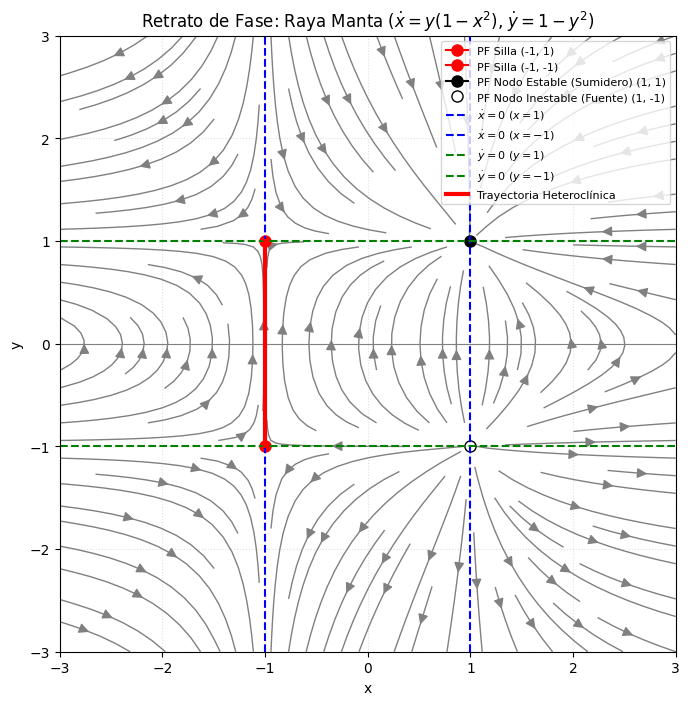

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Definición del Sistema (Ejercicio 6.6.6) ---
def sistema_raya_manta(X, t):
    """Define el sistema de ecuaciones diferenciales: ẋ = y(1 - x²), ẏ = 1 - y²."""
    x, y = X
    dxdt = y * (1 - x**2)
    dydt = 1 - y**2
    return np.array([dxdt, dydt])

# --- 2. Configuración y Malla ---
x_min, x_max = -3.0, 3.0
y_min, y_max = -3.0, 3.0

# Crear una malla para el campo vectorial (50x50 puntos)
x = np.linspace(x_min, x_max, 50)
y = np.linspace(y_min, y_max, 50)
X, Y = np.meshgrid(x, y)
t = 0

# Calcular las componentes del flujo (U y V)
Flujo = sistema_raya_manta([X, Y], t)
U, V = Flujo[0], Flujo[1]

# Normalizar el flujo (opcional: para flechas de longitud uniforme)
N = np.sqrt(U**2 + V**2)
U = U / N
V = V / N

# --- 3. Graficación ---
plt.figure(figsize=(8, 8))

# Dibujar el campo vectorial (streamplot)
plt.streamplot(X, Y, U, V, density=1.2, linewidth=1, color='gray', cmap='viridis', arrowsize=1.5)

# Puntos Fijos (PFs)
PFs = [(-1, 1), (-1, -1), (1, 1), (1, -1)]
clasificacion = ['Silla', 'Silla', 'Nodo Estable (Sumidero)', 'Nodo Inestable (Fuente)']
colores = ['red', 'red', 'black', 'white']

for (px, py), color, label in zip(PFs, colores, clasificacion):
    # Usar un borde negro para los nodos inestables (blancos) para hacerlos visibles
    edge_color = 'black' if color == 'white' else None
    plt.plot(px, py, marker='o', markersize=8, color=color, markeredgecolor=edge_color, label=f'PF {label} ({px}, {py})')

# --- 4. Dibujar Nulclinas y Ciclo Heteroclínico (x=-1) ---

# Nulclina ẋ = 0 (y=0 o x=±1)
plt.axhline(y=0, color='gray', linestyle='-', linewidth=0.8) # Eje x
plt.axvline(x=1, color='blue', linestyle='--', linewidth=1.5, label=r'$\dot{x}=0$ ($x=1$)')
plt.axvline(x=-1, color='blue', linestyle='--', linewidth=1.5, label=r'$\dot{x}=0$ ($x=-1$)')

# Nulclina ẏ = 0 (y=±1)
plt.axhline(y=1, color='green', linestyle='--', linewidth=1.5, label=r'$\dot{y}=0$ ($y=1$)')
plt.axhline(y=-1, color='green', linestyle='--', linewidth=1.5, label=r'$\dot{y}=0$ ($y=-1$)')

# Resaltar la trayectoria heteroclínica (x=-1, entre y=-1 y y=1)
plt.plot([-1, -1], [-1, 1], 'r-', linewidth=3, label='Trayectoria Heteroclínica')


plt.title(r'Retrato de Fase: Raya Manta ($\dot{x} = y(1 - x^2)$, $\dot{y} = 1 - y^2$)')
plt.xlabel('x')
plt.ylabel('y')
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.grid(True, linestyle=':', alpha=0.4)
plt.gca().set_aspect('equal', adjustable='box')
plt.legend(loc='upper right', fontsize=8)
plt.show()

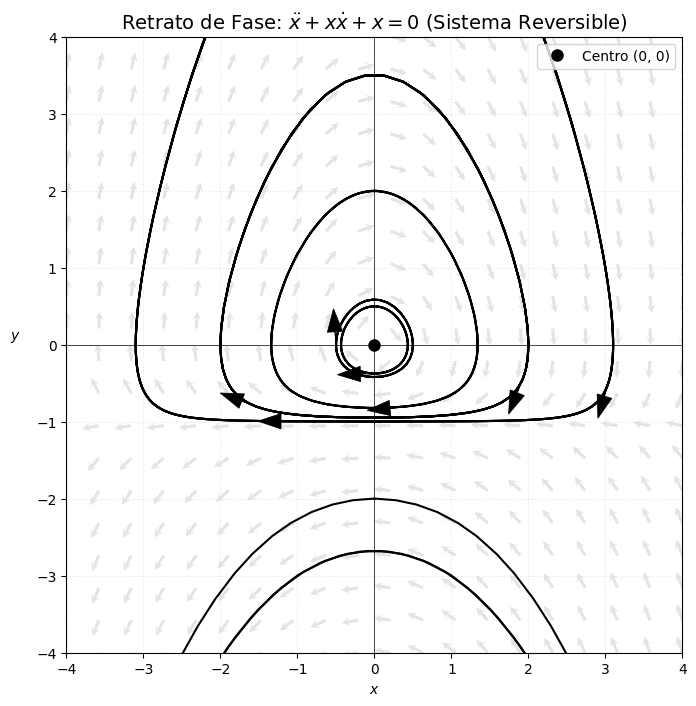

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs ---
def system_667(t, X):
    """Sistema Reversible: x_dot = y, y_dot = -x - xy"""
    x, y = X
    x_dot = y
    y_dot = -x - x * y
    return [x_dot, y_dot]

# --- 2. Parámetros y Malla ---
RANGO = 4.0
N_GRID = 20
T_SPAN = 10.0

x_vals, y_vals = np.linspace(-RANGO, RANGO, N_GRID), np.linspace(-RANGO, RANGO, N_GRID)
X, Y = np.meshgrid(x_vals, y_vals)
U, V = system_667(0, [X, Y])
M = np.hypot(U, V)
M[M == 0] = 1e-6
U_norm, V_norm = U / M, V / M

# --- 3. Trayectorias (Simulación) ---
# Elegimos puntos iniciales que muestren la simetría y el comportamiento global
initial_conditions = [
    [0.5, 0.0], [0.0, 0.5], # Cerca del centro
    [2.0, 0.0], [0.0, 2.0], # Lejos del centro
    [-2.0, 0.0], [0.0, -2.0],
    [3.0, 1.0], [-3.0, 1.0],
    [1.0, -3.0], [-1.0, -3.0],
]

def plot_trajectory(ax, X0, t_span, color='black', linewidth=1.5):
    """Resuelve la EDO y grafica la trayectoria (hacia adelante y atrás)."""

    # Simulación hacia adelante
    sol_fwd = solve_ivp(system_667, [0, t_span], X0, rtol=1e-7, atol=1e-7)
    ax.plot(sol_fwd.y[0], sol_fwd.y[1], color=color, linewidth=linewidth, zorder=4)

    # Simulación hacia atrás (esencial para la simetría y ver la órbita completa)
    sol_bwd = solve_ivp(system_667, [0, -t_span], X0, rtol=1e-7, atol=1e-7)
    ax.plot(sol_bwd.y[0], sol_bwd.y[1], color=color, linewidth=linewidth, zorder=4)

    # Añadir flecha (solo una por trayectoria)
    if len(sol_fwd.t) > 10:
        idx = len(sol_fwd.t) // 3
        x_start, y_start = sol_fwd.y[0][idx], sol_fwd.y[1][idx]
        v_mid = system_667(0, [x_start, y_start])
        mag_arr = np.hypot(v_mid[0], v_mid[1])
        if mag_arr > 1e-4:
            ax.arrow(x_start, y_start, v_mid[0] * 0.2 / mag_arr, v_mid[1] * 0.2 / mag_arr,
                     color='black', head_width=0.2, head_length=0.3, linewidth=0.5, zorder=5)

# --- 4. Graficación Final ---
plt.figure(figsize=(8, 8))
ax = plt.gca()

# A) Campo Vectorial
plt.quiver(X, Y, U_norm, V_norm, color='lightgray', alpha=0.6, headlength=3, headaxislength=2, width=0.005, zorder=2)

# B) Trayectorias (Dibujando el Retrato de Fase)
for X0 in initial_conditions:
    plot_trajectory(ax, X0, T_SPAN, color='black')

# C) Puntos Fijos
plt.plot(0, 0, 'ko', markerfacecolor='black', markersize=8, label='Centro (0, 0)', zorder=5)

# D) Configuración Final
plt.xlabel('$x$')
plt.ylabel('$y$', rotation=0, labelpad=15)
plt.title(r'Retrato de Fase: $\ddot{x} + x\dot{x} + x = 0$ (Sistema Reversible)', fontsize=14)
plt.xlim(-RANGO, RANGO)
plt.ylim(-RANGO, RANGO)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle=':', alpha=0.3)
plt.gca().set_aspect('equal', adjustable='box')
plt.legend(loc='upper right')
plt.show()

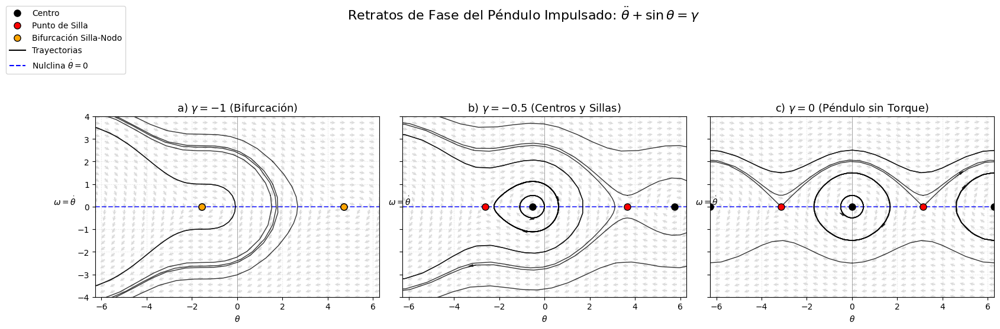

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs ---
def pendulum_system(t, X, gamma):
    """
    Sistema del péndulo impulsado por torque constante:
    theta_dot = omega
    omega_dot = gamma - sin(theta)
    """
    theta, omega = X
    theta_dot = omega
    omega_dot = gamma - np.sin(theta)
    return [theta_dot, omega_dot]

# --- 2. Parámetros para la Graficación ---
THETA_RANGE_PLOT = 2 * np.pi  # Rango de theta para visualizar varios ciclos
OMEGA_RANGE_PLOT = 4.0        # Rango de omega
N_GRID = 30                   # Densidad del campo vectorial
T_SPAN = 20.0                 # Tiempo de simulación para las trayectorias

# Valores de gamma a graficar
GAMMAS = [-1, -0.5, 0]
TITLES = [r'a) $\gamma = -1$ (Bifurcación)',
          r'b) $\gamma = -0.5$ (Centros y Sillas)',
          r'c) $\gamma = 0$ (Péndulo sin Torque)']

# Puntos iniciales para las trayectorias (ajustados para cada gamma)
initial_conditions_set = {
    -1: [
        [np.pi/2, 1.0], [np.pi/2, 2.0],  # Rotación
        [np.pi/2 - 0.1, 0.5], [np.pi/2 + 0.1, 0.5], # Cerca del silla-nodo
        [-np.pi/2, 1.0], [-np.pi/2, -1.0],
    ],
    -0.5: [
        [np.arcsin(-0.5), 0.5],             # Oscilación alrededor del centro (-0.52 rad)
        [np.pi - np.arcsin(-0.5), 0.5],     # Cerca del silla (3.66 rad)
        [0.0, 1.0], [0.0, -1.0],            # Entre los PF
        [0.0, 2.0], [0.0, -2.0],            # Rotación
        [-np.pi, 2.5], [np.pi, -2.5]
    ],
    0: [
        [0.0, 0.5], [0.0, 1.5],             # Oscilación alrededor del centro (0)
        [np.pi, 0.5], [np.pi - 0.1, 0.1],   # Cerca del silla (pi)
        [0.0, 2.5], [0.0, -2.5],            # Rotación
        [-np.pi, 1.5], [2*np.pi, -1.5]
    ]
}

# --- Función para plotear trayectorias ---
def plot_trajectory(ax, X0, gamma, t_span, color='black', linewidth=1.0, alpha=0.8):
    """Resuelve la EDO y grafica la trayectoria (hacia adelante y atrás) con flechas."""

    # Simulación hacia adelante
    sol_fwd = solve_ivp(pendulum_system, [0, t_span], X0, args=(gamma,), rtol=1e-6, atol=1e-6)
    ax.plot(sol_fwd.y[0], sol_fwd.y[1], color=color, linewidth=linewidth, alpha=alpha, zorder=4)

    # Simulación hacia atrás (para ver órbitas completas)
    sol_bwd = solve_ivp(pendulum_system, [0, -t_span], X0, args=(gamma,), rtol=1e-6, atol=1e-6)
    ax.plot(sol_bwd.y[0], sol_bwd.y[1], color=color, linewidth=linewidth, alpha=alpha, zorder=4)

    # Añadir flecha (solo una por trayectoria en la parte fwd)
    if len(sol_fwd.t) > 10:
        idx = len(sol_fwd.t) // 2 # Flecha en la mitad de la trayectoria
        x_start, y_start = sol_fwd.y[0][idx], sol_fwd.y[1][idx]
        v_mid = pendulum_system(0, [x_start, y_start], gamma)
        mag_arr = np.hypot(v_mid[0], v_mid[1])
        if mag_arr > 1e-4:
            ax.arrow(x_start, y_start, v_mid[0] * 0.15 / mag_arr, v_mid[1] * 0.15 / mag_arr,
                     color=color, head_width=0.1, head_length=0.2, linewidth=0.5, zorder=5, alpha=alpha)

# --- 3. Generar los Retratos de Fase ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
fig.suptitle(r'Retratos de Fase del Péndulo Impulsado: $\ddot{\theta} + \sin\theta = \gamma$', fontsize=16)

for i, gamma_val in enumerate(GAMMAS):
    ax = axes[i]

    # Malla para el campo vectorial
    theta_vals = np.linspace(-THETA_RANGE_PLOT, THETA_RANGE_PLOT, N_GRID)
    omega_vals = np.linspace(-OMEGA_RANGE_PLOT, OMEGA_RANGE_PLOT, N_GRID)
    THETA, OMEGA = np.meshgrid(theta_vals, omega_vals)

    # Calcular el campo vectorial
    U, V = pendulum_system(0, [THETA, OMEGA], gamma_val)
    M = np.hypot(U, V)
    M[M == 0] = 1e-6
    U_norm, V_norm = U / M, V / M # Normalizar para el quiver

    # Plotear el campo vectorial
    ax.quiver(THETA, OMEGA, U_norm, V_norm, color='lightgray', alpha=0.8,
              headlength=3, headaxislength=2, width=0.005, zorder=2)

    # --- Puntos Fijos ---
    if abs(gamma_val) <= 1:
        theta_star1 = np.arcsin(gamma_val)
        theta_star2 = np.pi - np.arcsin(gamma_val)

        for k in range(-1, 2):
            current_theta1 = theta_star1 + 2 * k * np.pi
            if np.isclose(np.cos(current_theta1), 0, atol=1e-4):
                 ax.plot(current_theta1, 0, 'ko', markerfacecolor='orange', markersize=8, zorder=5)
            elif np.cos(current_theta1) > 0:
                ax.plot(current_theta1, 0, 'ko', markerfacecolor='black', markersize=8, zorder=5)
            else:
                ax.plot(current_theta1, 0, 'ko', markerfacecolor='red', markersize=8, zorder=5)

            current_theta2 = theta_star2 + 2 * k * np.pi
            if not np.isclose(current_theta1, current_theta2, atol=1e-4):
                if np.isclose(np.cos(current_theta2), 0, atol=1e-4):
                    ax.plot(current_theta2, 0, 'ko', markerfacecolor='orange', markersize=8, zorder=5)
                elif np.cos(current_theta2) > 0:
                    ax.plot(current_theta2, 0, 'ko', markerfacecolor='black', markersize=8, zorder=5)
                else:
                    ax.plot(current_theta2, 0, 'ko', markerfacecolor='red', markersize=8, zorder=5)

    # --- Nulclinas ---
    ax.axhline(0, color='blue', linestyle='--', alpha=0.7, label=r'$\dot{\theta}=0$')

    # --- TRAYECTORIAS NEGRAS ---
    for X0 in initial_conditions_set[gamma_val]:
        plot_trajectory(ax, X0, gamma_val, T_SPAN, color='black')

    # --- Configuración del Subplot ---
    ax.set_title(TITLES[i], fontsize=13)
    ax.set_xlabel(r'$\theta$')
    ax.set_ylabel(r'$\omega = \dot{\theta}$', rotation=0, labelpad=15 if i == 0 else 0)
    ax.set_xlim(-THETA_RANGE_PLOT, THETA_RANGE_PLOT)
    ax.set_ylim(-OMEGA_RANGE_PLOT, OMEGA_RANGE_PLOT)
    ax.grid(True, linestyle=':', alpha=0.4)
    ax.axvline(0, color='gray', linewidth=0.5)
    ax.set_aspect('equal', adjustable='box')

# --- Leyenda Global ---
legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markeredgecolor='k', markersize=8, linestyle='', label='Centro'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markeredgecolor='k', markersize=8, linestyle='', label='Punto de Silla'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markeredgecolor='k', markersize=8, linestyle='', label='Bifurcación Silla-Nodo'),
    plt.Line2D([0], [0], color='black', linewidth=1.5, linestyle='-', label='Trayectorias'),
    plt.Line2D([0], [0], color='blue', linewidth=1.5, linestyle='--', label=r'Nulclina $\dot{\theta}=0$')
]
fig.legend(handles=legend_handles, loc='upper left', bbox_to_anchor=(0.01, 0.99), frameon=True, fontsize=10)

plt.tight_layout(rect=[0.05, 0, 0.95, 0.9])
plt.show()

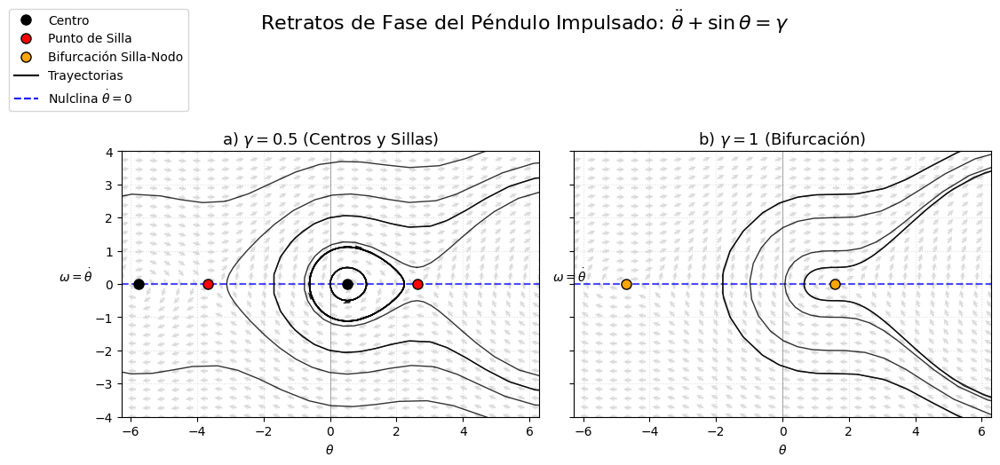

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs ---
def pendulum_system(t, X, gamma):
    """
    Sistema del péndulo impulsado por torque constante:
    theta_dot = omega
    omega_dot = gamma - sin(theta)
    """
    theta, omega = X
    theta_dot = omega
    omega_dot = gamma - np.sin(theta)
    return [theta_dot, omega_dot]

# --- 2. Parámetros para la Graficación ---
THETA_RANGE_PLOT = 2 * np.pi  # Rango de theta para visualizar varios ciclos
OMEGA_RANGE_PLOT = 4.0        # Rango de omega
N_GRID = 30                   # Densidad del campo vectorial
T_SPAN = 20.0                 # Tiempo de simulación para las trayectorias

# Valores de gamma a graficar
GAMMAS = [0.5, 1]
TITLES = [r'a) $\gamma = 0.5$ (Centros y Sillas)',
          r'b) $\gamma = 1$ (Bifurcación)']

# Puntos iniciales para las trayectorias (ajustados para cada gamma)
initial_conditions_set = {
    0.5: [
        [np.arcsin(0.5), 0.5],              # Oscilación alrededor del centro (0.52 rad)
        [np.pi - np.arcsin(0.5), 0.5],      # Cerca del silla (2.61 rad)
        [0.0, 1.0], [0.0, -1.0],            # Entre los PF
        [0.0, 2.0], [0.0, -2.0],            # Rotación
        [-np.pi, 2.5], [np.pi, -2.5]
    ],
    1: [
        [np.pi/2, 1.0], [np.pi/2, 2.0],     # Rotación
        [np.pi/2 - 0.1, 0.5], [np.pi/2 + 0.1, 0.5], # Cerca del silla-nodo
        [-np.pi/2, 1.0], [-np.pi/2, -1.0],
    ]
}

# --- Función para plotear trayectorias ---
def plot_trajectory(ax, X0, gamma, t_span, color='black', linewidth=1.0, alpha=0.8):
    """Resuelve la EDO y grafica la trayectoria (hacia adelante y atrás) con flechas."""

    # Simulación hacia adelante
    sol_fwd = solve_ivp(pendulum_system, [0, t_span], X0, args=(gamma,), rtol=1e-6, atol=1e-6)
    ax.plot(sol_fwd.y[0], sol_fwd.y[1], color=color, linewidth=linewidth, alpha=alpha, zorder=4)

    # Simulación hacia atrás (para ver órbitas completas)
    sol_bwd = solve_ivp(pendulum_system, [0, -t_span], X0, args=(gamma,), rtol=1e-6, atol=1e-6)
    ax.plot(sol_bwd.y[0], sol_bwd.y[1], color=color, linewidth=linewidth, alpha=alpha, zorder=4)

    # Añadir flecha (solo una por trayectoria en la parte fwd)
    if len(sol_fwd.t) > 10:
        idx = len(sol_fwd.t) // 2 # Flecha en la mitad de la trayectoria
        x_start, y_start = sol_fwd.y[0][idx], sol_fwd.y[1][idx]
        v_mid = pendulum_system(0, [x_start, y_start], gamma)
        mag_arr = np.hypot(v_mid[0], v_mid[1])
        if mag_arr > 1e-4:
            ax.arrow(x_start, y_start, v_mid[0] * 0.15 / mag_arr, v_mid[1] * 0.15 / mag_arr,
                     color=color, head_width=0.1, head_length=0.2, linewidth=0.5, zorder=5, alpha=alpha)

# --- 3. Generar los Retratos de Fase ---
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True) # Solo 2 subplots ahora
fig.suptitle(r'Retratos de Fase del Péndulo Impulsado: $\ddot{\theta} + \sin\theta = \gamma$', fontsize=16)

# Asegurarse de que axes sea un array si solo hay un subplot
if not isinstance(axes, np.ndarray):
    axes = [axes]

for i, gamma_val in enumerate(GAMMAS):
    ax = axes[i]

    # Malla para el campo vectorial
    theta_vals = np.linspace(-THETA_RANGE_PLOT, THETA_RANGE_PLOT, N_GRID)
    omega_vals = np.linspace(-OMEGA_RANGE_PLOT, OMEGA_RANGE_PLOT, N_GRID)
    THETA, OMEGA = np.meshgrid(theta_vals, omega_vals)

    # Calcular el campo vectorial
    U, V = pendulum_system(0, [THETA, OMEGA], gamma_val)
    M = np.hypot(U, V)
    M[M == 0] = 1e-6
    U_norm, V_norm = U / M, V / M # Normalizar para el quiver

    # Plotear el campo vectorial
    ax.quiver(THETA, OMEGA, U_norm, V_norm, color='lightgray', alpha=0.8,
              headlength=3, headaxislength=2, width=0.005, zorder=2)

    # --- Puntos Fijos ---
    if abs(gamma_val) <= 1:
        theta_star1 = np.arcsin(gamma_val)
        theta_star2 = np.pi - np.arcsin(gamma_val)

        for k in range(-1, 2):
            current_theta1 = theta_star1 + 2 * k * np.pi
            if np.isclose(np.cos(current_theta1), 0, atol=1e-4):
                 ax.plot(current_theta1, 0, 'ko', markerfacecolor='orange', markersize=8, zorder=5)
            elif np.cos(current_theta1) > 0:
                ax.plot(current_theta1, 0, 'ko', markerfacecolor='black', markersize=8, zorder=5)
            else:
                ax.plot(current_theta1, 0, 'ko', markerfacecolor='red', markersize=8, zorder=5)

            current_theta2 = theta_star2 + 2 * k * np.pi
            if not np.isclose(current_theta1, current_theta2, atol=1e-4):
                if np.isclose(np.cos(current_theta2), 0, atol=1e-4):
                    ax.plot(current_theta2, 0, 'ko', markerfacecolor='orange', markersize=8, zorder=5)
                elif np.cos(current_theta2) > 0:
                    ax.plot(current_theta2, 0, 'ko', markerfacecolor='black', markersize=8, zorder=5)
                else:
                    ax.plot(current_theta2, 0, 'ko', markerfacecolor='red', markersize=8, zorder=5)

    # --- Nulclinas ---
    ax.axhline(0, color='blue', linestyle='--', alpha=0.7, label=r'$\dot{\theta}=0$')

    # --- TRAYECTORIAS NEGRAS ---
    for X0 in initial_conditions_set[gamma_val]:
        plot_trajectory(ax, X0, gamma_val, T_SPAN, color='black')

    # --- Configuración del Subplot ---
    ax.set_title(TITLES[i], fontsize=13)
    ax.set_xlabel(r'$\theta$')
    ax.set_ylabel(r'$\omega = \dot{\theta}$', rotation=0, labelpad=15 if i == 0 else 0)
    ax.set_xlim(-THETA_RANGE_PLOT, THETA_RANGE_PLOT)
    ax.set_ylim(-OMEGA_RANGE_PLOT, OMEGA_RANGE_PLOT)
    ax.grid(True, linestyle=':', alpha=0.4)
    ax.axvline(0, color='gray', linewidth=0.5)
    ax.set_aspect('equal', adjustable='box')

# --- Leyenda Global ---
legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markeredgecolor='k', markersize=8, linestyle='', label='Centro'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markeredgecolor='k', markersize=8, linestyle='', label='Punto de Silla'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markeredgecolor='k', markersize=8, linestyle='', label='Bifurcación Silla-Nodo'),
    plt.Line2D([0], [0], color='black', linewidth=1.5, linestyle='-', label='Trayectorias'),
    plt.Line2D([0], [0], color='blue', linewidth=1.5, linestyle='--', label=r'Nulclina $\dot{\theta}=0$')
]
fig.legend(handles=legend_handles, loc='upper left', bbox_to_anchor=(0.01, 0.99), frameon=True, fontsize=10)

plt.tight_layout(rect=[0.05, 0, 0.95, 1])
plt.show()

/tmp/ipython-input-1182372137.py:23: RuntimeWarning: divide by zero encountered in scalar divide
  cot_phi = np.where(condition, 0.0, np.cos(phi) / sin_phi)


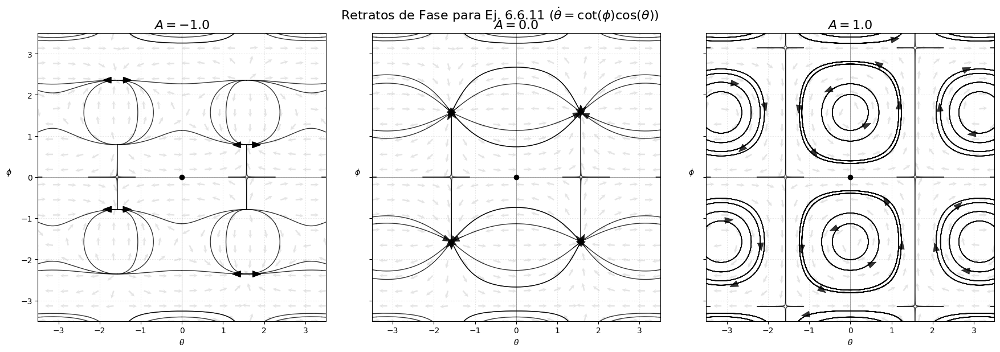

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs (Ej. 6.6.11) ---
def system_6611(t, X, A):
    """
    Sistema acoplado:
    theta_dot = cot(phi) * cos(theta)
    phi_dot = (cos^2(phi) + A * sin^2(phi)) * sin(theta)
    """
    theta, phi = X

    # 🚨 CORRECCIÓN CLAVE: Usamos np.where para manejar la singularidad de forma vectorizada
    sin_phi = np.sin(phi)

    # Condición: ¿Está sin(phi) cerca de 0?
    condition = np.isclose(sin_phi, 0, atol=1e-3)

    # Usamos np.where(condición, valor_si_verdadero, valor_si_falso)
    # Si sin(phi) ~ 0, cot_phi = 0.0 (valor_si_verdadero)
    # Si sin(phi) != 0, cot_phi = cos(phi)/sin(phi) (valor_si_falso)
    cot_phi = np.where(condition, 0.0, np.cos(phi) / sin_phi)

    theta_dot = cot_phi * np.cos(theta)
    phi_dot = (np.cos(phi)**2 + A * np.sin(phi)**2) * np.sin(theta)

    # Aseguramos que la EDO devuelva una lista (necesario para solve_ivp si X es un array)
    return [theta_dot, phi_dot]

# --- 2. Parámetros Globales ---
A_VALUES = [-1.0, 0.0, 1.0]
T_SPAN = 20.0 # Tiempo de simulación
RANGO_THETA = 3.5 # ~pi
RANGO_PHI = 3.5 # ~pi
N_GRID = 20

# --- 3. Puntos Iniciales ---
initial_conditions = []
grid_points_theta = np.linspace(-RANGO_THETA + 0.1, RANGO_THETA - 0.1, 7)
grid_points_phi = np.linspace(-RANGO_PHI + 0.1, RANGO_PHI - 0.1, 7)

for r in grid_points_phi:
    for p in grid_points_theta:
        initial_conditions.append([p, r])

# --- 4. Generación de la Figura ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
fig.suptitle(r'Retratos de Fase para Ej. 6.6.11 ($\dot{\theta} = \cot(\phi) \cos(\theta)$)', fontsize=16)

def plot_trajectory(ax, X0, A_val, t_span, color='black', linewidth=1.0, alpha=0.8):
    """Resuelve la EDO y grafica la trayectoria (hacia adelante y atrás) con flechas."""

    # Simulación
    sol_fwd = solve_ivp(system_6611, [0, t_span], X0, args=(A_val,), rtol=1e-6, atol=1e-6, max_step=0.05)
    sol_bwd = solve_ivp(system_6611, [0, -t_span], X0, args=(A_val,), rtol=1e-6, atol=1e-6, max_step=0.05)

    # Plotear la trayectoria
    ax.plot(sol_fwd.y[0], sol_fwd.y[1], color=color, linewidth=linewidth, alpha=alpha, zorder=4)
    ax.plot(sol_bwd.y[0], sol_bwd.y[1], color=color, linewidth=linewidth, alpha=alpha, zorder=4)

    # Añadir flecha (solo una por trayectoria)
    if len(sol_fwd.t) > 10:
        idx = len(sol_fwd.t) // 3
        x_start, y_start = sol_fwd.y[0][idx], sol_fwd.y[1][idx]
        v_mid = system_6611(0, [x_start, y_start], A_val)
        mag_arr = np.hypot(v_mid[0], v_mid[1])
        if mag_arr > 1e-4:
            ax.arrow(x_start, y_start, v_mid[0] * 0.15 / mag_arr, v_mid[1] * 0.15 / mag_arr,
                     color=color, head_width=0.15, head_length=0.2, linewidth=0.5, zorder=5, alpha=alpha)

# --- Bucle de Graficación ---
for i, A_val in enumerate(A_VALUES):
    ax = axes[i]

    # Malla para el campo vectorial
    theta_vals = np.linspace(-RANGO_THETA, RANGO_THETA, N_GRID)
    phi_vals = np.linspace(-RANGO_PHI, RANGO_PHI, N_GRID)
    THETA, PHI = np.meshgrid(theta_vals, phi_vals)

    # Calcular el campo vectorial (U_full y V_full son arrays)
    U_full, V_full = system_6611(0, [THETA, PHI], A_val)
    M = np.hypot(U_full, V_full)
    M[M == 0] = 1e-6
    U_norm, V_norm = U_full / M, V_full / M

    # A) Plotear el campo vectorial (gris tenue)
    ax.quiver(THETA, PHI, U_norm, V_norm, color='lightgray', alpha=0.6,
              headlength=3, headaxislength=2, width=0.005, zorder=2)

    # B) Trayectorias Negras
    for X0 in initial_conditions:
        plot_trajectory(ax, X0, A_val, T_SPAN, color='black')

    # C) Marcar Puntos Fijos (Ocurren en theta = n*pi o theta = pi/2 + n*pi y phi = pi/2 + n*pi)
    # Marcar el origen como referencia
    ax.plot(0, 0, 'ko', markerfacecolor='black', markersize=6, zorder=6)

    # D) Estilo y Ejes
    ax.set_title(rf'$A = {A_val}$', fontsize=16)
    ax.set_xlabel(r'$\theta$')
    ax.set_ylabel(r'$\phi$', rotation=0, labelpad=15)
    ax.set_xlim(-RANGO_THETA, RANGO_THETA)
    ax.set_ylim(-RANGO_PHI, RANGO_PHI)
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.axvline(0, color='gray', linewidth=0.5)
    ax.grid(True, linestyle=':', alpha=0.4)
    ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()

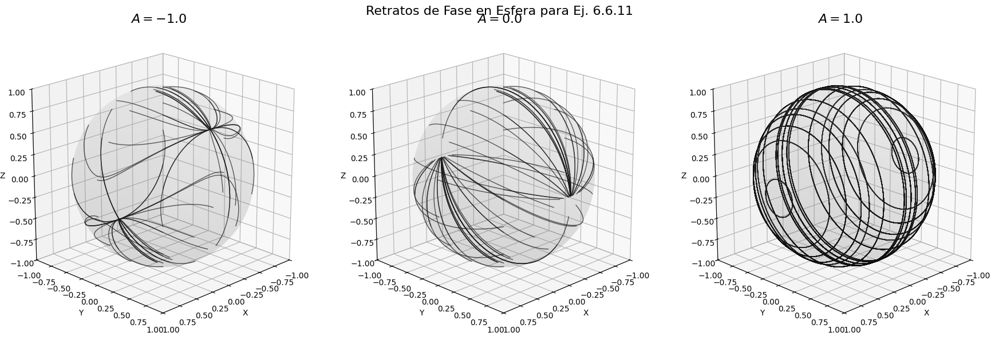

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from mpl_toolkits.mplot3d import Axes3D

# --- 1. Definición del Sistema de EDOs (Ej. 6.6.11) ---
def system_6611(t, X, A):
    """
    Sistema acoplado:
    theta_dot = cot(phi) * cos(theta)
    phi_dot = (cos^2(phi) + A * sin^2(phi)) * sin(theta)
    """
    theta, phi = X

    sin_phi = np.sin(phi)

    # Manejo de singularidades: Si phi está muy cerca de n*pi, cot(phi) diverge.
    # Usamos np.where para evitar el ValueError cuando X es un array.
    condition_singular = np.isclose(sin_phi, 0, atol=1e-3)
    cot_phi = np.where(condition_singular, 0.0, np.cos(phi) / sin_phi)

    theta_dot = cot_phi * np.cos(theta)
    phi_dot = (np.cos(phi)**2 + A * np.sin(phi)**2) * np.sin(theta)

    return [theta_dot, phi_dot]

# --- 2. Parámetros Globales ---
A_VALUES = [-1.0, 0.0, 1.0]
T_SPAN = 30.0 # Tiempo de simulación (más largo para ver el comportamiento)
R = 1.0       # Radio de la esfera

# --- 3. Puntos Iniciales para Trayectorias ---
initial_conditions = []
# Cuadrícula densa para ver el flujo global, evitando polos de phi
num_points = 8
phi_starts = np.linspace(0.1, np.pi - 0.1, num_points) # phi de 0 a pi (polos)
theta_starts = np.linspace(0, 2 * np.pi, num_points, endpoint=False) # theta de 0 a 2pi

for p_start in phi_starts:
    for t_start in theta_starts:
        initial_conditions.append([t_start, p_start])

# También añadimos algunos puntos que crucen las singularidades o puntos fijos
initial_conditions.extend([
    [np.pi/2, np.pi/2], [0, np.pi/2], # Puntos centrales
    [np.pi/2 + 0.1, np.pi/2 + 0.1],
    [np.pi/2 - 0.1, np.pi/2 - 0.1],
    [0.1, 0.1], [0.1, np.pi - 0.1], # Cerca de los polos de phi
    [-0.1, 0.1], [-0.1, np.pi - 0.1]
])

# --- 4. Función para Mapear a Esfera ---
def map_to_sphere(theta, phi, radius=R):
    x = radius * np.sin(phi) * np.cos(theta)
    y = radius * np.sin(phi) * np.sin(theta)
    z = radius * np.cos(phi)
    return x, y, z

# --- 5. Generación de la Figura ---
fig = plt.figure(figsize=(18, 6))
fig.suptitle(r'Retratos de Fase en Esfera para Ej. 6.6.11', fontsize=16)

# Crear una esfera de base
u = np.linspace(0, 2 * np.pi, 50)
v = np.linspace(0, np.pi, 50)
x_sphere = R * np.outer(np.cos(u), np.sin(v))
y_sphere = R * np.outer(np.sin(u), np.sin(v))
z_sphere = R * np.outer(np.ones(np.size(u)), np.cos(v))

for i, A_val in enumerate(A_VALUES):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    ax.set_title(rf'$A = {A_val}$', fontsize=16)

    # Plotear la esfera (gris translúcido)
    ax.plot_surface(x_sphere, y_sphere, z_sphere, color='lightgray', alpha=0.1, linewidth=0)

    # Plotear las trayectorias
    for X0 in initial_conditions:
        sol = solve_ivp(system_6611, [0, T_SPAN], X0, args=(A_val,), rtol=1e-6, atol=1e-6, max_step=0.05)

        # Mapear las trayectorias a la esfera
        x_traj, y_traj, z_traj = map_to_sphere(sol.y[0], sol.y[1])

        ax.plot(x_traj, y_traj, z_traj, color='black', linewidth=1.0, alpha=0.7)

    # Configuración de los ejes
    ax.set_xlim([-R, R])
    ax.set_ylim([-R, R])
    ax.set_zlim([-R, R])
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_box_aspect([1,1,1]) # Asegura una esfera, no un elipsoide
    ax.view_init(elev=20, azim=45) # Ángulo de vista (ajustable)

plt.tight_layout()
plt.show()

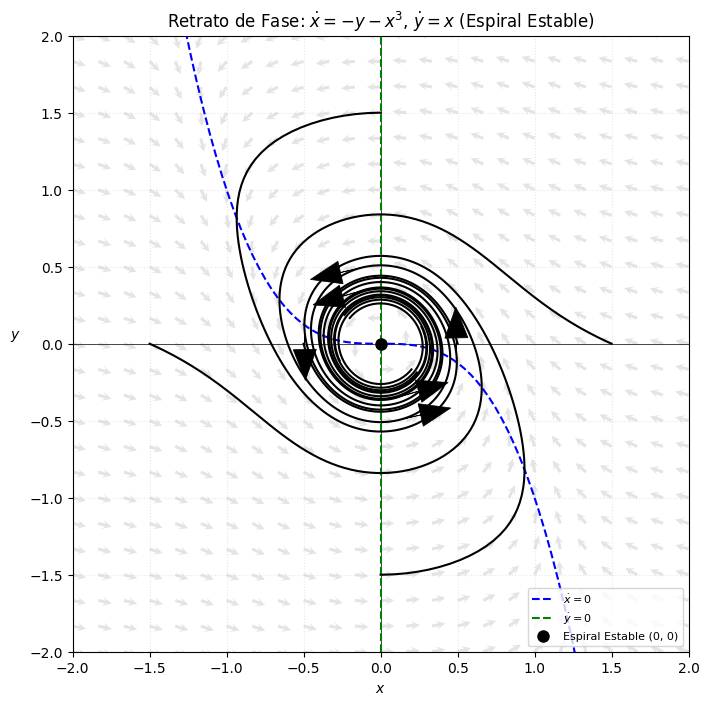

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# 1. Definición del sistema de EDOs
def system_6313(t, X):
    """Sistema: x_dot = -y - x^3, y_dot = x"""
    x, y = X
    x_dot = -y - x**3
    y_dot = x
    return [x_dot, y_dot]

# 2. Parámetros del Plano Fase y Malla
RANGO = 2.0
N_GRID = 25
T_SPAN = 15.0 # Tiempo de simulación para mostrar la espiral

x_vals = np.linspace(-RANGO, RANGO, N_GRID)
y_vals = np.linspace(-RANGO, RANGO, N_GRID)
X, Y = np.meshgrid(x_vals, y_vals)

# Calcular el campo vectorial
U, V = system_6313(0, [X, Y])
M = np.hypot(U, V)
M[M == 0] = 1e-6
U_norm, V_norm = U / M, V / M

# 3. Trayectorias (Espiral Estable)
initial_conditions = [
    [1.5, 0.0], [0.5, 0.0],
    [-1.5, 0.0], [-0.5, 0.0],
    [0.0, 1.5], [0.0, -1.5]
]

# 4. Graficación
plt.figure(figsize=(8, 8))
ax = plt.gca()

# A) Campo Vectorial (Fondo)
ax.quiver(X, Y, U_norm, V_norm,
          color='lightgray',
          alpha=0.6,
          headlength=3, headaxislength=2,
          width=0.005,
          zorder=2)

# B) Nulclinas (Para referencia: x_dot=0 -> y = -x^3; y_dot=0 -> x = 0)
x_null_line = np.linspace(-RANGO, RANGO, 100)
y_null_y_values = -x_null_line**3
ax.plot(x_null_line, y_null_y_values, 'b--', label=r'$\dot{x}=0$', linewidth=1.5, zorder=3)
ax.axvline(0, color='g', linestyle='--', label=r'$\dot{y}=0$', linewidth=1.5, zorder=3) # Corregido

# C) Trayectorias (Demostrando la Espiral Estable)
for X0 in initial_conditions:
    # Simulación hacia adelante
    sol = solve_ivp(system_6313, [0, T_SPAN], X0,
                    rtol=1e-8, atol=1e-8, max_step=0.05)

    ax.plot(sol.y[0], sol.y[1], color='black', linewidth=1.5, zorder=4)

    # Añadir flecha (solo una por trayectoria)
    if len(sol.t) > 10:
        idx = len(sol.t) // 3
        x_start, y_start = sol.y[0][idx], sol.y[1][idx]
        v_mid = system_6313(0, [x_start, y_start])
        mag_arr = np.hypot(v_mid[0], v_mid[1])
        if mag_arr > 1e-4:
            ax.arrow(x_start, y_start, v_mid[0] * 0.15 / mag_arr, v_mid[1] * 0.15 / mag_arr,
                     color='black', head_width=0.15, head_length=0.2, linewidth=0.5, zorder=5)

# D) Punto Fijo
ax.plot(0, 0, 'ko', markerfacecolor='black', markersize=8, label='Espiral Estable (0, 0)', zorder=6)

# E) Configuración Final
ax.set_xlabel('$x$')
ax.set_ylabel('$y$', rotation=0, labelpad=10)
ax.set_title(r'Retrato de Fase: $\dot{x} = -y - x^3$, $\dot{y} = x$ (Espiral Estable)')
ax.set_xlim(-RANGO, RANGO)
ax.set_ylim(-RANGO, RANGO)
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
ax.legend(loc='lower right', fontsize=8)
ax.grid(True, linestyle=':', alpha=0.3)
ax.set_aspect('equal', adjustable='box')

plt.savefig('phase_portrait_6313.png')

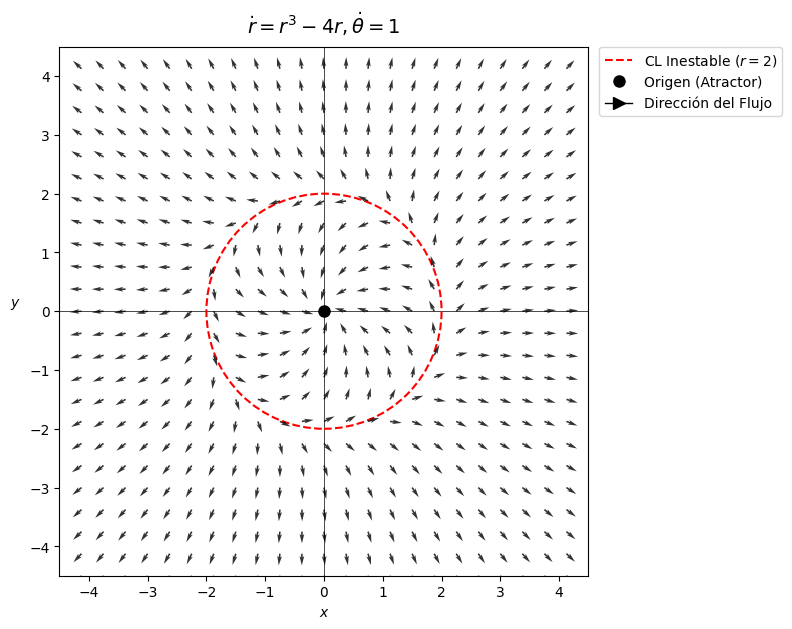

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs (Polar: r, theta) ---
def strogatz_7_1_1(t, Y):
    """
    Sistema: r_dot = r^3 - 4r, theta_dot = 1
    Y = [r, theta]
    """
    r, theta = Y

    if r < 1e-6:
        r_dot = 0
    else:
        r_dot = r**3 - 4*r

    theta_dot = 1

    return [r_dot, theta_dot]

# --- 2. Parámetros para la Graficación ---
X_Y_RANGE_PLOT = 4.5
T_SPAN = 2 * np.pi + 1
N_GRID_QUIVER = 25

# --- 3. Círculos Límite (Analíticamente) ---
LIMIT_CYCLES_R = [0.0, 2.0]

# --- 4. Función de Graficación Principal (Cartesiana, sin trayectorias) ---
def plot_phase_portrait_cartesian_simplified(system_func, title, x_y_range, limit_cycles):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_title(title, fontsize=14, pad=10)

    # A. Círculos Límite
    for r_lc in limit_cycles:
        if r_lc > 0.1:
            linestyle = '--' # r=2 es inestable
            circle = plt.Circle((0, 0), r_lc, color='red', linestyle=linestyle, linewidth=1.5, fill=False, zorder=1)
            ax.add_artist(circle)

    # Punto Fijo en el origen (r=0)
    ax.plot(0, 0, 'ko', markerfacecolor='black', markersize=8, zorder=5, label='Origen (Atractor)')


    # B. Campo Vectorial (en coordenadas cartesianas)
    x_vals = np.linspace(-x_y_range, x_y_range, N_GRID_QUIVER)
    y_vals = np.linspace(-x_y_range, x_y_range, N_GRID_QUIVER)
    X_MESH, Y_MESH = np.meshgrid(x_vals, y_vals)

    R_MESH = np.sqrt(X_MESH**2 + Y_MESH**2)
    THETA_MESH = np.arctan2(Y_MESH, X_MESH)

    r_dot_mesh = np.zeros_like(R_MESH)
    theta_dot_mesh = np.zeros_like(THETA_MESH)

    for i in range(N_GRID_QUIVER):
        for j in range(N_GRID_QUIVER):
            r_val = R_MESH[i, j]
            if r_val < 1e-6:
                r_dot_mesh[i, j] = 0
                theta_dot_mesh[i, j] = 0
            else:
                dr_dt, dtheta_dt = system_func(0, [r_val, THETA_MESH[i, j]])
                r_dot_mesh[i, j] = dr_dt
                theta_dot_mesh[i, j] = dtheta_dt

    mask_zero_r = R_MESH < 1e-6
    R_MESH_SAFE = np.where(mask_zero_r, 1, R_MESH)

    U_MESH = r_dot_mesh * np.cos(THETA_MESH) - R_MESH_SAFE * theta_dot_mesh * np.sin(THETA_MESH)
    V_MESH = r_dot_mesh * np.sin(THETA_MESH) + R_MESH_SAFE * theta_dot_mesh * np.cos(THETA_MESH)

    M = np.hypot(U_MESH, V_MESH)
    M_safe = np.where(M == 0, 1e-6, M)
    U_norm, V_norm = U_MESH / M_safe, V_MESH / M_safe

    ax.quiver(X_MESH, Y_MESH, U_norm, V_norm, color='black', alpha=0.8, # Color negro para las flechas
              headlength=6, headaxislength=5, width=0.003, zorder=2)


    # C. Configuración del Subplot Cartesiano
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$', rotation=0, labelpad=10)
    ax.set_xlim(-x_y_range, x_y_range)
    ax.set_ylim(-x_y_range, x_y_range)
    ax.axvline(0, color='black', linewidth=0.5, zorder=0)
    ax.axhline(0, color='black', linewidth=0.5, zorder=0)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(False)

    # Leyenda (actualizada para reflejar solo lo que se grafica)
    legend_elements = [
        plt.Line2D([0], [0], color='red', linestyle='--', linewidth=1.5, label='CL Inestable ($r=2$)'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markeredgecolor='k', markersize=8, linestyle='', label='Origen (Atractor)'),
        plt.Line2D([0], [0], color='black', linewidth=1.0, marker='>', markersize=8, markevery=[0.5], label='Dirección del Flujo'),
    ]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0.)

    plt.tight_layout()
    plt.show()

# --- 5. Ejecución ---
plot_phase_portrait_cartesian_simplified(
    strogatz_7_1_1,
    r'$\dot{r} = r^3 - 4r, \dot{\theta} = 1$',
    X_Y_RANGE_PLOT,
    LIMIT_CYCLES_R
)

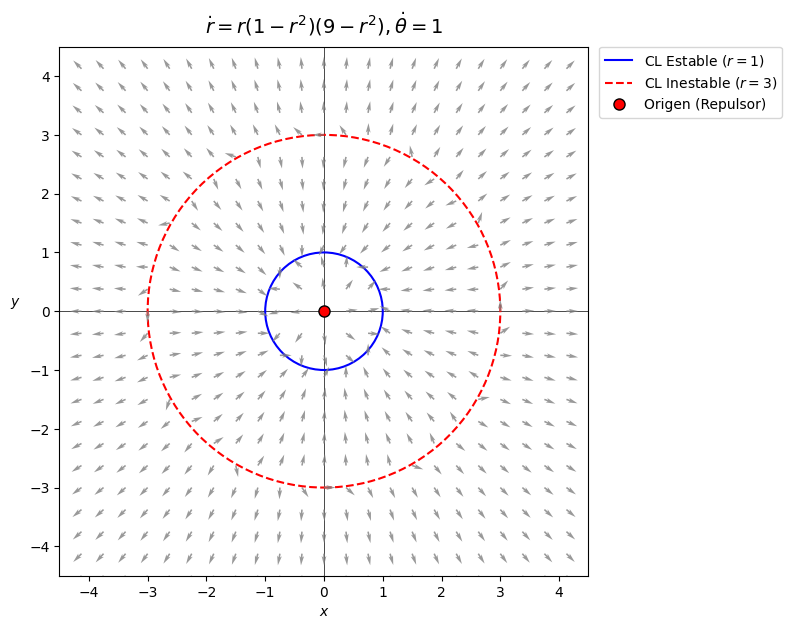

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs (Polar: r, theta) ---
def strogatz_7_1_2(t, Y):
    """
    Sistema: r_dot = r(1-r^2)(9-r^2), theta_dot = 1
    Y = [r, theta]
    """
    r, theta = Y

    # Ecuaciones del sistema 7.1.2
    if r < 1e-6:
        r_dot = 0
    else:
        r_dot = r * (1 - r**2) * (9 - r**2)

    theta_dot = 1

    return [r_dot, theta_dot]

# --- 2. Parámetros para la Graficación ---
X_Y_RANGE_PLOT = 4.5    # Rango para los ejes x e y
T_SPAN = 2 * np.pi + 1   # Tiempo de simulación
N_GRID_QUIVER = 25       # Densidad del campo vectorial

# --- 3. Círculos Límite (Analíticamente) ---
LIMIT_CYCLES_R = [0.0, 1.0, 3.0] # r=0 (origen), r=1 (estable), r=3 (inestable)

# --- 4. Función de Graficación Principal (Cartesiana, con quiver) ---
def plot_phase_portrait_cartesian_simplified(system_func, title, x_y_range, limit_cycles):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_title(title, fontsize=14, pad=10)

    # A. Círculos Límite y Puntos Fijos
    for r_lc in limit_cycles:
        if r_lc > 0.1:
            # r=1 es estable (línea sólida), r=3 es inestable (línea punteada)
            linestyle = '-' if r_lc == 1.0 else '--'
            color = 'blue' if r_lc == 1.0 else 'red' # Usamos color para mejor contraste
            circle = plt.Circle((0, 0), r_lc, color=color, linestyle=linestyle, linewidth=1.5, fill=False, zorder=1)
            ax.add_artist(circle)

    # Origen (r=0): Repulsor/Fuente (markerfacecolor='red')
    ax.plot(0, 0, 'ko', markerfacecolor='red', markersize=8, zorder=5, label='Origen (Repulsor)')


    # B. Campo Vectorial (en coordenadas cartesianas)
    x_vals = np.linspace(-x_y_range, x_y_range, N_GRID_QUIVER)
    y_vals = np.linspace(-x_y_range, x_y_range, N_GRID_QUIVER)
    X_MESH, Y_MESH = np.meshgrid(x_vals, y_vals)

    R_MESH = np.sqrt(X_MESH**2 + Y_MESH**2)
    THETA_MESH = np.arctan2(Y_MESH, X_MESH)

    r_dot_mesh = np.zeros_like(R_MESH)
    theta_dot_mesh = np.zeros_like(THETA_MESH)

    for i in range(N_GRID_QUIVER):
        for j in range(N_GRID_QUIVER):
            r_val = R_MESH[i, j]
            if r_val < 1e-6:
                r_dot_mesh[i, j] = 0
                theta_dot_mesh[i, j] = 0
            else:
                dr_dt, dtheta_dt = system_func(0, [r_val, THETA_MESH[i, j]])
                r_dot_mesh[i, j] = dr_dt
                theta_dot_mesh[i, j] = dtheta_dt

    # Transformación a Cartesiano
    mask_zero_r = R_MESH < 1e-6
    R_MESH_SAFE = np.where(mask_zero_r, 1, R_MESH)

    U_MESH = r_dot_mesh * np.cos(THETA_MESH) - R_MESH_SAFE * theta_dot_mesh * np.sin(THETA_MESH)
    V_MESH = r_dot_mesh * np.sin(THETA_MESH) + R_MESH_SAFE * theta_dot_mesh * np.cos(THETA_MESH)

    # Normalizar y Plotear
    M = np.hypot(U_MESH, V_MESH)
    M_safe = np.where(M == 0, 1e-6, M)
    U_norm, V_norm = U_MESH / M_safe, V_MESH / M_safe

    ax.quiver(X_MESH, Y_MESH, U_norm, V_norm, color='gray', alpha=0.8,
              headlength=6, headaxislength=5, width=0.003, zorder=2)


    # C. Configuración del Subplot Cartesiano
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$', rotation=0, labelpad=10)
    ax.set_xlim(-x_y_range, x_y_range)
    ax.set_ylim(-x_y_range, x_y_range)
    ax.axvline(0, color='black', linewidth=0.5, zorder=0)
    ax.axhline(0, color='black', linewidth=0.5, zorder=0)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(False)

    # Leyenda
    legend_elements = [
        plt.Line2D([0], [0], color='blue', linestyle='-', linewidth=1.5, label='CL Estable ($r=1$)'),
        plt.Line2D([0], [0], color='red', linestyle='--', linewidth=1.5, label='CL Inestable ($r=3$)'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markeredgecolor='k', markersize=8, linestyle='', label='Origen (Repulsor)'),
    ]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0.)

    plt.tight_layout()
    plt.show()

# --- 5. Ejecución ---
plot_phase_portrait_cartesian_simplified(
    strogatz_7_1_2,
    r'$\dot{r} = r(1-r^2)(9-r^2), \dot{\theta} = 1$',
    X_Y_RANGE_PLOT,
    LIMIT_CYCLES_R
)

<>:105: SyntaxWarning: invalid escape sequence '\d'
<>:105: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipython-input-864330901.py:105: SyntaxWarning: invalid escape sequence '\d'
  plt.Line2D([0], [0], color='green', linestyle=':', linewidth=1.0, label='Isoclina $\dot{\\theta}=0$ ($r=\sqrt{2}$)'),


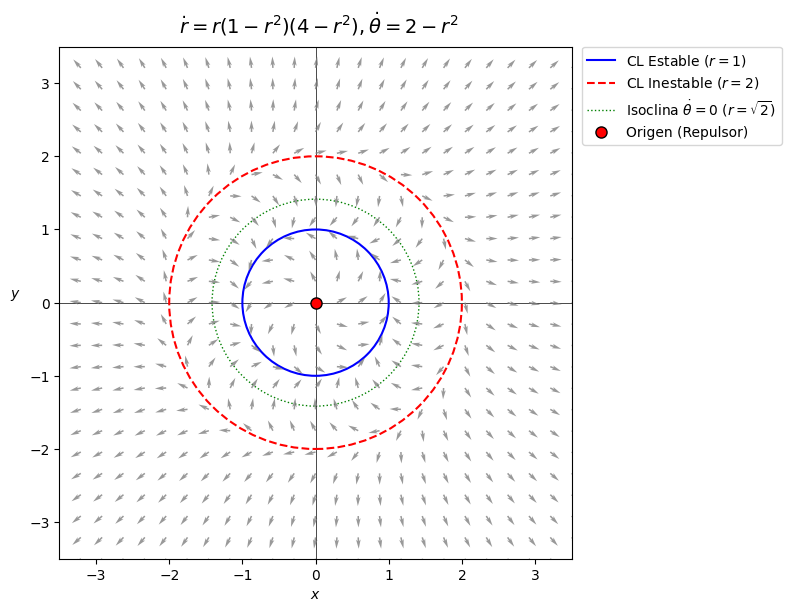

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs (Polar: r, theta) ---
def strogatz_7_1_3(t, Y):
    """
    Sistema: r_dot = r(1-r^2)(4-r^2), theta_dot = 2 - r^2
    Y = [r, theta]
    """
    r, theta = Y

    # Ecuaciones del sistema 7.1.3
    if r < 1e-6:
        r_dot = 0
    else:
        r_dot = r * (1 - r**2) * (4 - r**2)

    theta_dot = 2 - r**2

    return [r_dot, theta_dot]

# --- 2. Parámetros para la Graficación ---
X_Y_RANGE_PLOT = 3.5
N_GRID_QUIVER = 25

# --- 3. Círculos Fijos y Límite (Analíticamente) ---
R_LIMIT_CYCLES = [0.0, 1.0, 2.0] # r=0 (repulsor), r=1 (estable), r=2 (inestable)
R_ZERO_THETA = np.sqrt(2)        # r=sqrt(2) (isoclina theta_dot=0)

# --- 4. Función de Graficación Principal (Cartesiana, con quiver) ---
def plot_phase_portrait_7_1_3(system_func, title, x_y_range, r_limits, r_zero_theta):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_title(title, fontsize=14, pad=10)

    # A. Círculos Límite
    for r_lc in r_limits:
        if r_lc > 0.1:
            # r=1 es estable (azul sólido), r=2 es inestable (rojo punteado)
            linestyle = '-' if r_lc == 1.0 else '--'
            color = 'blue' if r_lc == 1.0 else 'red'
            circle = plt.Circle((0, 0), r_lc, color=color, linestyle=linestyle, linewidth=1.5, fill=False, zorder=1)
            ax.add_artist(circle)

    # Origen (r=0): Repulsor/Fuente (markerfacecolor='red')
    ax.plot(0, 0, 'ko', markerfacecolor='red', markersize=8, zorder=5)

    # Isoclina theta_dot = 0 (línea verde)
    circle_zero_theta = plt.Circle((0, 0), r_zero_theta, color='green', linestyle=':', linewidth=1.0, fill=False, zorder=0)
    ax.add_artist(circle_zero_theta)


    # B. Campo Vectorial (en coordenadas cartesianas)
    x_vals = np.linspace(-x_y_range, x_y_range, N_GRID_QUIVER)
    y_vals = np.linspace(-x_y_range, x_y_range, N_GRID_QUIVER)
    X_MESH, Y_MESH = np.meshgrid(x_vals, y_vals)

    R_MESH = np.sqrt(X_MESH**2 + Y_MESH**2)
    THETA_MESH = np.arctan2(Y_MESH, X_MESH)

    r_dot_mesh = np.zeros_like(R_MESH)
    theta_dot_mesh = np.zeros_like(THETA_MESH)

    for i in range(N_GRID_QUIVER):
        for j in range(N_GRID_QUIVER):
            r_val = R_MESH[i, j]
            if r_val < 1e-6:
                r_dot_mesh[i, j] = 0
                theta_dot_mesh[i, j] = 0
            else:
                dr_dt, dtheta_dt = system_func(0, [r_val, THETA_MESH[i, j]])
                r_dot_mesh[i, j] = dr_dt
                theta_dot_mesh[i, j] = dtheta_dt

    # Transformación a Cartesiano
    mask_zero_r = R_MESH < 1e-6
    R_MESH_SAFE = np.where(mask_zero_r, 1, R_MESH)

    U_MESH = r_dot_mesh * np.cos(THETA_MESH) - R_MESH_SAFE * theta_dot_mesh * np.sin(THETA_MESH)
    V_MESH = r_dot_mesh * np.sin(THETA_MESH) + R_MESH_SAFE * theta_dot_mesh * np.cos(THETA_MESH)

    # Normalizar y Plotear
    M = np.hypot(U_MESH, V_MESH)
    M_safe = np.where(M == 0, 1e-6, M)
    U_norm, V_norm = U_MESH / M_safe, V_MESH / M_safe

    ax.quiver(X_MESH, Y_MESH, U_norm, V_norm, color='gray', alpha=0.8,
              headlength=6, headaxislength=5, width=0.003, zorder=2)


    # C. Configuración del Subplot Cartesiano
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$', rotation=0, labelpad=10)
    ax.set_xlim(-x_y_range, x_y_range)
    ax.set_ylim(-x_y_range, x_y_range)
    ax.axvline(0, color='black', linewidth=0.5, zorder=0)
    ax.axhline(0, color='black', linewidth=0.5, zorder=0)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(False)

    # Leyenda
    legend_elements = [
        plt.Line2D([0], [0], color='blue', linestyle='-', linewidth=1.5, label='CL Estable ($r=1$)'),
        plt.Line2D([0], [0], color='red', linestyle='--', linewidth=1.5, label='CL Inestable ($r=2$)'),
        plt.Line2D([0], [0], color='green', linestyle=':', linewidth=1.0, label='Isoclina $\dot{\\theta}=0$ ($r=\sqrt{2}$)'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markeredgecolor='k', markersize=8, linestyle='', label='Origen (Repulsor)'),
    ]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0.)

    plt.tight_layout()
    plt.show()

# --- 5. Ejecución ---
plot_phase_portrait_7_1_3(
    strogatz_7_1_3,
    r' $\dot{r} = r(1-r^2)(4-r^2), \dot{\theta} = 2 - r^2$',
    X_Y_RANGE_PLOT,
    R_LIMIT_CYCLES,
    R_ZERO_THETA
)

<>:56: SyntaxWarning: invalid escape sequence '\p'
<>:57: SyntaxWarning: invalid escape sequence '\p'
<>:56: SyntaxWarning: invalid escape sequence '\p'
<>:57: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipython-input-4250435288.py:56: SyntaxWarning: invalid escape sequence '\p'
  label_stable = 'CL Estable ($r=n\pi$, $n$ impar)'
/tmp/ipython-input-4250435288.py:57: SyntaxWarning: invalid escape sequence '\p'
  label_unstable = 'CL Inestable ($r=n\pi$, $n$ par)'


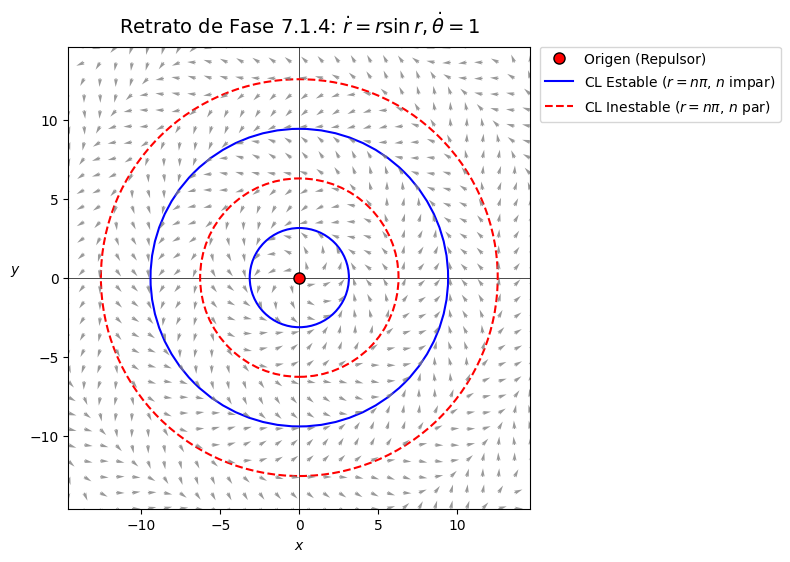

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- 1. Definición del Sistema de EDOs (Polar: r, theta) ---
def strogatz_7_1_4(t, Y):
    """
    Sistema: r_dot = r sin(r), theta_dot = 1
    Y = [r, theta]
    """
    r, theta = Y

    # Ecuaciones del sistema 7.1.4
    if r < 1e-6:
        r_dot = 0
    else:
        r_dot = r * np.sin(r)

    theta_dot = 1

    return [r_dot, theta_dot]

# --- 2. Parámetros para la Graficación ---
R_MAX = 4.5 * np.pi # Para incluir hasta el círculo r=4pi
X_Y_RANGE_PLOT = R_MAX + 0.5
N_GRID_QUIVER = 30

# --- 3. Círculos Fijos y Límite (Analíticamente) ---
# Incluimos los primeros 4 círculos límite (r=pi, 2pi, 3pi, 4pi)
R_LIMIT_CYCLES = [0.0, np.pi, 2*np.pi, 3*np.pi, 4*np.pi]

# --- 4. Función de Graficación Principal (Cartesiana, con quiver) ---
def plot_phase_portrait_7_1_4(system_func, title, x_y_range, r_limits):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_title(title, fontsize=14, pad=10)

    legend_elements = []

    # A. Círculos Límite y Puntos Fijos
    # Origen (r=0): Repulsor (markerfacecolor='red')
    ax.plot(0, 0, 'ko', markerfacecolor='red', markersize=8, zorder=5)
    legend_elements.append(plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markeredgecolor='k', markersize=8, linestyle='', label='Origen (Repulsor)'))

    for r_lc in r_limits:
        if r_lc > 0.1:
            n = round(r_lc / np.pi) # Determinar n

            # Estabilidad alterna: n impar (Estable), n par (Inestable)
            linestyle = '-' if n % 2 != 0 else '--'
            color = 'blue' if n % 2 != 0 else 'red'

            circle = plt.Circle((0, 0), r_lc, color=color, linestyle=linestyle, linewidth=1.5, fill=False, zorder=1)
            ax.add_artist(circle)

            # Añadir a la leyenda solo una vez para cada tipo
            label_stable = 'CL Estable ($r=n\pi$, $n$ impar)'
            label_unstable = 'CL Inestable ($r=n\pi$, $n$ par)'
            if n % 2 != 0 and label_stable not in [l.get_label() for l in legend_elements]:
                 legend_elements.append(plt.Line2D([0], [0], color='blue', linestyle='-', linewidth=1.5, label=label_stable))
            elif n % 2 == 0 and label_unstable not in [l.get_label() for l in legend_elements]:
                 legend_elements.append(plt.Line2D([0], [0], color='red', linestyle='--', linewidth=1.5, label=label_unstable))

    # B. Campo Vectorial (en coordenadas cartesianas)
    x_vals = np.linspace(-x_y_range, x_y_range, N_GRID_QUIVER)
    y_vals = np.linspace(-x_y_range, x_y_range, N_GRID_QUIVER)
    X_MESH, Y_MESH = np.meshgrid(x_vals, y_vals)

    R_MESH = np.sqrt(X_MESH**2 + Y_MESH**2)
    THETA_MESH = np.arctan2(Y_MESH, X_MESH)

    r_dot_mesh = np.zeros_like(R_MESH)
    theta_dot_mesh = np.zeros_like(THETA_MESH)

    # Calcular derivadas polares
    for i in range(N_GRID_QUIVER):
        for j in range(N_GRID_QUIVER):
            r_val = R_MESH[i, j]
            if r_val < 1e-6:
                r_dot_mesh[i, j] = 0
                theta_dot_mesh[i, j] = 0
            else:
                dr_dt, dtheta_dt = system_func(0, [r_val, THETA_MESH[i, j]])
                r_dot_mesh[i, j] = dr_dt
                theta_dot_mesh[i, j] = dtheta_dt

    # Transformación a Cartesiano
    mask_zero_r = R_MESH < 1e-6
    R_MESH_SAFE = np.where(mask_zero_r, 1, R_MESH)

    U_MESH = r_dot_mesh * np.cos(THETA_MESH) - R_MESH_SAFE * theta_dot_mesh * np.sin(THETA_MESH)
    V_MESH = r_dot_mesh * np.sin(THETA_MESH) + R_MESH_SAFE * theta_dot_mesh * np.cos(THETA_MESH)

    # Normalizar y Plotear
    M = np.hypot(U_MESH, V_MESH)
    M_safe = np.where(M == 0, 1e-6, M)
    U_norm, V_norm = U_MESH / M_safe, V_MESH / M_safe

    ax.quiver(X_MESH, Y_MESH, U_norm, V_norm, color='gray', alpha=0.8,
              headlength=6, headaxislength=5, width=0.003, zorder=2)


    # C. Configuración del Subplot Cartesiano
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$', rotation=0, labelpad=10)
    ax.set_xlim(-x_y_range, x_y_range)
    ax.set_ylim(-x_y_range, x_y_range)
    ax.axvline(0, color='black', linewidth=0.5, zorder=0)
    ax.axhline(0, color='black', linewidth=0.5, zorder=0)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(False)

    # Leyenda
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0.)

    plt.tight_layout()
    plt.show()

# --- 5. Ejecución ---
plot_phase_portrait_7_1_4(
    strogatz_7_1_4,
    r'Retrato de Fase 7.1.4: $\dot{r} = r \sin r, \dot{\theta} = 1$',
    X_Y_RANGE_PLOT,
    R_LIMIT_CYCLES
)

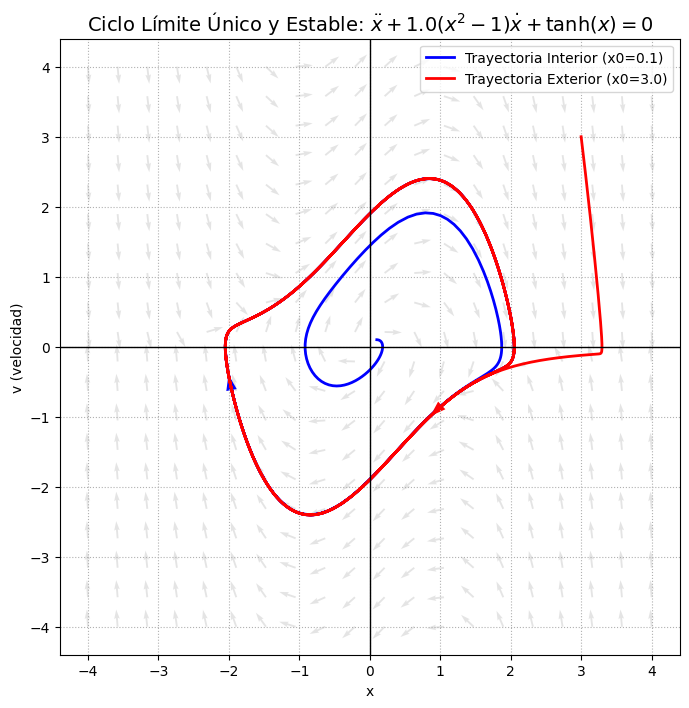

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Configuración del Sistema ---
MU = 1.0  # Puedes cambiar este valor (> 0)

def lienard_system(t, Y):
    """
    Sistema: x'' + mu(x^2 - 1)x' + tanh(x) = 0
    Convertido a primer orden:
    x' = v
    v' = -mu * (x**2 - 1) * v - np.tanh(x)
    """
    x, v = Y
    dxdt = v
    dvdt = -MU * (x**2 - 1) * v - np.tanh(x)
    return [dxdt, dvdt]

# --- Configuración de la Gráfica ---
x_range = 4.0
v_range = 4.0
t_span = [0, 40] # Tiempo suficiente para converger

# Condiciones iniciales: Una dentro y una fuera del ciclo probable
initial_conditions = [
    [0.1, 0.1],   # Desde cerca del origen (debería espiralar hacia afuera)
    [3.0, 3.0]    # Desde lejos (debería espiralar hacia adentro)
]

fig, ax = plt.subplots(figsize=(8, 8))

# 1. Graficar Campo Vectorial
x_vals = np.linspace(-x_range, x_range, 20)
v_vals = np.linspace(-v_range, v_range, 20)
X, V = np.meshgrid(x_vals, v_vals)
DX, DV = lienard_system(0, [X, V])
M = np.hypot(DX, DV)
M[M == 0] = 1e-6
ax.quiver(X, V, DX/M, DV/M, color='lightgray', alpha=0.6)

# 2. Graficar Trayectorias
colors = ['blue', 'red']
labels = ['Trayectoria Interior (x0=0.1)', 'Trayectoria Exterior (x0=3.0)']

for i, y0 in enumerate(initial_conditions):
    sol = solve_ivp(lienard_system, t_span, y0, rtol=1e-8, atol=1e-8, max_step=0.1)
    ax.plot(sol.y[0], sol.y[1], color=colors[i], linewidth=2, label=labels[i])

    # Flechas de dirección
    idx_mid = len(sol.t) // 2
    ax.arrow(sol.y[0][idx_mid], sol.y[1][idx_mid],
             sol.y[0][idx_mid+1]-sol.y[0][idx_mid], sol.y[1][idx_mid+1]-sol.y[1][idx_mid],
             shape='full', lw=0, length_includes_head=True, head_width=0.15, color=colors[i])

# 3. Detalles Estéticos
ax.set_title(rf'Ciclo Límite Único y Estable: $\ddot{{x}} + {MU}(x^2 - 1)\dot{{x}} + \tanh(x) = 0$', fontsize=14)
ax.set_xlabel('x')
ax.set_ylabel('v (velocidad)')
ax.axhline(0, color='black', lw=1)
ax.axvline(0, color='black', lw=1)
ax.legend()
ax.grid(True, linestyle=':')

plt.show()

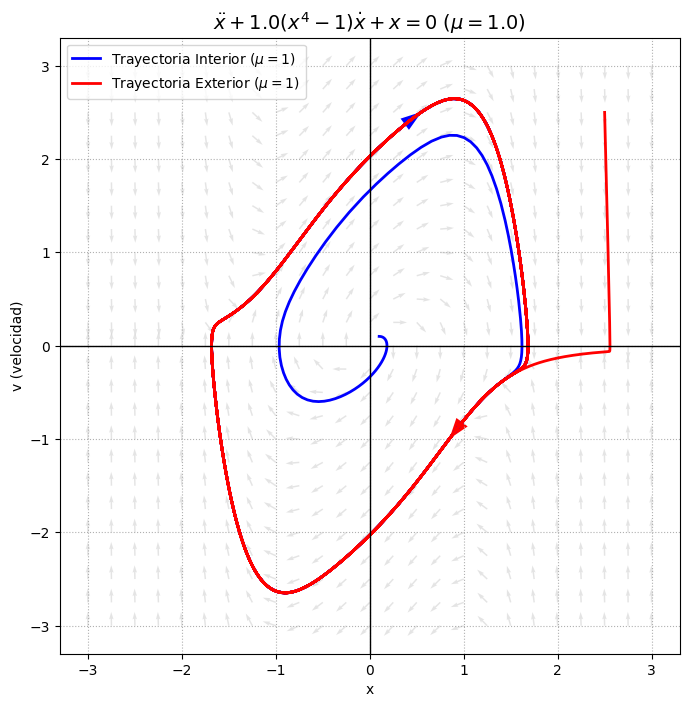

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Configuración del Sistema ---
MU_B = 1.0  # Para el apartado b)

def lienard_system_7_4_2(t, Y):
    """
    Sistema: x'' + mu(x^4 - 1)x' + x = 0
    Convertido a primer orden:
    x' = v
    v' = -mu * (x**4 - 1) * v - x
    """
    x, v = Y
    dxdt = v
    dvdt = -MU_B * (x**4 - 1) * v - x
    return [dxdt, dvdt]

# --- Configuración de la Gráfica ---
x_range_b = 3.0
v_range_b = 3.0
t_span_b = [0, 50] # Suficiente tiempo para converger al ciclo límite

# Condiciones iniciales: Una dentro y una fuera del ciclo probable
initial_conditions_b = [
    [0.1, 0.1],   # Desde cerca del origen (debería espiralar hacia afuera)
    [2.5, 2.5]    # Desde lejos (debería espiralar hacia adentro)
]

fig_b, ax_b = plt.subplots(figsize=(8, 8))

# 1. Graficar Campo Vectorial
x_vals_b = np.linspace(-x_range_b, x_range_b, 25)
v_vals_b = np.linspace(-v_range_b, v_range_b, 25)
X_b, V_b = np.meshgrid(x_vals_b, v_vals_b)
DX_b, DV_b = lienard_system_7_4_2(0, [X_b, V_b])
M_b = np.hypot(DX_b, DV_b)
M_b[M_b == 0] = 1e-6
ax_b.quiver(X_b, V_b, DX_b/M_b, DV_b/M_b, color='lightgray', alpha=0.6)

# 2. Graficar Trayectorias
colors_b = ['blue', 'red']
labels_b = [r'Trayectoria Interior ($\mu=1$)', r'Trayectoria Exterior ($\mu=1$)']

for i, y0 in enumerate(initial_conditions_b):
    sol_b = solve_ivp(lienard_system_7_4_2, t_span_b, y0, rtol=1e-8, atol=1e-8, max_step=0.1)
    ax_b.plot(sol_b.y[0], sol_b.y[1], color=colors_b[i], linewidth=2, label=labels_b[i])

    # Flechas de dirección
    idx_mid_b = len(sol_b.t) // 2
    if idx_mid_b > 0 and idx_mid_b < len(sol_b.t)-1:
        ax_b.arrow(sol_b.y[0][idx_mid_b], sol_b.y[1][idx_mid_b],
                   sol_b.y[0][idx_mid_b+1]-sol_b.y[0][idx_mid_b], sol_b.y[1][idx_mid_b+1]-sol_b.y[1][idx_mid_b],
                   shape='full', lw=0, length_includes_head=True, head_width=0.15, color=colors_b[i])

# 3. Detalles Estéticos
ax_b.set_title(rf'$\ddot{{x}} + {MU_B}(x^4 - 1)\dot{{x}} + x = 0$ ($\mu={MU_B}$)', fontsize=14)
ax_b.set_xlabel('x')
ax_b.set_ylabel('v (velocidad)')
ax_b.axhline(0, color='black', lw=1)
ax_b.axvline(0, color='black', lw=1)
ax_b.legend()
ax_b.grid(True, linestyle=':')

plt.show()

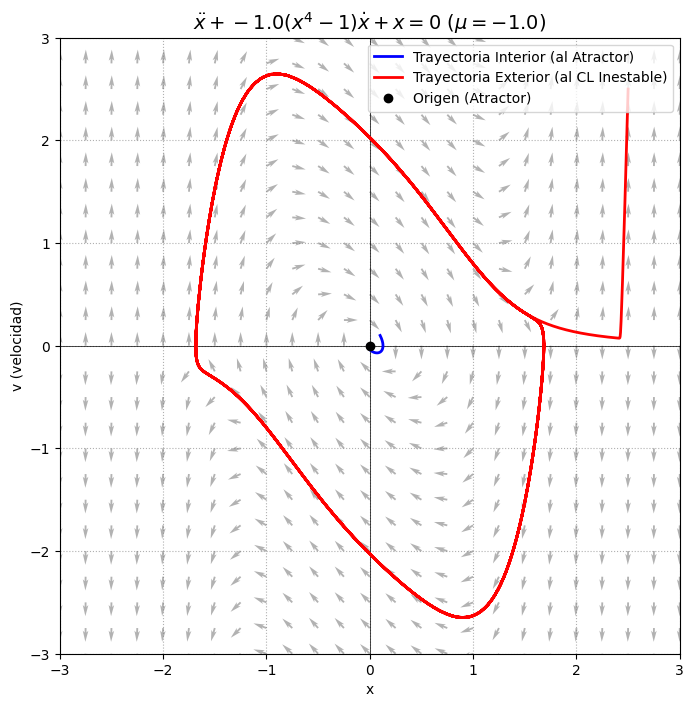

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Configuración del Sistema (mu = -1.0) ---
MU_C = -1.0

def lienard_system_7_4_2_c(t, Y):
    """
    Sistema: x'' + mu(x^4 - 1)x' + x = 0
    x' = v
    v' = -mu * (x**4 - 1) * v - x
    """
    x, v = Y
    dxdt = v
    dvdt = -MU_C * (x**4 - 1) * v - x
    return [dxdt, dvdt]

# --- Configuración de la Gráfica ---
x_range_c = 3.0
v_range_c = 3.0
N_GRID_QUIVER = 25       # Densidad del campo vectorial

# Tiempos de simulación:
T_SPAN_FWD_IN = 30     # Tiempo largo para la trayectoria interior (debe llegar al origen)
T_SPAN_BWD_OUT = [0, -50] # ¡Tiempo hacia atrás para forzar la convergencia al CL inestable!

# Condiciones iniciales
initial_conditions_c = [
    [0.1, 0.1],   # Interior: Converge al origen (Fwd)
    [2.5, 2.5]    # Exterior: Diverge al infinito (Bwd para forzar la convergencia)
]

fig_c, ax_c = plt.subplots(figsize=(8, 8))

# 1. Graficar Campo Vectorial (Quiver Plot)
x_vals_c = np.linspace(-x_range_c, x_range_c, N_GRID_QUIVER)
v_vals_c = np.linspace(-v_range_c, v_range_c, N_GRID_QUIVER)
X_c, V_c = np.meshgrid(x_vals_c, v_vals_c)
DX_c, DV_c = lienard_system_7_4_2_c(0, [X_c, V_c])
M_c = np.hypot(DX_c, DV_c)
M_c[M_c == 0] = 1e-6
# Plotear las flechas grises
ax_c.quiver(X_c, V_c, DX_c/M_c, DV_c/M_c, color='gray', alpha=0.6,
            headlength=6, headaxislength=5, width=0.003, zorder=2)


# 2. Graficar Trayectorias
colors_c = ['blue', 'red']
labels_c = [r'Trayectoria Interior (al Atractor)', r'Trayectoria Exterior (al CL Inestable)']

# Trayectoria Interior (Adelante en el tiempo -> Atractor Origen)
sol_in = solve_ivp(lienard_system_7_4_2_c, [0, T_SPAN_FWD_IN], initial_conditions_c[0], rtol=1e-8, atol=1e-8)
ax_c.plot(sol_in.y[0], sol_in.y[1], color=colors_c[0], linewidth=2, label=labels_c[0], zorder=3)

# Trayectoria Exterior (¡Atrás en el tiempo! -> Repulsor CL Inestable)
sol_out = solve_ivp(lienard_system_7_4_2_c, T_SPAN_BWD_OUT, initial_conditions_c[1], rtol=1e-8, atol=1e-8)
# Plotear la trayectoria roja
ax_c.plot(sol_out.y[0], sol_out.y[1], color=colors_c[1], linewidth=2, label=labels_c[1], zorder=3)

# Marcar el origen (Atractor estable)
ax_c.plot(0, 0, 'ko', markerfacecolor='black', markersize=6, zorder=4, label='Origen (Atractor)')

# 3. Detalles Estéticos
ax_c.set_title(rf'$\ddot{{x}} + {MU_C}(x^4 - 1)\dot{{x}} + x = 0$ ($\mu=-1.0$)', fontsize=14)
ax_c.set_xlabel('x')
ax_c.set_ylabel('v (velocidad)')
ax_c.set_xlim(-x_range_c, x_range_c)
ax_c.set_ylim(-v_range_c, v_range_c)
ax_c.axhline(0, color='black', lw=0.5)
ax_c.axvline(0, color='black', lw=0.5)
ax_c.legend(loc='upper right')
ax_c.grid(True, linestyle=':')

plt.show()

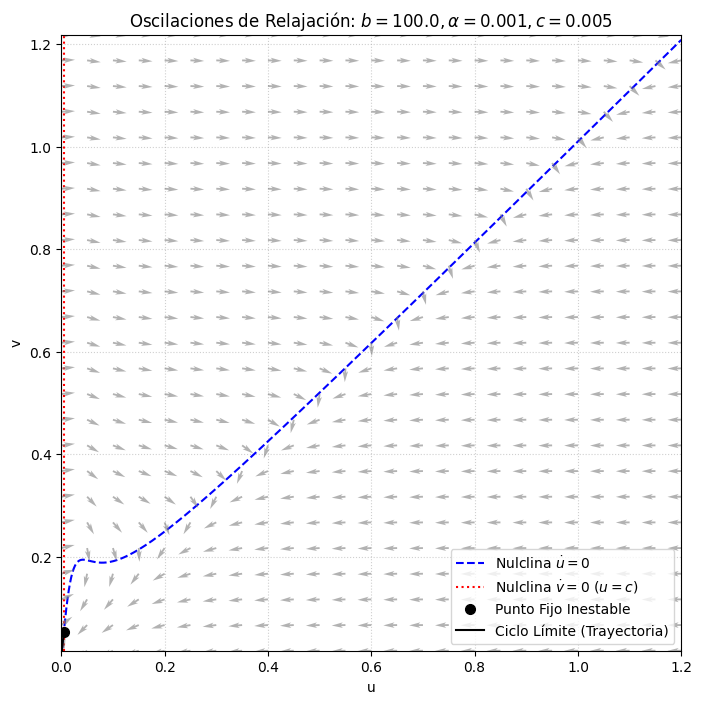

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Parámetros del Modelo de Tyson ---
B = 100.0
ALPHA = 0.001
C_RELAX = 0.005
N_GRID_QUIVER = 25       # Densidad del campo vectorial

# --- Definición del Sistema (EDOs) ---
def tyson_system(t, Y, b, alpha, c):
    u, v = Y
    u_dot = b * (v - u) * (alpha + u**2) - u
    v_dot = c - u
    return [u_dot, v_dot]

# --- Puntos Fijos y Nulclinas ---
def nulclina_u_dot_zero(u, b, alpha):
    """v(u) para u_dot = 0"""
    u_safe = np.where(np.abs(u) < 1e-6, 1e-6, u)
    return u * (1 / (b * (alpha + u_safe**2)) + 1)

# --- Simulación del Ciclo Límite ---
t_span_b = [0, 200]
Y0_b = [0.01, 0.01]
sol_b = solve_ivp(tyson_system, t_span_b, Y0_b, args=(B, ALPHA, C_RELAX),
                  rtol=1e-6, atol=1e-6, max_step=0.1)

# --- Gráfico de Relajación ---
fig_b, ax_b = plt.subplots(figsize=(8, 8))

# 1. Nulclinas
u_vals_b = np.linspace(0, 1.2, 500)
v_nul_u_b = nulclina_u_dot_zero(u_vals_b, B, ALPHA)

# Calcular los límites Y para un enfoque óptimo
v_min_plot = np.min(v_nul_u_b[u_vals_b > 0.001]) - 0.01
v_max_plot = np.max(v_nul_u_b) + 0.01

# Graficar nulclina u_dot=0
ax_b.plot(u_vals_b, v_nul_u_b, 'b--', label=r'Nulclina $\dot{u}=0$')

# Graficar nulclina v_dot=0
v_nul_v_b = np.linspace(v_min_plot, v_max_plot, 100)
ax_b.plot(np.full_like(v_nul_v_b, C_RELAX), v_nul_v_b, 'r:', label=r'Nulclina $\dot{v}=0$ ($u=c$)')

# Punto Fijo
v_star_b = nulclina_u_dot_zero(C_RELAX, B, ALPHA)
ax_b.plot(C_RELAX, v_star_b, 'ko', markersize=7, label='Punto Fijo Inestable')


# 2. Campo Vectorial (¡Las flechitas grises!)
u_vals_quiver = np.linspace(0, 1.2, N_GRID_QUIVER)
v_vals_quiver = np.linspace(v_min_plot, v_max_plot, N_GRID_QUIVER)
U_MESH, V_MESH = np.meshgrid(u_vals_quiver, v_vals_quiver)

DU, DV = tyson_system(0, [U_MESH, V_MESH], B, ALPHA, C_RELAX)
M = np.hypot(DU, DV)
M[M == 0] = 1e-6

# Normalizar y plotear el campo vectorial
ax_b.quiver(U_MESH, V_MESH, DU/M, DV/M, color='gray', alpha=0.6,
            headlength=6, headaxislength=5, width=0.003, zorder=2)


# 3. Trayectoria (Ciclo Límite)
ax_b.plot(sol_b.y[0], sol_b.y[1], 'k-', linewidth=1.5, label='Ciclo Límite (Trayectoria)', zorder=3)


# 4. Detalles Estéticos y Ajuste de Escala
ax_b.set_title(rf'Oscilaciones de Relajación: $b={B}, \alpha={ALPHA}, c={C_RELAX}$')
ax_b.set_xlabel('u')
ax_b.set_ylabel('v')

# Ajustamos límites Y al rango calculado
ax_b.set_xlim(0, 1.2)
ax_b.set_ylim(v_min_plot, v_max_plot)

ax_b.legend(loc='lower right')
ax_b.grid(True, linestyle=':', alpha=0.6)

plt.show()

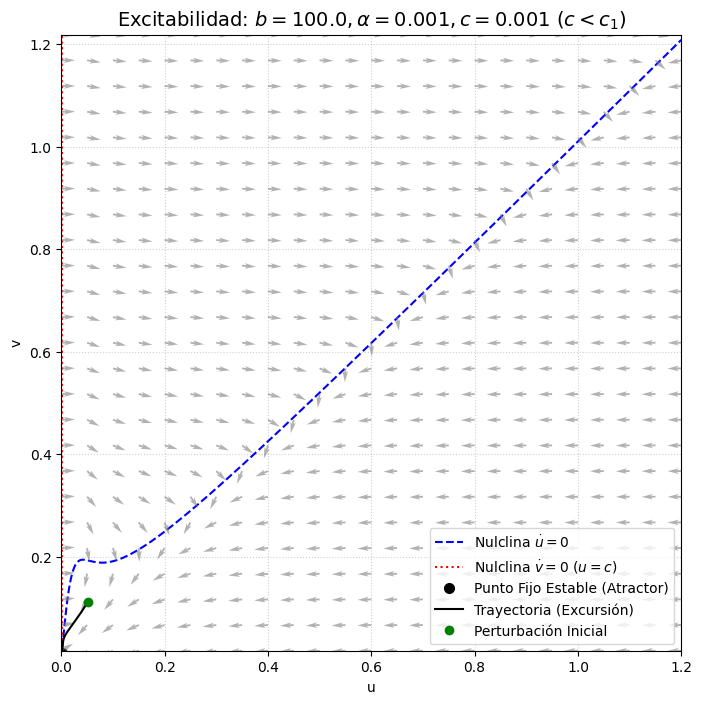

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Parámetros del Modelo de Tyson ---
B = 100.0
ALPHA = 0.001
N_GRID_QUIVER = 25       # Densidad del campo vectorial

# --- Definición del Sistema (EDOs) ---
def tyson_system(t, Y, b, alpha, c):
    u, v = Y
    u_dot = b * (v - u) * (alpha + u**2) - u
    v_dot = c - u
    return [u_dot, v_dot]

# --- Puntos Fijos y Nulclinas ---
def nulclina_u_dot_zero(u, b, alpha):
    """v(u) para u_dot = 0"""
    u_safe = np.where(np.abs(u) < 1e-6, 1e-6, u)
    return u * (1 / (b * (alpha + u_safe**2)) + 1)

# --- Parámetros para Excitabilidad (c) ---
C_EXCITE = 0.001 # Valor en la rama estable inferior (c < c1 ~ 0.002)

# --- Simulación ---
t_span_c = [0, 400] # Suficiente tiempo para que la excursión regrese al PF
# Condición de Perturbación: La perturbamos fuera de la cuenca inmediata del PF
Y0_c_pert = [C_EXCITE + 0.05,  # Perturbación en u
             nulclina_u_dot_zero(C_EXCITE, B, ALPHA) + 0.1] # Perturbación en v

sol_c = solve_ivp(tyson_system, t_span_c, Y0_c_pert, args=(B, ALPHA, C_EXCITE),
                  rtol=1e-6, atol=1e-6, max_step=0.1)

# --- Gráfico de Excitabilidad ---
fig_c, ax_c = plt.subplots(figsize=(8, 8))

# 1. Nulclinas
u_vals_c = np.linspace(0, 1.2, 500)
v_nul_u_c = nulclina_u_dot_zero(u_vals_c, B, ALPHA)

# Calcular los límites Y para un enfoque óptimo
v_min_plot_c = np.min(v_nul_u_c[u_vals_c > 0.001]) - 0.01
v_max_plot_c = np.max(v_nul_u_c) + 0.01

# Graficar nulclina u_dot=0
ax_c.plot(u_vals_c, v_nul_u_c, 'b--', label=r'Nulclina $\dot{u}=0$')

# Graficar nulclina v_dot=0
v_nul_v_c = np.linspace(v_min_plot_c, v_max_plot_c, 100)
ax_c.plot(np.full_like(v_nul_v_c, C_EXCITE), v_nul_v_c, 'r:', label=r'Nulclina $\dot{v}=0$ ($u=c$)')

# Punto Fijo (intersección en la rama estable)
v_star_c = nulclina_u_dot_zero(C_EXCITE, B, ALPHA)
ax_c.plot(C_EXCITE, v_star_c, 'ko', markerfacecolor='black', markersize=7, label='Punto Fijo Estable (Atractor)')


# 2. Campo Vectorial (¡Las flechitas grises!)
u_vals_quiver_c = np.linspace(0, 1.2, N_GRID_QUIVER)
v_vals_quiver_c = np.linspace(v_min_plot_c, v_max_plot_c, N_GRID_QUIVER)
U_MESH_c, V_MESH_c = np.meshgrid(u_vals_quiver_c, v_vals_quiver_c)

DU_c, DV_c = tyson_system(0, [U_MESH_c, V_MESH_c], B, ALPHA, C_EXCITE)
M_c = np.hypot(DU_c, DV_c)
M_c[M_c == 0] = 1e-6

# Normalizar y plotear el campo vectorial
ax_c.quiver(U_MESH_c, V_MESH_c, DU_c/M_c, DV_c/M_c, color='gray', alpha=0.6,
            headlength=6, headaxislength=5, width=0.003, zorder=2)


# 3. Trayectoria (Excitabilidad)
ax_c.plot(sol_c.y[0], sol_c.y[1], 'k-', linewidth=1.5, label='Trayectoria (Excursión)', zorder=3)
ax_c.plot(Y0_c_pert[0], Y0_c_pert[1], 'go', markersize=6, label='Perturbación Inicial', zorder=4)


# 4. Detalles Estéticos y Ajuste de Escala
ax_c.set_title(rf'Excitabilidad: $b={B}, \alpha={ALPHA}, c={C_EXCITE}$ ($c < c_1$)', fontsize=14)
ax_c.set_xlabel('u')
ax_c.set_ylabel('v')

# Ajustamos límites Y al rango calculado
ax_c.set_xlim(0, 1.2)
ax_c.set_ylim(v_min_plot_c, v_max_plot_c)

ax_c.legend(loc='lower right')
ax_c.grid(True, linestyle=':', alpha=0.6)

plt.show()

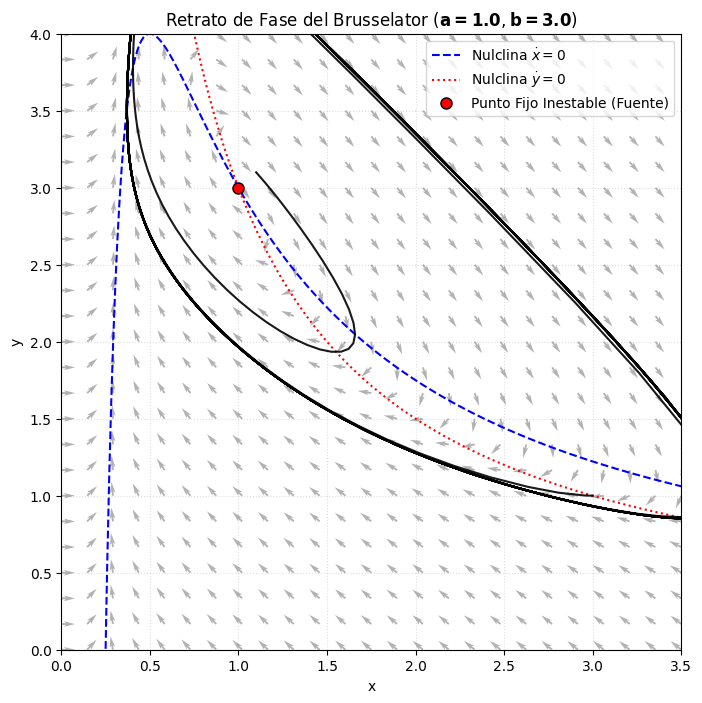

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Parámetros para la Simulación (b > bc = 2) ---
A = 1.0  # Parámetro a (constante)
B = 3.0  # Parámetro b (b > bc = 2, asegurando un ciclo límite)

# --- Definición del Sistema (EDOs) ---
def brusselator_system(t, Y, a, b):
    x, y = Y

    # Ecuaciones del Brusselator
    x_dot = 1 - (b + 1) * x + a * x**2 * y
    y_dot = b * x - a * x**2 * y

    return [x_dot, y_dot]

# --- Configuración de la Simulación ---
t_span = [0, 50]  # Tiempo suficiente para converger al ciclo
N_GRID = 25       # Densidad del campo vectorial

# Punto fijo (Fuente inestable)
X_STAR, Y_STAR = 1.0, B / A

# Condiciones iniciales: una dentro y una fuera del ciclo esperado
initial_conditions = [
    [X_STAR + 0.1, Y_STAR + 0.1],  # Cerca del punto fijo (espiralará hacia afuera)
    [3.0, 1.0]                     # Lejos (espiralará hacia adentro)
]

# --- Graficación ---
fig, ax = plt.subplots(figsize=(8, 8))

# 1. Campo Vectorial (Flujo)
x_vals = np.linspace(0, 3.5, N_GRID)
y_vals = np.linspace(0, 4.0, N_GRID)
X, Y = np.meshgrid(x_vals, y_vals)
DX, DY = brusselator_system(0, [X, Y], A, B)
M = np.hypot(DX, DY)
M[M == 0] = 1e-6

# Plotear las flechas grises
ax.quiver(X, Y, DX/M, DY/M, color='gray', alpha=0.6,
          headlength=6, headaxislength=5, width=0.003, zorder=2)

# 2. Nulclinas (Para contexto)
x_nul_x = np.linspace(0.1, 3.5, 300) # Evitar x=0
y_nul_x = ((B + 1) * x_nul_x - 1) / (A * x_nul_x**2) # Nulclina x_dot=0
y_nul_y = B / (A * x_nul_x)                         # Nulclina y_dot=0

ax.plot(x_nul_x, y_nul_x, 'b--', label=r'Nulclina $\dot{x}=0$')
ax.plot(x_nul_x, y_nul_y, 'r:', label=r'Nulclina $\dot{y}=0$')


# 3. Trayectorias y Punto Fijo
ax.plot(X_STAR, Y_STAR, 'ko', markerfacecolor='red', markersize=8, label='Punto Fijo Inestable (Fuente)')

for Y0 in initial_conditions:
    sol = solve_ivp(brusselator_system, t_span, Y0, args=(A, B),
                    rtol=1e-6, atol=1e-6, max_step=0.1)
    ax.plot(sol.y[0], sol.y[1], 'k-', linewidth=1.5, alpha=0.9)


# 4. Detalles Estéticos
ax.set_title(rf'Retrato de Fase del Brusselator ($\mathbf{{a={A}}}, \mathbf{{b={B}}}$)')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_xlim(0, 3.5)
ax.set_ylim(0, 4.0)
ax.legend(loc='upper right')
ax.grid(True, linestyle=':', alpha=0.4)
plt.show()

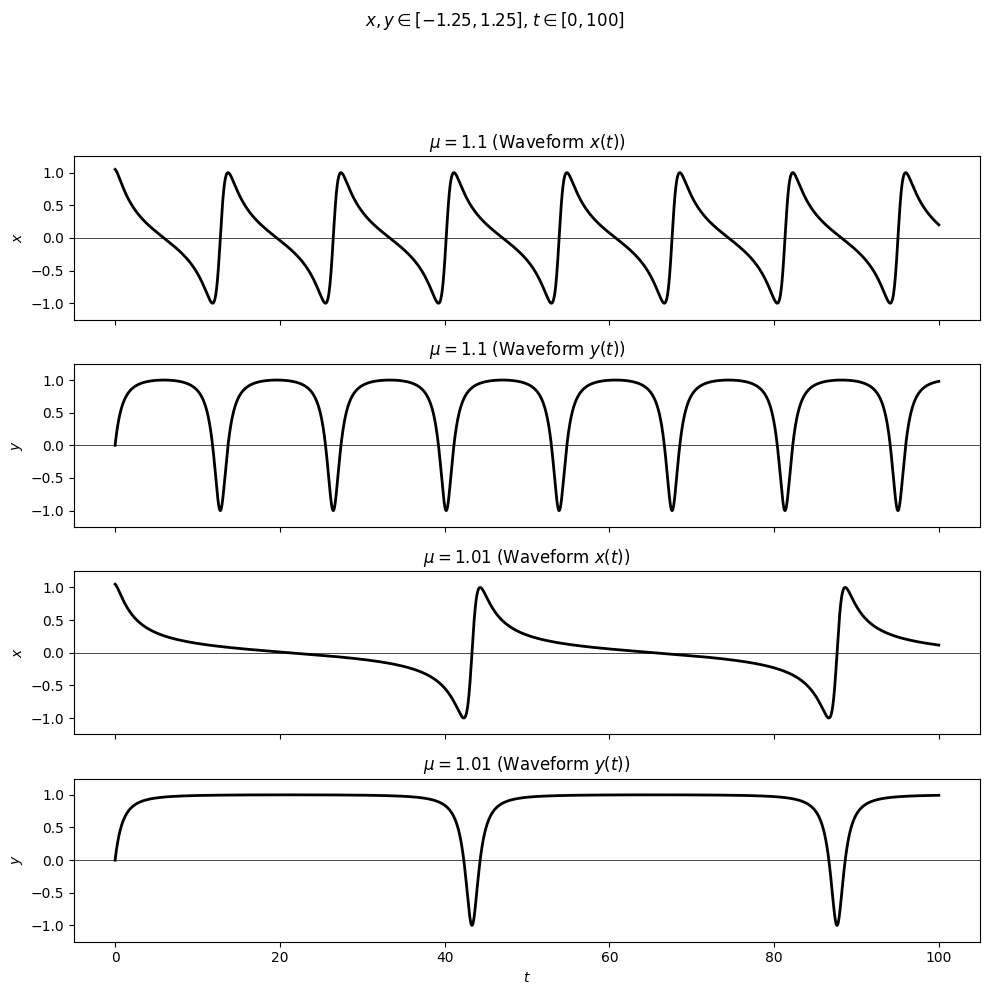

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Definición del Sistema de EDOs (Polares) ---
def polar_system(t, Y, mu):
    """
    Sistema: r_dot = r(1-r^2), theta_dot = mu - sin(theta)
    Y = [r, theta]
    """
    r, theta = Y

    # Ecuación radial (r_dot = 0 en el ciclo limite r=1)
    r_dot = r * (1 - r**2)

    # Ecuación angular (rotación lenta cerca de theta = pi/2)
    theta_dot = mu - np.sin(theta)

    return [r_dot, theta_dot]

# --- Función para Simular y Transformar ---
def simulate_and_transform(mu_val, t_span, y0):
    """Resuelve la EDO y transforma las coordenadas a cartesianas."""

    # Solución de la EDO
    sol = solve_ivp(polar_system, t_span, y0, args=(mu_val,),
                    rtol=1e-8, atol=1e-8, max_step=0.01)

    t = sol.t
    r = sol.y[0]
    theta = sol.y[1]

    # Transformación a cartesianas
    x = r * np.cos(theta)
    y = r * np.sin(theta)

    return t, x, y

# --- Parámetros de Simulación ---
T_SPAN = [0, 100]  # Tiempo de 0 a 100
R_INITIAL = 1.05   # Empezar cerca del ciclo límite r=1
THETA_INITIAL = 0.0 # Empezar en el eje x
Y0 = [R_INITIAL, THETA_INITIAL]

# --- Simulación de los dos casos ---

# Caso 1: mu = 1.1 (Rotación más rápida, menos período infinito)
MU_1 = 1.1
t1, x1, y1 = simulate_and_transform(MU_1, T_SPAN, Y0)

# Caso 2: mu = 1.01 (Rotación mucho más lenta, muy cerca de la bifurcación)
MU_2 = 1.01
t2, x2, y2 = simulate_and_transform(MU_2, T_SPAN, Y0)

# --- Graficación ---
fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
fig.suptitle(r'$x, y \in [-1.25, 1.25]$, $t \in [0, 100]$', fontsize=12, y=1.02)
plt.subplots_adjust(hspace=0.4) # Espacio entre subgráficas

# Rango Y para todas las gráficas (ajustado para el ciclo limite r=1)
Y_LIM = 1.25

# --- Gráficas para mu = 1.1 ---
axes[0].plot(t1, x1, 'k-', linewidth=2)
axes[0].set_title(rf'$\mu = {MU_1}$ (Waveform $x(t)$)', fontsize=12)
axes[0].axhline(0, color='k', linestyle='-', linewidth=0.5)
axes[0].set_ylim(-Y_LIM, Y_LIM)
axes[0].set_ylabel('$x$')

axes[1].plot(t1, y1, 'k-', linewidth=2)
axes[1].set_title(rf'$\mu = {MU_1}$ (Waveform $y(t)$)', fontsize=12)
axes[1].axhline(0, color='k', linestyle='-', linewidth=0.5)
axes[1].set_ylim(-Y_LIM, Y_LIM)
axes[1].set_ylabel('$y$')

# --- Gráficas para mu = 1.01 ---
axes[2].plot(t2, x2, 'k-', linewidth=2)
axes[2].set_title(rf'$\mu = {MU_2}$ (Waveform $x(t)$)', fontsize=12)
axes[2].axhline(0, color='k', linestyle='-', linewidth=0.5)
axes[2].set_ylim(-Y_LIM, Y_LIM)
axes[2].set_ylabel('$x$')

axes[3].plot(t2, y2, 'k-', linewidth=2)
axes[3].set_title(rf'$\mu = {MU_2}$ (Waveform $y(t)$)', fontsize=12)
axes[3].axhline(0, color='k', linestyle='-', linewidth=0.5)
axes[3].set_ylim(-Y_LIM, Y_LIM)
axes[3].set_ylabel('$y$')
axes[3].set_xlabel('$t$')

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Ajustar para el título principal
plt.show()

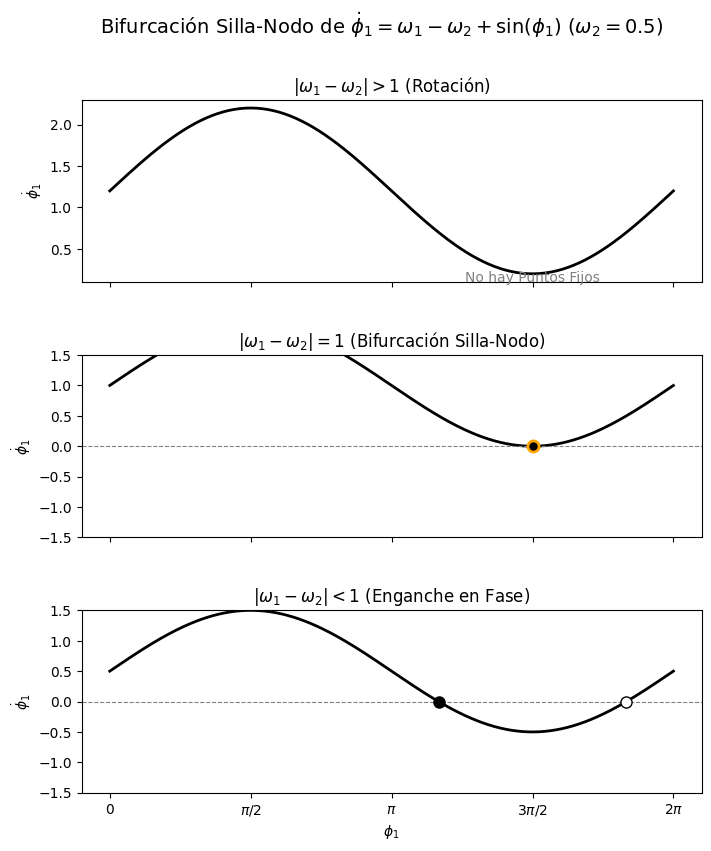

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros Base
OMEGA_2 = 0.5
PHI_RANGE = np.linspace(0, 2 * np.pi, 300)

# Función de la derivada de fase
def phi_dot_1(phi_1, omega_1, omega_2):
    return omega_1 - omega_2 + np.sin(phi_1)

# --- Definición de los Casos de Bifurcación ---
# 1. Rotación (No Enganchado): |w1 - w2| > 1
OMEGA_1_ROTATION = OMEGA_2 + 1.2 # w1 = 1.7. w1 - w2 = 1.2 > 1
LABEL_ROTATION = r'$|\omega_1 - \omega_2| > 1$ (Rotación)'

# 2. Bifurcación Silla-Nodo: |w1 - w2| = 1
OMEGA_1_BIFURCATION = OMEGA_2 + 1.0 # w1 = 1.5. w1 - w2 = 1.0
LABEL_BIFURCATION = r'$|\omega_1 - \omega_2| = 1$ (Bifurcación Silla-Nodo)'

# 3. Enganche en Fase: |w1 - w2| < 1
OMEGA_1_LOCK = OMEGA_2 + 0.5 # w1 = 1.0. w1 - w2 = 0.5 < 1
LABEL_LOCK = r'$|\omega_1 - \omega_2| < 1$ (Enganche en Fase)'

# --- Graficación ---
fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
fig.suptitle(r'Bifurcación Silla-Nodo de $\dot{\phi}_1 = \omega_1 - \omega_2 + \sin(\phi_1)$ ($\omega_2=0.5$)', fontsize=14)
plt.subplots_adjust(hspace=0.4)

CASES = [
    (axes[0], OMEGA_1_ROTATION, LABEL_ROTATION),
    (axes[1], OMEGA_1_BIFURCATION, LABEL_BIFURCATION),
    (axes[2], OMEGA_1_LOCK, LABEL_LOCK)
]

for ax, w1, label in CASES:
    # Calcular la curva
    phi_dot = phi_dot_1(PHI_RANGE, w1, OMEGA_2)

    # Plotear la curva
    ax.plot(PHI_RANGE, phi_dot, 'k-', linewidth=2)

    # Línea horizontal phi_dot = 0
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)

    # Encontrar y plotear puntos fijos (donde phi_dot = 0)
    w_diff = w1 - OMEGA_2

    if np.abs(w_diff) > 1:
        # Caso 1: Rotación (No hay puntos fijos)
        ax.set_ylim(min(phi_dot) - 0.1, max(phi_dot) + 0.1)
        ax.text(3*np.pi/2, 0.1, "No hay Puntos Fijos", fontsize=10, color='gray', ha='center')

    elif np.abs(w_diff) == 1:
        # Caso 2: Bifurcación (Un punto fijo)
        # El punto fijo es en phi_1 = 3*pi/2
        pf_x = 3 * np.pi / 2
        ax.plot(pf_x, 0, 'o', markerfacecolor='k',
        markeredgecolor='orange', markersize=8, markeredgewidth=2,
        label='PF Inestable', zorder=5)
        ax.set_ylim(-1.5, 1.5)

    else: # |w1 - w2| < 1
        # Caso 3: Enganche en Fase (Dos puntos fijos)
        arcsin_val = np.arcsin(OMEGA_2 - w1)

        # Punto Estable (Sumidero): donde la curva tiene pendiente negativa
        pf_estable = np.pi - arcsin_val

        # Punto Inestable (Silla): donde la curva tiene pendiente positiva
        pf_inestable = arcsin_val if w1 < OMEGA_2 else 2 * np.pi + arcsin_val

        ax.plot(pf_estable, 0, 'ko', markerfacecolor='k', markersize=8, label='PF Estable')
        ax.plot(pf_inestable, 0, 'ko', markerfacecolor='w', markersize=8, label='PF Inestable')
        ax.set_ylim(-1.5, 1.5)

    ax.set_title(label, fontsize=12)
    ax.set_ylabel(r'$\dot{\phi}_1$')
    ax.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
    ax.set_xticklabels([r'$0$', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])

axes[2].set_xlabel(r'$\phi_1$')
plt.show()

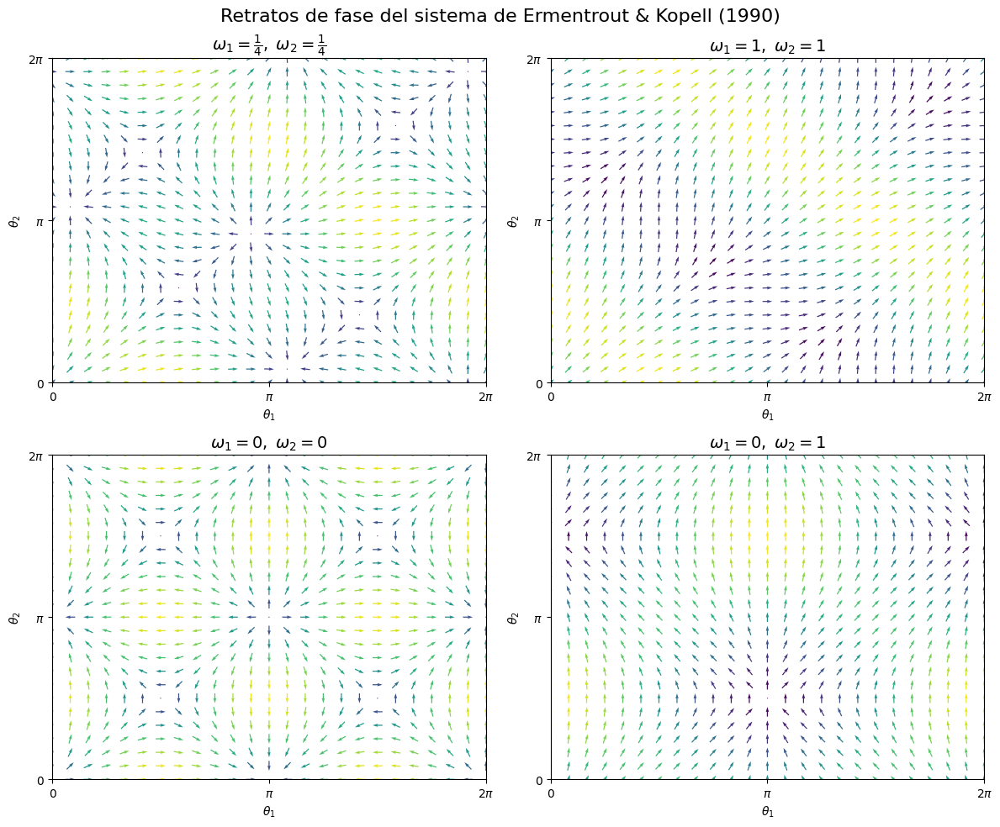

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Sistema del Ejercicio ---
def theta_dot(theta1, theta2, w1, w2):
    dtheta1 = w1 + np.sin(theta1) * np.cos(theta2)
    dtheta2 = w2 + np.sin(theta2) * np.cos(theta1)
    return dtheta1, dtheta2

# --- Rango del toro T² ---
N = 25  # resolución del campo
theta1_vals = np.linspace(0, 2*np.pi, N)
theta2_vals = np.linspace(0, 2*np.pi, N)

TH1, TH2 = np.meshgrid(theta1_vals, theta2_vals)

# --- Conjuntos de parámetros (CORREGIDOS) ---
param_sets = [
    (1/4, 1/4, r'$\omega_1=\frac{1}{4},\; \omega_2=\frac{1}{4}$'),
    (1, 1,     r'$\omega_1=1,\; \omega_2=1$'),
    (0, 0,     r'$\omega_1=0,\; \omega_2=0$'),
    (0, 1,     r'$\omega_1=0,\; \omega_2=1$')
]

# --- Crear figura ---
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (w1, w2, title) in zip(axes, param_sets):

    # Campo de flujo
    D1, D2 = theta_dot(TH1, TH2, w1, w2)

    # Normalización para mejor dibujo
    mag = np.sqrt(D1**2 + D2**2)
    D1n = D1 / (mag + 1e-6)
    D2n = D2 / (mag + 1e-6)

    ax.quiver(TH1, TH2, D1n, D2n, mag, cmap="viridis", pivot="mid")

    ax.set_title(title, fontsize=14)
    ax.set_xlabel(r'$\theta_1$')
    ax.set_ylabel(r'$\theta_2$')

    ax.set_xlim(0, 2*np.pi)
    ax.set_ylim(0, 2*np.pi)

    ax.set_xticks([0, np.pi, 2*np.pi])
    ax.set_xticklabels(['0', r'$\pi$', r'$2\pi$'])

    ax.set_yticks([0, np.pi, 2*np.pi])
    ax.set_yticklabels(['0', r'$\pi$', r'$2\pi$'])

plt.suptitle("Retratos de fase del sistema de Ermentrout & Kopell (1990)", fontsize=16)
plt.tight_layout()
plt.show()


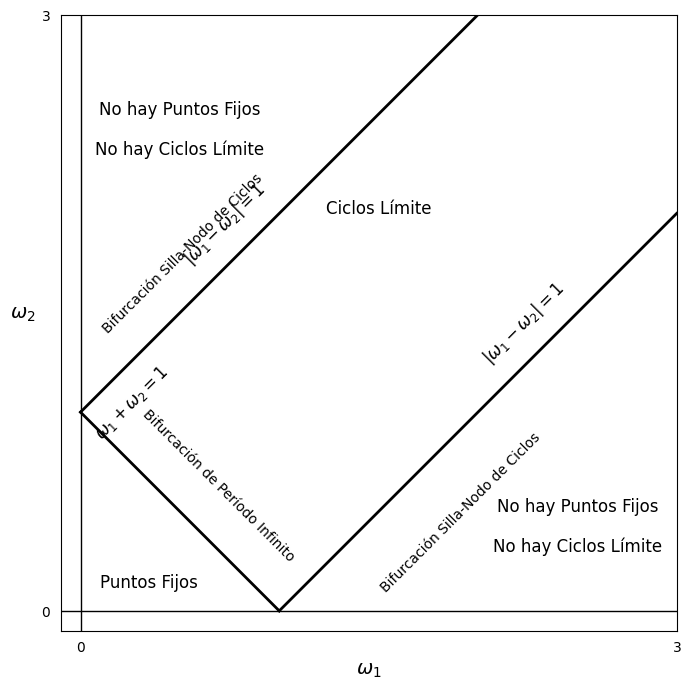

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Configuración del Gráfico ---
FIG_SIZE = 8
W_MAX = 3.0
W_RANGE = np.linspace(0, W_MAX, 100)

# Inicializar figura
fig, ax = plt.subplots(figsize=(FIG_SIZE, FIG_SIZE))

# --- 2. Definición de las Curvas de Bifurcación ---

# A. Bifurcación de Período Infinito (Homoclínica) - Curva 1
# Ecuación: w1 + w2 = 1
w2_inf_period = 1 - W_RANGE
w1_inf_period = W_RANGE[w2_inf_period >= 0]
w2_inf_period = w2_inf_period[w2_inf_period >= 0]

# B. Bifurcaciones Silla-Nodo de Enganche en Fase - Curvas 2 y 3
# Ecuación: |w1 - w2| = 1

# Curva 2: w2 = w1 - 1  (w1 > w2)
w2_saddle_node_a = W_RANGE - 1
w1_saddle_node_a = W_RANGE[w2_saddle_node_a >= 0]
w2_saddle_node_a = w2_saddle_node_a[w2_saddle_node_a >= 0]

# Curva 3: w2 = w1 + 1  (w2 > w1)
w2_saddle_node_b = W_RANGE + 1
w1_saddle_node_b = W_RANGE[w2_saddle_node_b <= W_MAX]
w2_saddle_node_b = w2_saddle_node_b[w2_saddle_node_b <= W_MAX]


# --- 3. Plotear las Líneas ---

# Líneas de Ejes (w1 y w2 >= 0)
ax.axhline(0, color='k', linewidth=1)
ax.axvline(0, color='k', linewidth=1)

# 1. Línea de Período Infinito (w1 + w2 = 1)
ax.plot(w1_inf_period, w2_inf_period, 'k-', linewidth=2)
# Etiquetas traducidas
ax.text(0.1, 0.1, r'Puntos Fijos', ha='left', va='bottom', fontsize=12)
ax.text(0.3, 0.25, r'Bifurcación de Período Infinito', rotation=-45, fontsize=10)
ax.text(0.05, 1.05, r'$\omega_1 + \omega_2 = 1$', ha='left', va='center', fontsize=12, rotation=45)


# 2. Línea Silla-Nodo Inferior (w2 = w1 - 1)
ax.plot(w1_saddle_node_a, w2_saddle_node_a, 'k-', linewidth=2)
ax.text(2.0, 1.25, r'$|\omega_1 - \omega_2| = 1$', rotation=45, fontsize=12)
ax.text(1.5, 0.1, r'Bifurcación Silla-Nodo de Ciclos', rotation=45, fontsize=10)


# 3. Línea Silla-Nodo Superior (w2 = w1 + 1)
ax.plot(w1_saddle_node_b, w2_saddle_node_b, 'k-', linewidth=2)
ax.text(0.5, 1.75, r'$|\omega_1 - \omega_2| = 1$', rotation=45, fontsize=12)
ax.text(0.1, 1.4, r'Bifurcación Silla-Nodo de Ciclos', rotation=45, fontsize=10)


# --- 4. Etiquetas de Regiones (Traducidas) ---

# Región Central (Ciclos Límite / Enganche en Fase)
ax.text(1.5, 2.0, r'Ciclos Límite', ha='center', fontsize=12)

# Región Inferior Derecha (Rotación Pura)
ax.text(2.5, 0.5, r'No hay Puntos Fijos', ha='center', fontsize=12)
ax.text(2.5, 0.3, r'No hay Ciclos Límite', ha='center', fontsize=12)

# Región Superior Izquierda (Rotación Pura)
ax.text(0.5, 2.5, r'No hay Puntos Fijos', ha='center', fontsize=12)
ax.text(0.5, 2.3, r'No hay Ciclos Límite', ha='center', fontsize=12)


# --- 5. Configuración Final ---
ax.set_xlim(-0.1, W_MAX)
ax.set_ylim(-0.1, W_MAX)
ax.set_xlabel(r'$\omega_1$', fontsize=14)
ax.set_ylabel(r'$\omega_2$', fontsize=14, rotation=0, ha='right')
ax.set_aspect('equal', adjustable='box')
ax.tick_params(left=False, bottom=False, labelleft=True, labelbottom=True)
ax.set_xticks([0, W_MAX])
ax.set_yticks([0, W_MAX])
ax.set_xticklabels([r'$0$', r'$3$'])
ax.set_yticklabels([r'$0$', r'$3$'])

plt.show()